# **Pengolahan dan Analisis Data Publikasi Kesejahteraan Rakyat Kabupaten Tapanuli Utara Berdasarkan Hasil Survei Sosial Ekonomi Nasional (SUSENAS) Tahun 2023–2025**

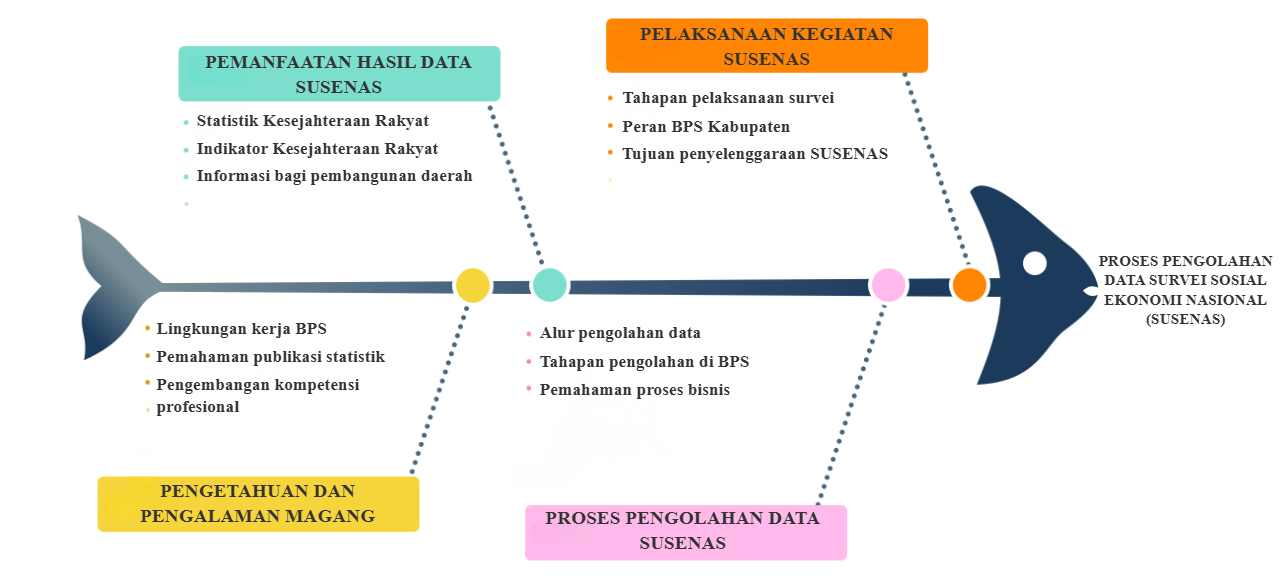

## **STEP 1: Import Library**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.style.use("ggplot")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

print("Semua library berhasil diimport")

Semua library berhasil diimport


## **STEP 2: Upload Data**

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving dataset_kesejahteraan_rakyat_taput_2023_2024_2025.xlsx to dataset_kesejahteraan_rakyat_taput_2023_2024_2025 (1).xlsx


In [ ]:
file = "dataset_kesejahteraan_rakyat_taput_2023_2024_2025.xlsx"
excel = pd.ExcelFile(file)

print(excel.sheet_names)

['partisipasi sekolah', 'pendidikan tertinggi', 'angka kesakitan', 'kepemilikan bangunan', 'sumber air', 'teknologi informasi', 'jenis aset', 'pengeluaran']


## **STEP 3: Reading All Worksheets**

In [ ]:
datasets = {}
for sheet in excel.sheet_names:
    datasets[sheet] = pd.read_excel(
        file, sheet_name=sheet)

print("Jumlah dataset :",len(datasets))

Jumlah dataset : 8


## **STEP 4: Data Understanding**

In [ ]:
for nama,df in datasets.items():
    print("="*60)
    print(nama.upper())
    print("="*60)

    print(df.head())
    print()

    print(df.info())
    print()

    print(df.isnull().sum())
    print("\n")

PARTISIPASI SEKOLAH
    Tahun           Karakteristik  Tidak/Belum Sekolah  Masih Sekolah  \
0  2023.0           Jenis Kelamin                  NaN            NaN   
1     NaN               Laki-Laki                 4.78          28.86   
2     NaN               Perempuan                 3.48          28.93   
3     NaN  Distribusi Pengeluaran                  NaN            NaN   
4     NaN      40 Persen Terbawah                 7.26          37.55   

   Tidak Sekolah Lagi  
0                 NaN  
1               66.36  
2               67.58  
3                 NaN  
4               55.18  

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Tahun                3 non-null      float64
 1   Karakteristik        24 non-null     object 
 2   Tidak/Belum Sekolah  16 non-null     float64
 3   Masih Sekolah        18 non-null     fl

## **STEP 5: Data Cleaning**

### **1. Mengisi Kolom Tahun**

In [ ]:
def isi_tahun(df):
    df["Tahun"] = df["Tahun"].ffill()
    return df

### **2. Menghapus Baris Judul**

In [ ]:
def hapus_header(df, kolom, daftar):
    df = df[~df[kolom].isin(daftar)]
    df.reset_index(drop=True,inplace=True)
    return df

### **3. Membersihkan Dataset Partisipasi Sekolah**

In [ ]:
df_sekolah = datasets["partisipasi sekolah"].copy()
df_sekolah = isi_tahun(df_sekolah)

hapus = ["Jenis Kelamin", "Distribusi Pengeluaran"]

df_sekolah = hapus_header(
    df_sekolah, "Karakteristik", hapus)

df_sekolah

,Tahun,Karakteristik,Tidak/Belum Sekolah,Masih Sekolah,Tidak Sekolah Lagi
0,2023.0,Laki-Laki,4.78,28.86,66.36
1,2023.0,Perempuan,3.48,28.93,67.58
2,2023.0,40 Persen Terbawah,7.26,37.55,55.18
3,2023.0,40 Persen Menengah,2.22,27.34,70.45
4,2023.0,20 Persen Teratas,2.11,15.84,82.05
5,2023.0,Tapanuli Utara,4.13,28.89,66.98
6,2024.0,Laki-Laki,3.03,31.13,65.84
7,2024.0,Perempuan,2.32,29.60,68.08
8,2024.0,40 Persen Terbawah,4.24,40.32,55.44
9,2024.0,40 Persen Menengah,2.19,28.46,69.34


### **4. Membersihkan Dataset Pendidikan Tertinggi**

In [ ]:
df_pendidikan = datasets["pendidikan tertinggi"].copy()
df_pendidikan = isi_tahun(df_pendidikan)

hapus = ["Jenis Kelamin", "Kelompok Pengeluaran"]

df_pendidikan = hapus_header(
    df_pendidikan, "Karakteristik", hapus)

df_pendidikan

,Tahun,Karakteristik,Tidak Punya Ijazah SD,SD/sederajat,SMP/sederajat,SMA/ke atas
0,2023.0,Laki-Laki,7.17,12.54,26.22,54.07
1,2023.0,Perempuan,9.08,16.76,20.39,53.77
2,2023.0,40 Persen Terbawah,9.58,11.73,27.06,51.63
3,2023.0,40 Persen Menengah,9.52,18.06,22.88,49.54
4,2023.0,20 Persen Teratas,3.62,12.43,18.83,65.12
5,2023.0,Tapanuli Utara,8.14,14.68,23.26,53.92
6,2024.0,Laki-Laki,2.28,14.27,28.16,55.29
7,2024.0,Perempuan,7.27,14.87,28.36,49.49
8,2024.0,40 Persen Terbawah,6.67,14.26,31.37,47.70
9,2024.0,40 Persen Menengah,4.17,16.97,29.52,49.34


### **5. Membersihkan Dataset Angka Kesakitan**

In [ ]:
df_sakit = datasets["angka kesakitan"].copy()
df_sakit = isi_tahun(df_sakit)

hapus=["Jenis Kelamin", "Distribusi Pengeluaran"]

df_sakit = hapus_header(
    df_sakit, "Karakteristik", hapus)

df_sakit

,Tahun,Karakteristik,Angka Kesakitan
0,2023.0,Laki-Laki,8.93
1,2023.0,Perempuan,7.26
2,2023.0,40 Persen Terbawah,5.95
3,2023.0,40 Persen Menengah,10.87
4,2023.0,20 Persen Teratas,6.81
5,2023.0,Tapanuli Utara,8.09
6,2024.0,Laki-Laki,7.05
7,2024.0,Perempuan,7.21
8,2024.0,40 Persen Terbawah,7.20
9,2024.0,40 Persen Menengah,7.81


### **6. Membersihkan Dataset Kepemilikan Bangunan**

In [ ]:
df_rumah = datasets["kepemilikan bangunan"].copy()
df_rumah = isi_tahun(df_rumah)
df_rumah.columns = ["Tahun", "Karakteristik", "Milik Sendiri", "Bukan Milik Sendiri"]

hapus=["Karakteristik", "Jenis Kelamin", "Kelompok Pengeluaran"]

df_rumah = hapus_header(
    df_rumah, "Karakteristik", hapus)

df_rumah

,Tahun,Karakteristik,Milik Sendiri,Bukan Milik Sendiri
0,2023.0,Laki-Laki,76.6,23.4
1,2023.0,Perempuan,87.26,12.74
2,2023.0,40 Persen Terbawah,77.25,22.75
3,2023.0,40 Persen Menengah,82.71,17.29
4,2023.0,20 Persen Teratas,71.97,28.03
5,2023.0,Pendidikan Tertinggi KRT,NaN,NaN
6,2023.0,SD ke bawah,90.91,9.09
7,2023.0,SMP ke atas,73.63,26.37
8,2023.0,Tapanuli Utara,78.2,28.3
9,2024.0,Laki-Laki,79.72,20.28


### **7. Membersihkan Dataset Sumber Air**

In [ ]:
df_air = datasets["sumber air"].copy()
df_air = isi_tahun(df_air)
df_air.columns = ["Tahun", "Karakteristik", "Air Kemasan/Leding", "Sumur/Mata Air", "Lainnya"]

hapus=["Karakteristik", "Jenis Kelamin KRT", "Distribusi Pengeluaran"]

df_air = hapus_header(
    df_air, "Karakteristik", hapus)

df_air

,Tahun,Karakteristik,Air Kemasan/Leding,Sumur/Mata Air,Lainnya
0,2023.0,Laki-Laki,8.36,86.38,5.26
1,2023.0,Perempuan,13.31,74.98,11.71
2,2023.0,40 Persen Terbawah,4.68,82.84,12.47
3,2023.0,40 Persen Menengah,4.38,91.79,3.83
4,2023.0,20 Persen Teratas,22.01,75.25,2.75
5,2023.0,Pendidikan Tertinggi KRT,NaN,NaN,NaN
6,2023.0,SD ke bawah,4.69,88.58,6.74
7,2023.0,SMP ke atas,10.68,83.28,6.04
8,2023.0,Tapanuli Utara,9.1,84.68,6.23
9,2024.0,Jenis Kelamin,NaN,NaN,NaN


### **8. Membersihkan Dataset Teknologi Informasi**

In [ ]:
df_it = datasets["teknologi informasi"].copy()
df_it = isi_tahun(df_it)
df_it.columns = ["Tahun", "Karakteristik", "Menggunakan HP", "Menggunakan Internet"]

hapus=["Karakteristik", "Jenis Kelamin KRT", "Kuintil Pengeluaran"]

df_it = hapus_header(
    df_it, "Karakteristik", hapus)

df_it

,Tahun,Karakteristik,Menggunakan HP,Menggunakan Internet
0,2023.0,Laki-Laki,91.85,74.1
1,2023.0,Perempuan,84.44,55.19
2,2023.0,40 Persen Terbawah,87.45,66.48
3,2023.0,40 Persen Menengah,91.44,71.34
4,2023.0,20 Persen Teratas,96.95,83.74
5,2023.0,Pendidikan Tertinggi KRT,NaN,NaN
6,2023.0,SD ke bawah,83.59,58.37
7,2023.0,SMP ke atas,96.02,81.15
8,2023.0,Tapanuli Utara,91.04,72.03
9,2024.0,Laki-Laki,88.54,75.48


### **9. Membersihkan Dataset Jenis Aset**

In [ ]:
df_aset = datasets["jenis aset"].copy()
df_aset = isi_tahun(df_aset)
df_aset

,Tahun,Jenis Aset,Persentase Rumah Tangga
0,2023.0,Aset Fasilitas Rumah Tangga,56.01
1,2023.0,Aset Transportasi,77.06
2,2024.0,Aset Fasilitas Rumah Tangga,55.46
3,2024.0,Aset Transportasi,74.78
4,2025.0,Aset Fasilitas Rumah Tangga,55.33
5,2025.0,Aset Transportasi,79.67


### **10. Membersihkan Dataset Pengeluaran**

In [ ]:
df_pengeluaran = datasets["pengeluaran"].copy()
df_pengeluaran = isi_tahun(df_pengeluaran)
df_pengeluaran.columns = ["Tahun", "Komoditas", "40% Terbawah", "40% Menengah", "20% Teratas", "Total"]

df_pengeluaran = df_pengeluaran.dropna(subset=["Komoditas"])
df_pengeluaran.reset_index(drop=True,inplace=True)
df_pengeluaran

,Tahun,Komoditas,40% Terbawah,40% Menengah,20% Teratas,Total
0,2023.0,Jumlah Makanan,488757,735405,1232029,736165
1,2023.0,Jumlah Bukan Makanan,213864,350784,897328,405465
2,2023.0,Rata-Rata Pengeluaran Tapanuli Utara,702621,1086189,2129357,1141630
3,2024.0,Jumlah Makanan,504859,715120,1195434,726673
4,2024.0,Jumlah Bukan Makanan,231531,361928,851981,407441
5,2024.0,Rata-Rata Pengeluaran Tapanuli Utara,736390,1077048,2047415,1134114
6,2025.0,Jumlah Makanan,535742,798786,1266736,787236
7,2025.0,Jumlah Bukan Makanan,244135,399583,947791,447098
8,2025.0,Rata-Rata Pengeluaran Tapanuli Utara,779877,1198369,2214527,1234334


## **STEP 6: Checking the Cleaning Results**

In [ ]:
clean_data = {
    "Partisipasi Sekolah":df_sekolah,
    "Pendidikan":df_pendidikan,
    "Kesakitan":df_sakit,
    "Rumah":df_rumah,
    "Air":df_air,
    "IT":df_it,
    "Aset":df_aset,
    "Pengeluaran":df_pengeluaran
}

for nama,df in clean_data.items():
    print("="*60)
    print(nama)
    print("="*60)

    print(df.head())
    print()

    print(df.isnull().sum())
    print()

Partisipasi Sekolah
    Tahun       Karakteristik  Tidak/Belum Sekolah  Masih Sekolah  \
0  2023.0           Laki-Laki                 4.78          28.86   
1  2023.0           Perempuan                 3.48          28.93   
2  2023.0  40 Persen Terbawah                 7.26          37.55   
3  2023.0  40 Persen Menengah                 2.22          27.34   
4  2023.0   20 Persen Teratas                 2.11          15.84   

   Tidak Sekolah Lagi  
0               66.36  
1               67.58  
2               55.18  
3               70.45  
4               82.05  

Tahun                  0
Karakteristik          0
Tidak/Belum Sekolah    2
Masih Sekolah          0
Tidak Sekolah Lagi     0
dtype: int64

Pendidikan
    Tahun       Karakteristik  Tidak Punya Ijazah SD  SD/sederajat  \
0  2023.0           Laki-Laki                   7.17         12.54   
1  2023.0           Perempuan                   9.08         16.76   
2  2023.0  40 Persen Terbawah                   9.58        

## **STEP 7: Data Transformation**

### **1. Convert Data Types**

In [ ]:
def convert_numeric(df):

    for col in df.columns:
        if col != "Karakteristik" and col != "Komoditas" and col != "Jenis Aset":
            df[col] = pd.to_numeric(df[col], errors="coerce")

    return df

In [ ]:
df_sekolah = convert_numeric(df_sekolah)
df_pendidikan = convert_numeric(df_pendidikan)
df_sakit = convert_numeric(df_sakit)
df_rumah = convert_numeric(df_rumah)
df_air = convert_numeric(df_air)
df_it = convert_numeric(df_it)
df_aset = convert_numeric(df_aset)
df_pengeluaran = convert_numeric(df_pengeluaran)

### **2. Data Type Verification**

In [ ]:
for nama,df in clean_data.items():
    print("="*50)
    print(nama)
    print("="*50)

    print(df.dtypes)

Partisipasi Sekolah
Tahun                  float64
Karakteristik           object
Tidak/Belum Sekolah    float64
Masih Sekolah          float64
Tidak Sekolah Lagi     float64
dtype: object
Pendidikan
Tahun                    float64
Karakteristik             object
Tidak Punya Ijazah SD    float64
SD/sederajat             float64
SMP/sederajat            float64
SMA/ke atas              float64
dtype: object
Kesakitan
Tahun              float64
Karakteristik       object
Angka Kesakitan    float64
dtype: object
Rumah
Tahun                  float64
Karakteristik           object
Milik Sendiri          float64
Bukan Milik Sendiri    float64
dtype: object
Air
Tahun                 float64
Karakteristik          object
Air Kemasan/Leding    float64
Sumur/Mata Air        float64
Lainnya               float64
dtype: object
IT
Tahun                   float64
Karakteristik            object
Menggunakan HP          float64
Menggunakan Internet    float64
dtype: object
Aset
Tahun                

### **3. Missing Value Verification**

In [ ]:
for nama,df in clean_data.items():
    print("="*50)
    print(nama)

    print(df.isnull().sum())

Partisipasi Sekolah
Tahun                  0
Karakteristik          0
Tidak/Belum Sekolah    2
Masih Sekolah          0
Tidak Sekolah Lagi     0
dtype: int64
Pendidikan
Tahun                    0
Karakteristik            0
Tidak Punya Ijazah SD    1
SD/sederajat             0
SMP/sederajat            0
SMA/ke atas              0
dtype: int64
Kesakitan
Tahun              0
Karakteristik      0
Angka Kesakitan    0
dtype: int64
Rumah
Tahun                  0
Karakteristik          0
Milik Sendiri          3
Bukan Milik Sendiri    4
dtype: int64
Air
Tahun                 0
Karakteristik         0
Air Kemasan/Leding    6
Sumur/Mata Air        5
Lainnya               5
dtype: int64
IT
Tahun                   0
Karakteristik           0
Menggunakan HP          3
Menggunakan Internet    3
dtype: int64
Aset
Tahun                      0
Jenis Aset                 0
Persentase Rumah Tangga    0
dtype: int64
Pengeluaran
Tahun           0
Komoditas       0
40% Terbawah    0
40% Menengah    0
20% T

### **4.	Descriptive Statistics**

In [ ]:
for nama,df in clean_data.items():
    print("="*60)
    print(nama.upper())
    print("="*60)

    print(df.describe())

PARTISIPASI SEKOLAH
             Tahun  Tidak/Belum Sekolah  Masih Sekolah  Tidak Sekolah Lagi
count    18.000000            16.000000      18.000000           18.000000
mean   2024.000000             3.240625      28.298333           68.755556
std       0.840168             1.462826       7.075193            8.391848
min    2023.000000             1.440000      15.570000           54.960000
25%    2023.000000             2.242500      27.190000           66.512500
50%    2024.000000             2.660000      28.875000           67.830000
75%    2025.000000             4.157500      30.212500           70.570000
max    2025.000000             7.260000      40.420000           83.740000
PENDIDIKAN
             Tahun  Tidak Punya Ijazah SD  SD/sederajat  SMP/sederajat  \
count    18.000000              17.000000     18.000000      18.000000   
mean   2024.000000               5.933529     13.363889      25.810556   
std       0.840168               2.226367      2.543199       4.117494  

### **5.	Export Dataset Final Taput**


In [ ]:
with pd.ExcelWriter("dataset_final_taput.xlsx") as writer:

    df_sekolah.to_excel(writer,
                        sheet_name="Partisipasi Sekolah",
                        index=False)

    df_pendidikan.to_excel(writer,
                           sheet_name="Pendidikan",
                           index=False)

    df_sakit.to_excel(writer,
                      sheet_name="Kesakitan",
                      index=False)

    df_rumah.to_excel(writer,
                      sheet_name="Rumah",
                      index=False)

    df_air.to_excel(writer,
                    sheet_name="Air",
                    index=False)

    df_it.to_excel(writer,
                   sheet_name="Teknologi",
                   index=False)

    df_aset.to_excel(writer,
                     sheet_name="Aset",
                     index=False)

    df_pengeluaran.to_excel(writer,
                            sheet_name="Pengeluaran",
                            index=False)

print("Dataset berhasil disimpan.")

Dataset berhasil disimpan.


### **6.	Download Dataset Final Taput**

In [ ]:
from google.colab import files
files.download("dataset_final_taput.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **STEP 8: Exploratory Data Analysis (EDA)**

### **1. Memuat Dataset Final Taput**

In [ ]:
file="dataset_final_taput.xlsx"

excel=pd.ExcelFile(file)
excel.sheet_names

['Partisipasi Sekolah',
 'Pendidikan',
 'Kesakitan',
 'Rumah',
 'Air',
 'Teknologi',
 'Aset',
 'Pengeluaran']

In [ ]:
file_excel = "dataset_final_taput.xlsx"
sheets = pd.read_excel(file_excel, sheet_name=None)

print(sheets.keys())

dict_keys(['Partisipasi Sekolah', 'Pendidikan', 'Kesakitan', 'Rumah', 'Air', 'Teknologi', 'Aset', 'Pengeluaran'])


### **2. Membaca seluruh Sheet**

In [ ]:
sekolah=pd.read_excel(file,sheet_name="Partisipasi Sekolah")

pendidikan=pd.read_excel(file,sheet_name="Pendidikan")

sakit=pd.read_excel(file,sheet_name="Kesakitan")

rumah=pd.read_excel(file,sheet_name="Rumah")

air=pd.read_excel(file,sheet_name="Air")

it=pd.read_excel(file,sheet_name="Teknologi")

aset=pd.read_excel(file,sheet_name="Aset")

pengeluaran=pd.read_excel(file,sheet_name="Pengeluaran")

### **3. Mengecek seluruh Sheet**

In [ ]:
print(sekolah.head())

print(pendidikan.head())

print(sakit.head())

print(rumah.head())

print(air.head())

print(it.head())

print(aset.head())

print(pengeluaran.head())

   Tahun       Karakteristik  Tidak/Belum Sekolah  Masih Sekolah  \
0   2023           Laki-Laki                 4.78          28.86   
1   2023           Perempuan                 3.48          28.93   
2   2023  40 Persen Terbawah                 7.26          37.55   
3   2023  40 Persen Menengah                 2.22          27.34   
4   2023   20 Persen Teratas                 2.11          15.84   

   Tidak Sekolah Lagi  
0               66.36  
1               67.58  
2               55.18  
3               70.45  
4               82.05  
   Tahun       Karakteristik  Tidak Punya Ijazah SD  SD/sederajat  \
0   2023           Laki-Laki                   7.17         12.54   
1   2023           Perempuan                   9.08         16.76   
2   2023  40 Persen Terbawah                   9.58         11.73   
3   2023  40 Persen Menengah                   9.52         18.06   
4   2023   20 Persen Teratas                   3.62         12.43   

   SMP/sederajat  SMA/ke atas  


### **4. Ringkasan Dataset**

In [ ]:
ringkasan = []
for nama, df in clean_data.items():

    ringkasan.append({
        "Dataset": nama, "Jumlah Baris": df.shape[0], "Jumlah Kolom": df.shape[1]
    })

ringkasan = pd.DataFrame(ringkasan)
ringkasan

,Dataset,Jumlah Baris,Jumlah Kolom
0,Partisipasi Sekolah,18,5
1,Pendidikan,18,6
2,Kesakitan,18,3
3,Rumah,27,4
4,Air,29,5
5,IT,27,4
6,Aset,6,3
7,Pengeluaran,9,6


### **VISUALISASI 1: Tingkat Partisipasi Sekolah**

#### **a. Persentase Penduduk Tidak/Belum Sekolah Menurut Jenis Kelamin Tahun 2023–2025**

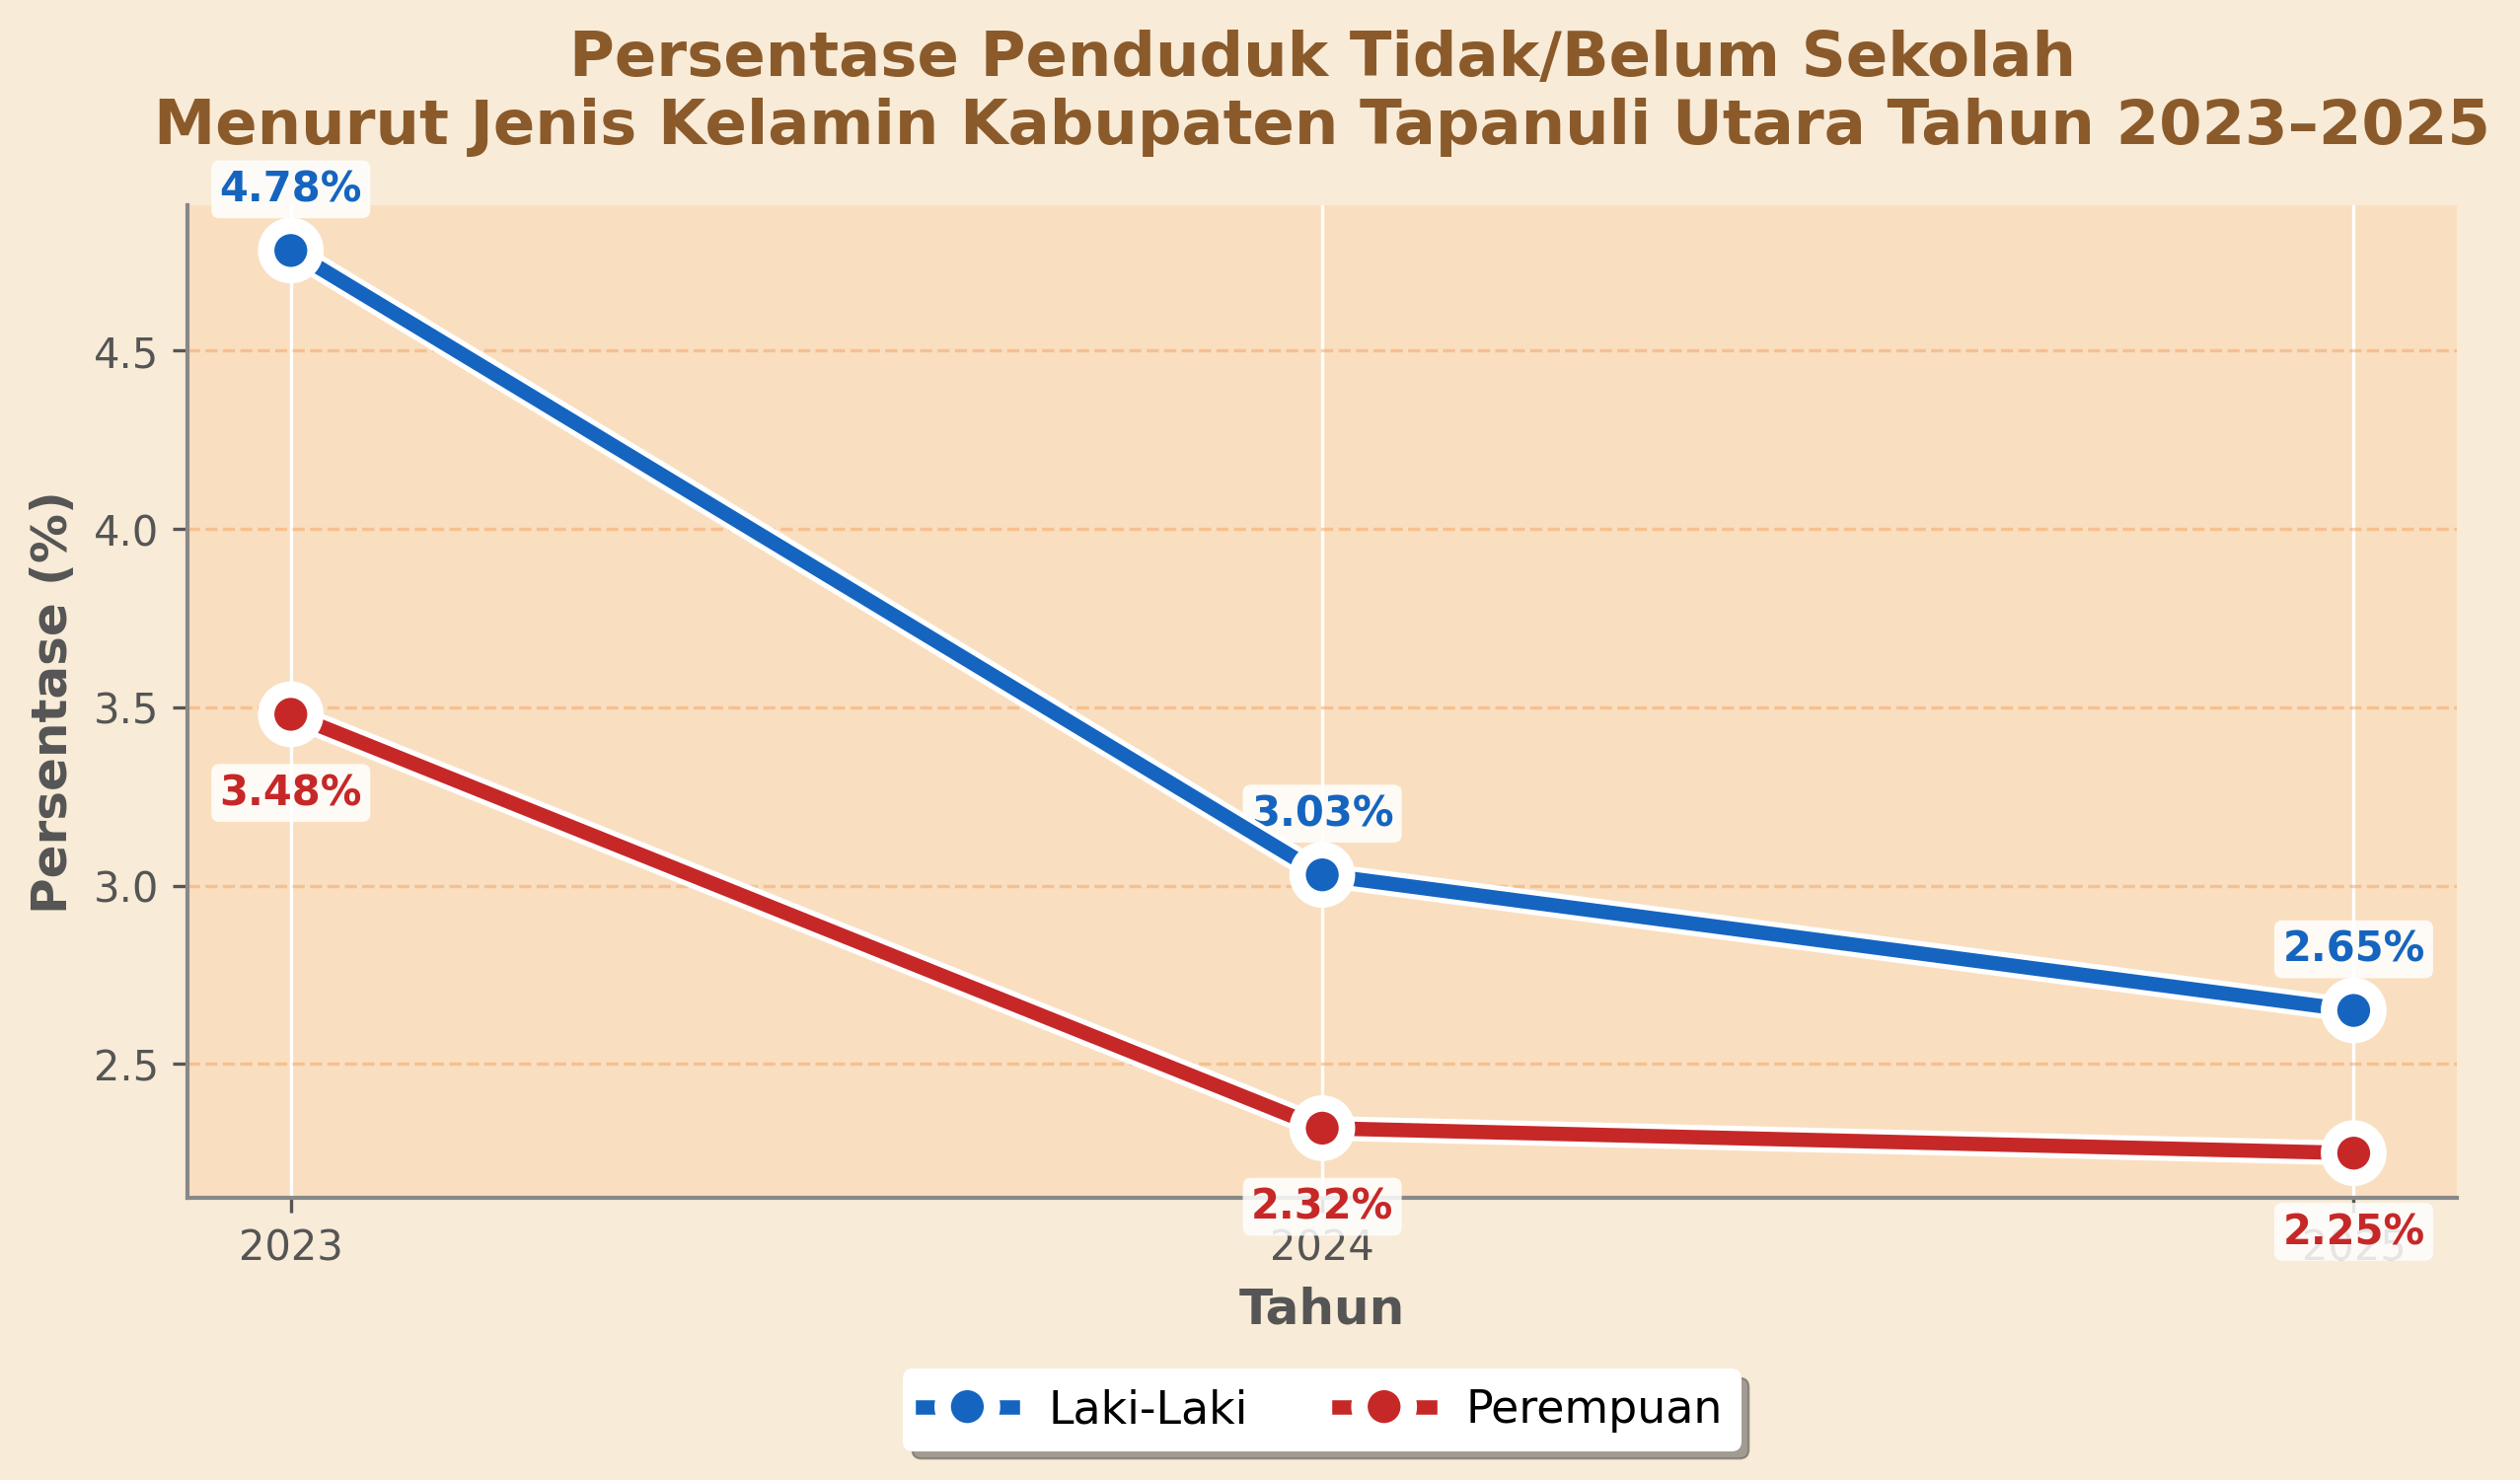

In [ ]:
df = sheets["Partisipasi Sekolah"].copy()
df["Karakteristik"] = df["Karakteristik"].str.strip()
df = df[df["Karakteristik"].isin(["Laki-Laki","Perempuan"])]

laki = df[df["Karakteristik"]=="Laki-Laki"].sort_values("Tahun")
perempuan = df[df["Karakteristik"]=="Perempuan"].sort_values("Tahun")

fig, ax = plt.subplots(figsize=(8.5,5.2), dpi=300)
fig.patch.set_facecolor("#F8EBD7")
ax.set_facecolor("#F9DFC0")

biru = "#1565C0"
merah = "#C62828"
orange = "#8B5A2B"

line1, = ax.plot(
    laki["Tahun"],
    laki["Tidak/Belum Sekolah"],
    color=biru,
    linewidth=3.5,
    marker="o",
    markersize=10,
    markeredgecolor="white",
    markeredgewidth=2,
    label="Laki-Laki",
    zorder=5
)

line2, = ax.plot(
    perempuan["Tahun"],
    perempuan["Tidak/Belum Sekolah"],
    color=merah,
    linewidth=3.5,
    marker="o",
    markersize=10,
    markeredgecolor="white",
    markeredgewidth=2,
    label="Perempuan",
    zorder=5
)

for line in [line1, line2]:
    line.set_path_effects([
        pe.Stroke(linewidth=6, foreground="white"),
        pe.Normal()
    ])

for x,y in zip(laki["Tahun"], laki["Tidak/Belum Sekolah"]):
    ax.annotate(
        f"{y:.2f}%",
        (x,y),
        xytext=(0,12),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=biru,
        bbox=dict(
            boxstyle="round,pad=0.2",
            fc="white",
            ec="none",
            alpha=0.85
        )
    )

for x,y in zip(perempuan["Tahun"], perempuan["Tidak/Belum Sekolah"]):
    ax.annotate(
        f"{y:.2f}%",
        (x,y),
        xytext=(0,-22),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=merah,
        bbox=dict(
            boxstyle="round,pad=0.2",
            fc="white",
            ec="none",
            alpha=0.85
        )
    )

ax.set_xticks([2023,2024,2025])

ax.set_xlabel(
    "Tahun",
    fontsize=12,
    fontweight="bold",
    color="#555555"
)

ax.set_ylabel(
    "Persentase (%)",
    fontsize=12,
    fontweight="bold",
    color="#555555"
)

ax.set_title(
    "Persentase Penduduk Tidak/Belum Sekolah\n"
    "Menurut Jenis Kelamin Kabupaten Tapanuli Utara Tahun 2023–2025",
    fontsize=15,
    fontweight="bold",
    color=orange,
    pad=15
)

ax.grid(
    axis="y",
    linestyle="--",
    color="#F4A261",
    alpha=0.5
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("#888888")
ax.spines["bottom"].set_color("#888888")

legend = ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5,-0.15),
    ncol=2,
    frameon=True,
    fancybox=True,
    shadow=True,
    fontsize=11
)

legend.get_frame().set_facecolor("white")
legend.get_frame().set_edgecolor("white")

plt.tight_layout()
plt.show()

#### **b. Persentase Penduduk Masih Sekolah Menurut Jenis Kelamin Tahun 2023–2025**

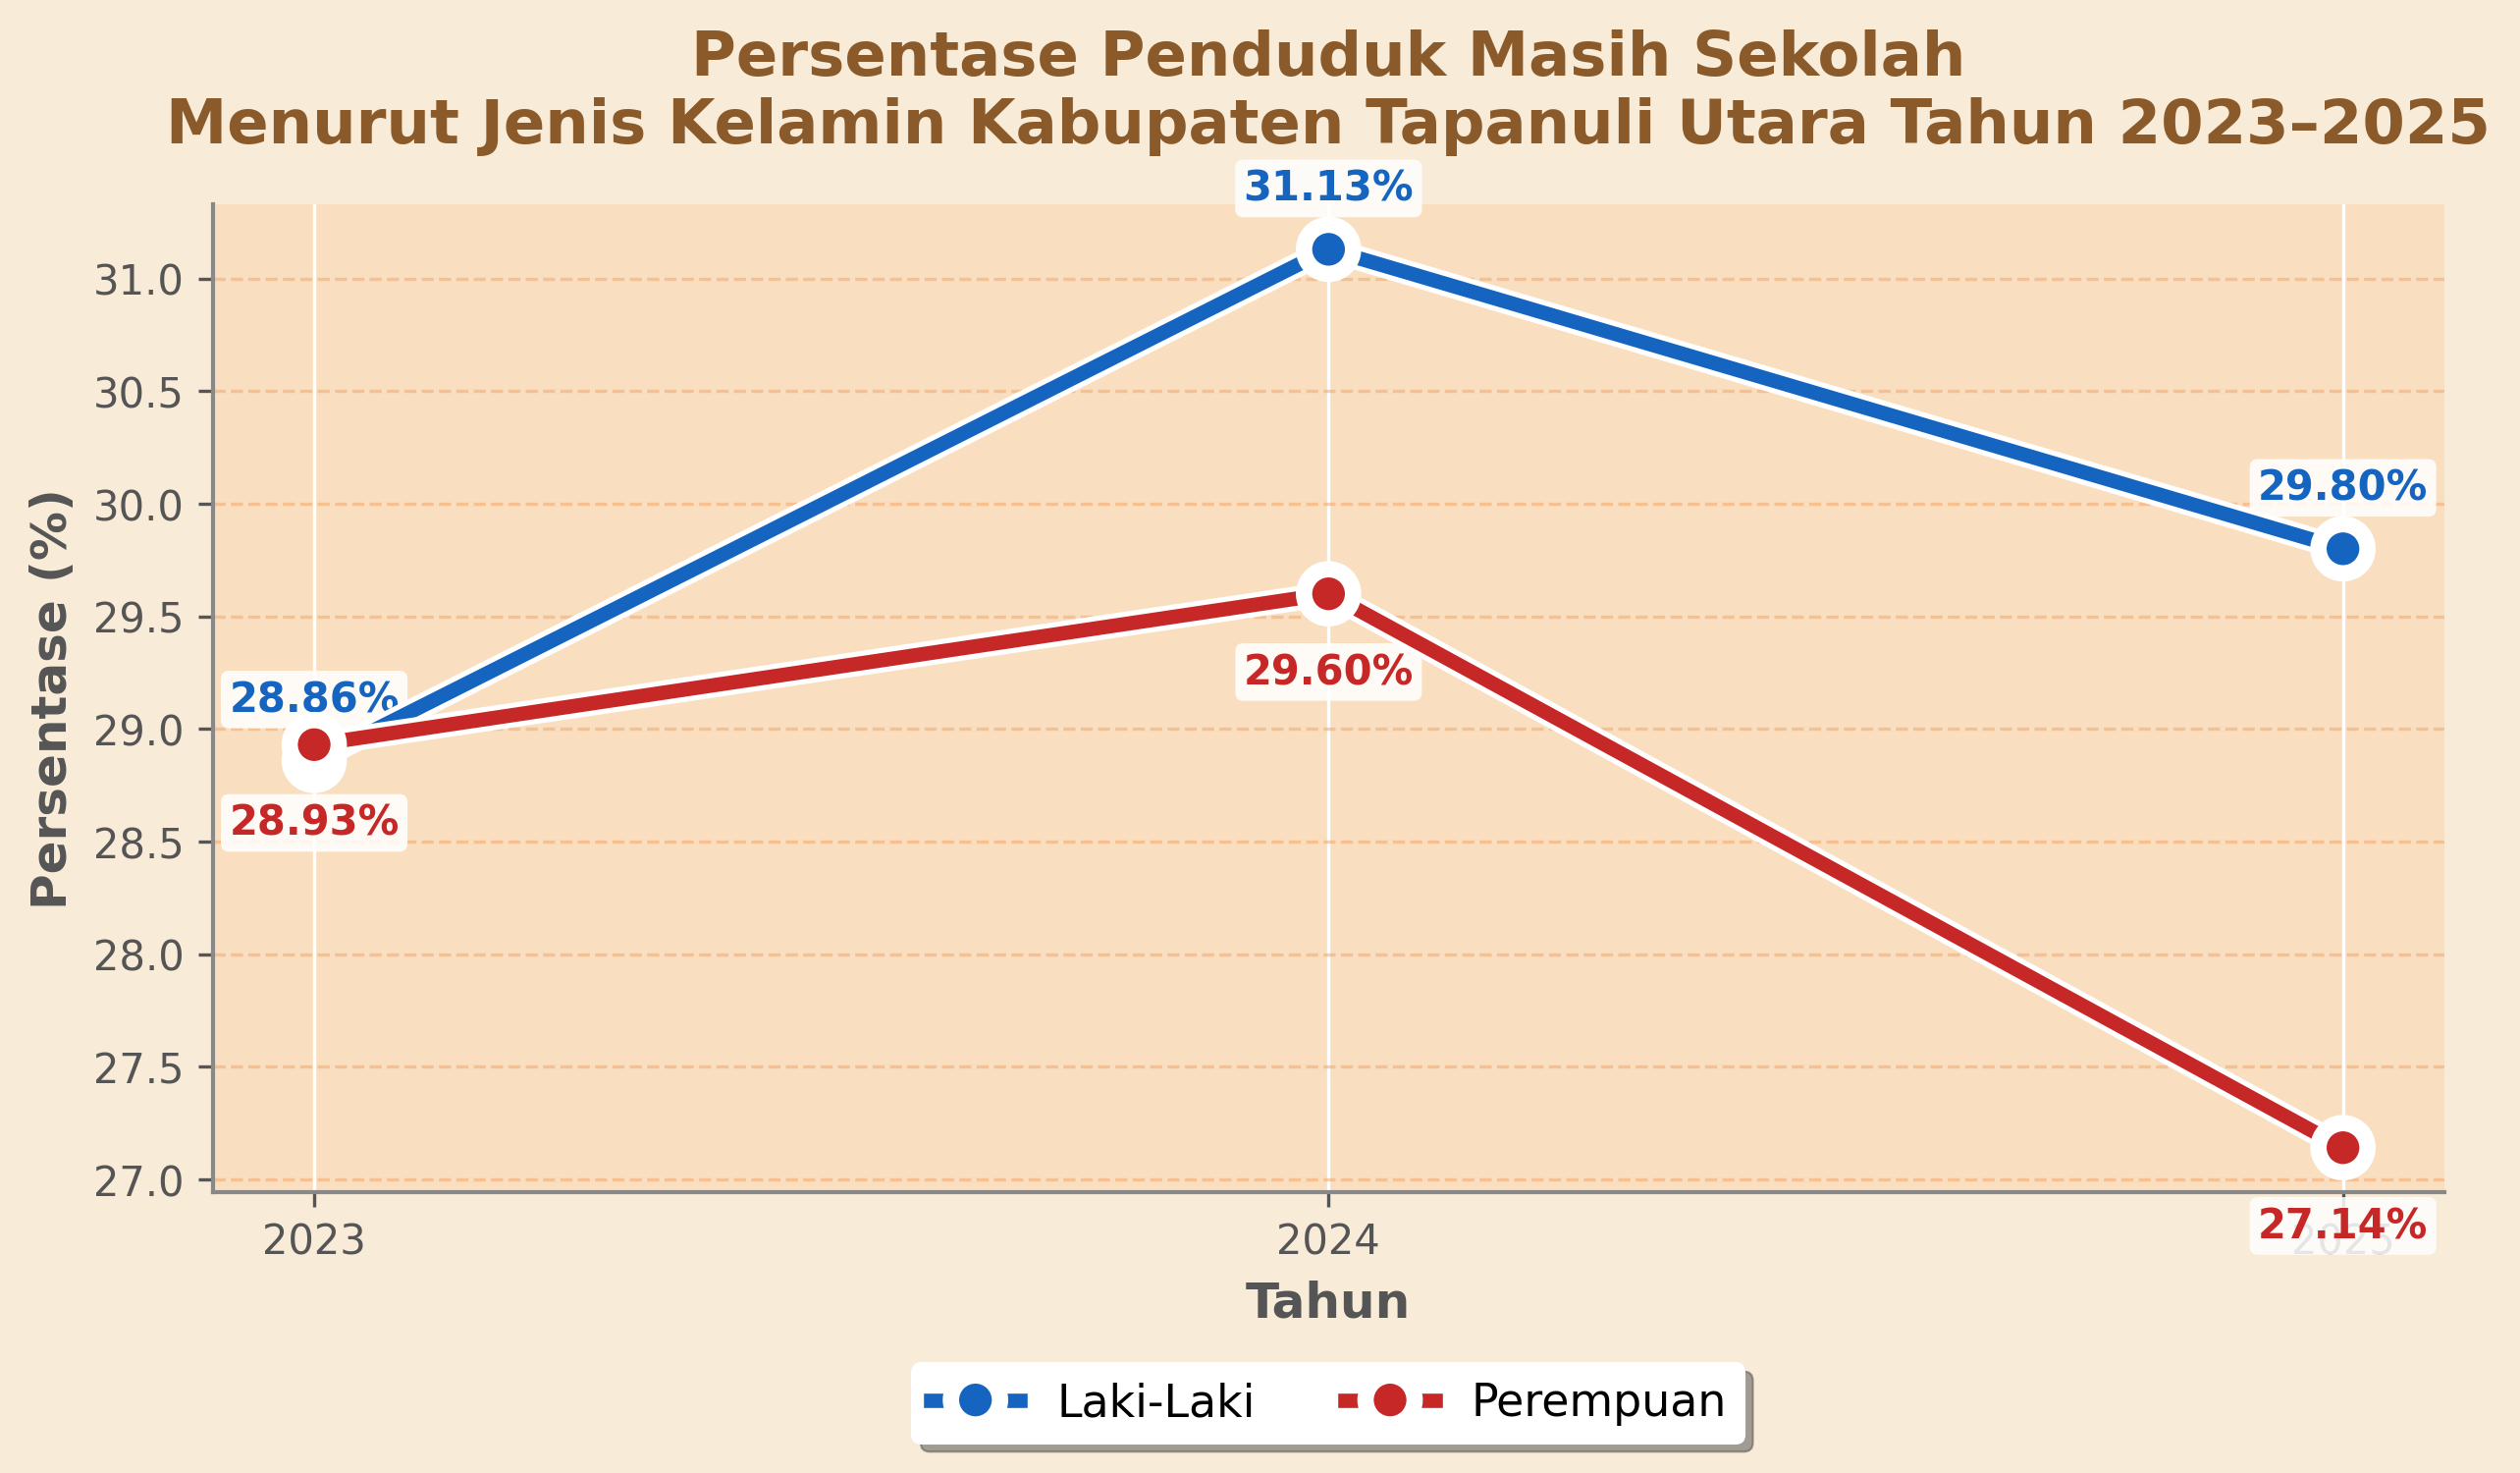

In [ ]:
df = sheets["Partisipasi Sekolah"].copy()
df["Karakteristik"] = df["Karakteristik"].str.strip()
df = df[df["Karakteristik"].isin(["Laki-Laki","Perempuan"])]

laki = df[df["Karakteristik"]=="Laki-Laki"].sort_values("Tahun")
perempuan = df[df["Karakteristik"]=="Perempuan"].sort_values("Tahun")

fig, ax = plt.subplots(figsize=(8.5,5.2), dpi=300)
fig.patch.set_facecolor("#F8EBD7")
ax.set_facecolor("#F9DFC0")

biru = "#1565C0"
merah = "#C62828"
orange = "#8B5A2B"

line1, = ax.plot(
    laki["Tahun"],
    laki["Masih Sekolah"],
    color=biru,
    linewidth=3.5,
    marker="o",
    markersize=10,
    markeredgecolor="white",
    markeredgewidth=2,
    label="Laki-Laki",
    zorder=5
)

line2, = ax.plot(
    perempuan["Tahun"],
    perempuan["Masih Sekolah"],
    color=merah,
    linewidth=3.5,
    marker="o",
    markersize=10,
    markeredgecolor="white",
    markeredgewidth=2,
    label="Perempuan",
    zorder=5
)

for line in [line1, line2]:
    line.set_path_effects([
        pe.Stroke(linewidth=6, foreground="white"),
        pe.Normal()
    ])

for x,y in zip(laki["Tahun"], laki["Masih Sekolah"]):
    ax.annotate(
        f"{y:.2f}%",
        (x,y),
        xytext=(0,12),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=biru,
        bbox=dict(
            boxstyle="round,pad=0.2",
            fc="white",
            ec="none",
            alpha=0.85
        )
    )

for x,y in zip(perempuan["Tahun"], perempuan["Masih Sekolah"]):
    ax.annotate(
        f"{y:.2f}%",
        (x,y),
        xytext=(0,-22),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=merah,
        bbox=dict(
            boxstyle="round,pad=0.2",
            fc="white",
            ec="none",
            alpha=0.85
        )
    )

ax.set_xticks([2023,2024,2025])

ax.set_xlabel(
    "Tahun",
    fontsize=12,
    fontweight="bold",
    color="#555555"
)

ax.set_ylabel(
    "Persentase (%)",
    fontsize=12,
    fontweight="bold",
    color="#555555"
)

ax.set_title(
    "Persentase Penduduk Masih Sekolah\n"
    "Menurut Jenis Kelamin Kabupaten Tapanuli Utara Tahun 2023–2025",
    fontsize=15,
    fontweight="bold",
    color=orange,
    pad=15
)

ax.grid(
    axis="y",
    linestyle="--",
    color="#F4A261",
    alpha=0.5
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("#888888")
ax.spines["bottom"].set_color("#888888")

legend = ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5,-0.15),
    ncol=2,
    frameon=True,
    fancybox=True,
    shadow=True,
    fontsize=11
)

legend.get_frame().set_facecolor("white")
legend.get_frame().set_edgecolor("white")

plt.tight_layout()
plt.show()

#### **c. Persentase Penduduk Tidak Sekolah Lagi Menurut Jenis Kelamin Tahun 2023–2025**

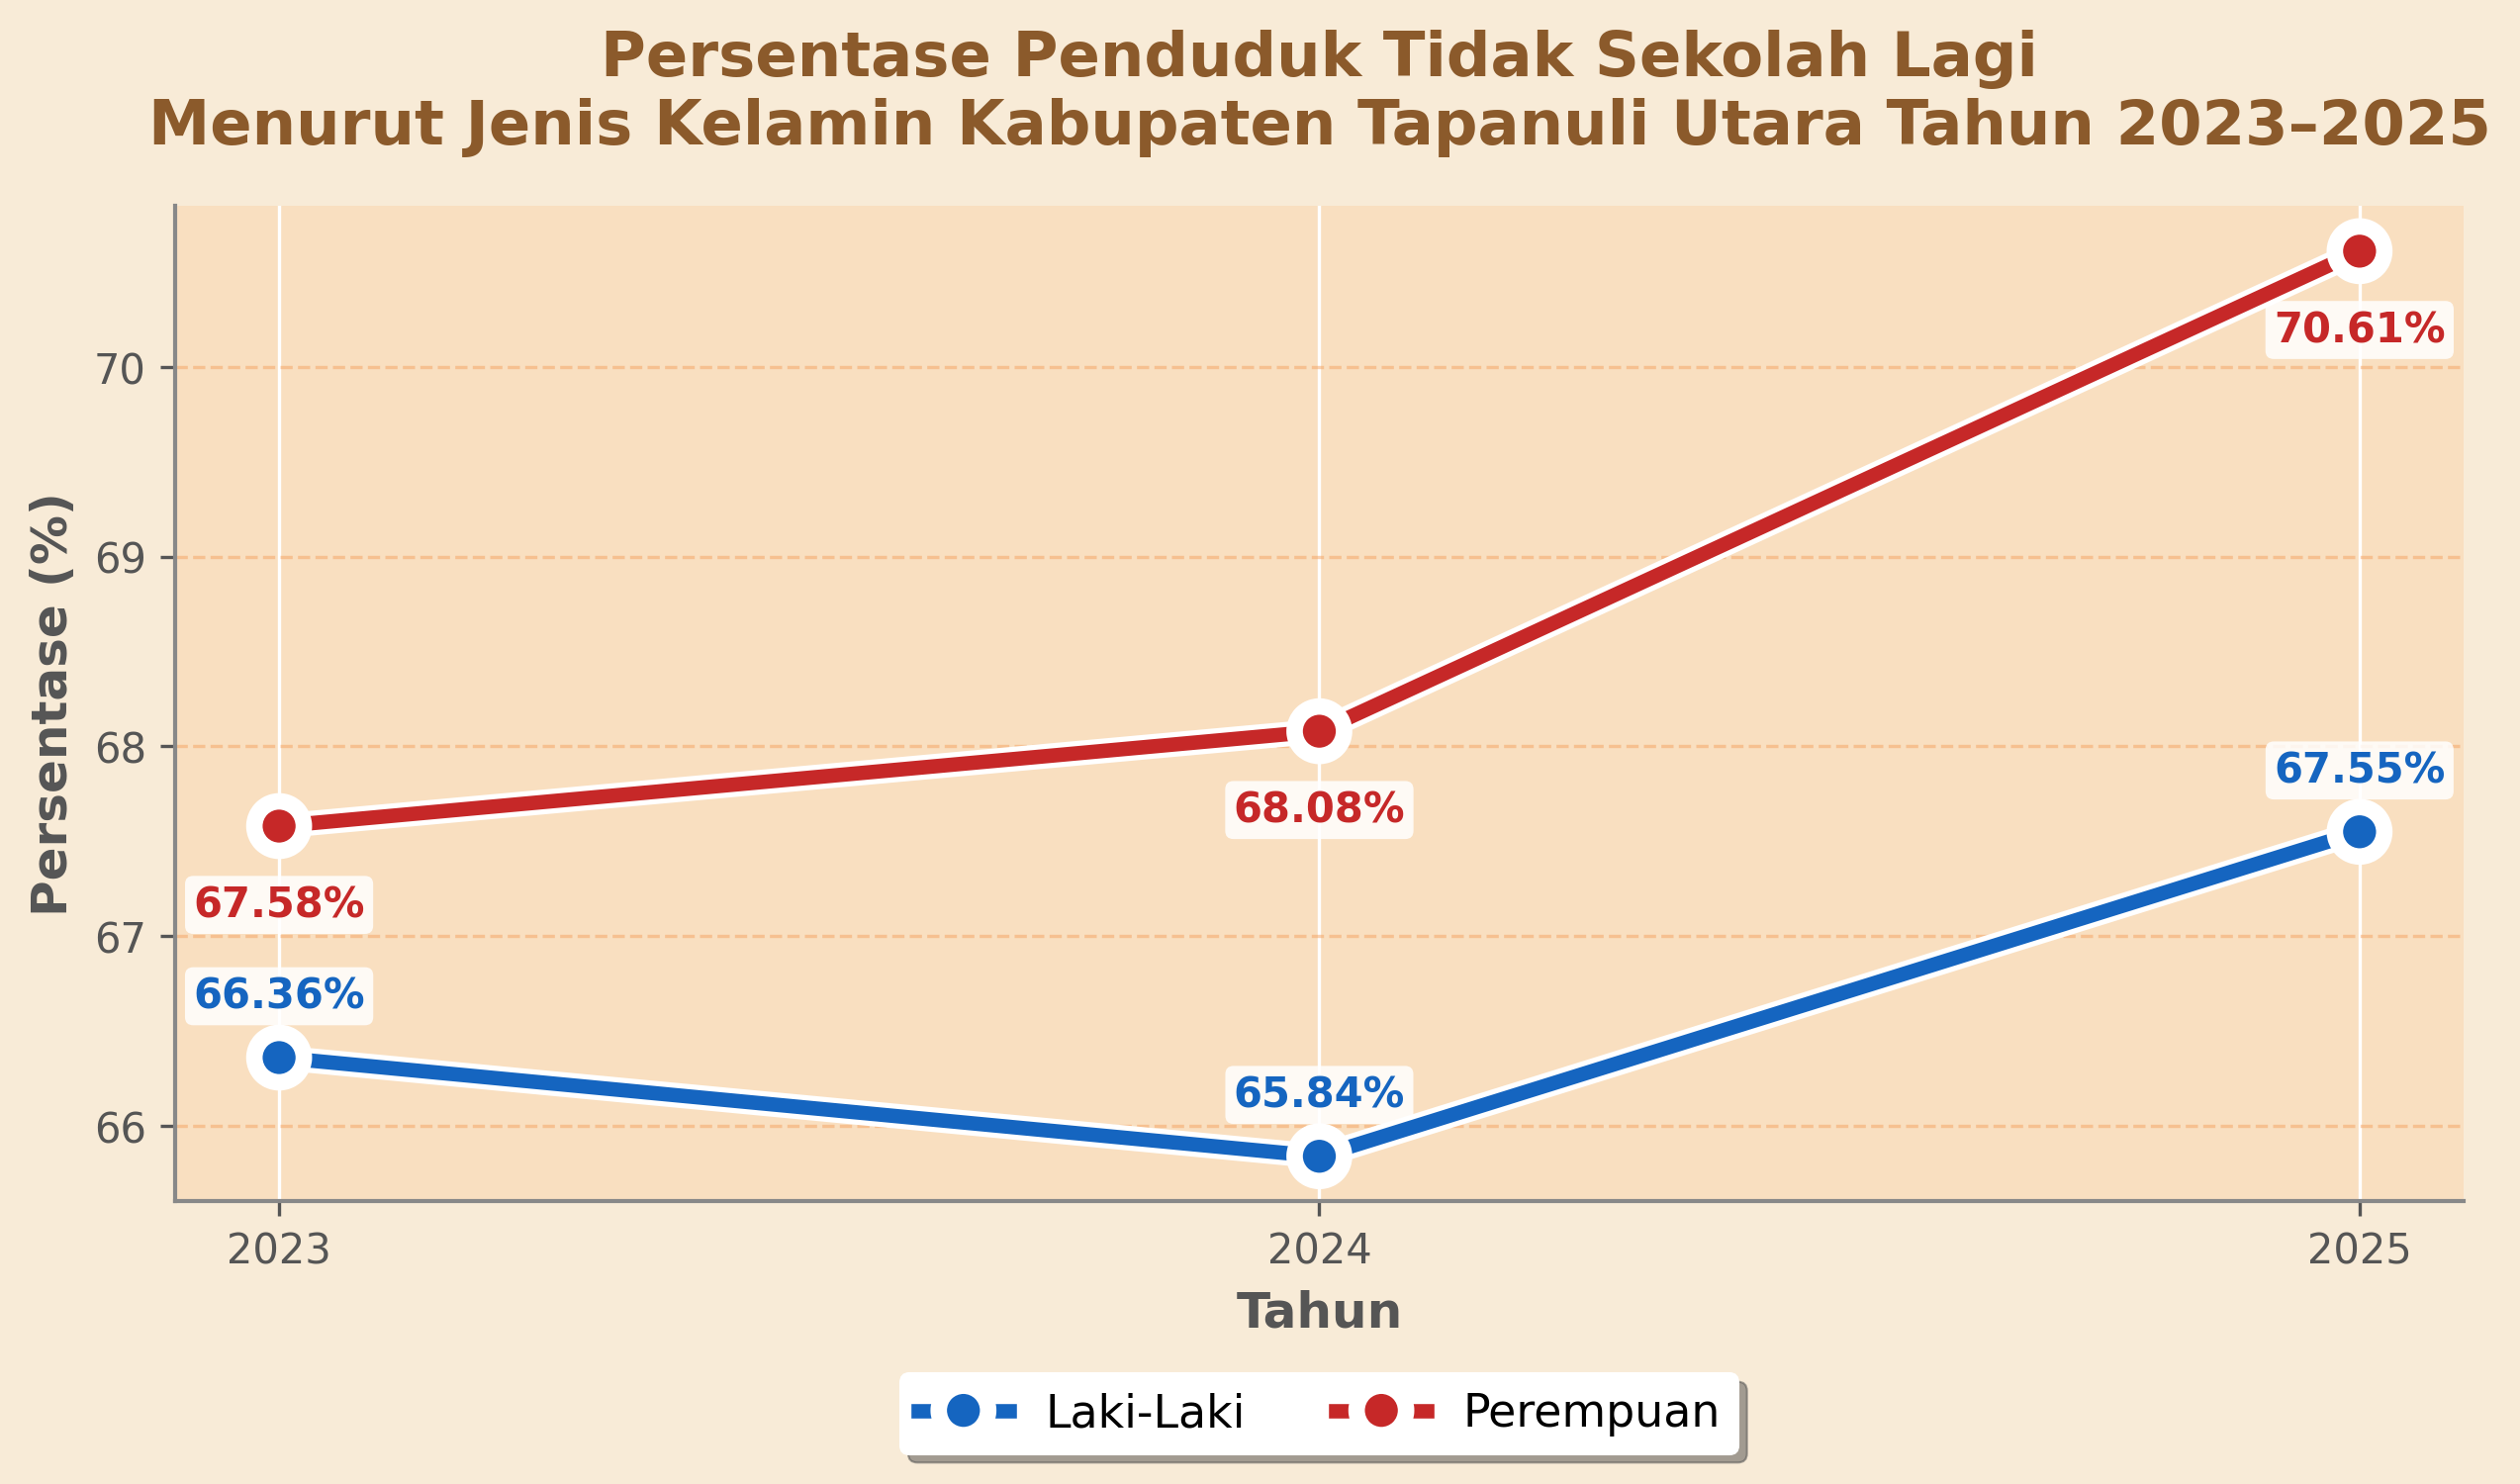

In [ ]:
df = sheets["Partisipasi Sekolah"].copy()
df["Karakteristik"] = df["Karakteristik"].str.strip()
df = df[df["Karakteristik"].isin(["Laki-Laki","Perempuan"])]

laki = df[df["Karakteristik"]=="Laki-Laki"].sort_values("Tahun")
perempuan = df[df["Karakteristik"]=="Perempuan"].sort_values("Tahun")

fig, ax = plt.subplots(figsize=(8.5,5.2), dpi=300)
fig.patch.set_facecolor("#F8EBD7")
ax.set_facecolor("#F9DFC0")

biru = "#1565C0"
merah = "#C62828"
orange = "#8B5A2B"

line1, = ax.plot(
    laki["Tahun"],
    laki["Tidak Sekolah Lagi"],
    color=biru,
    linewidth=3.5,
    marker="o",
    markersize=10,
    markeredgecolor="white",
    markeredgewidth=2,
    label="Laki-Laki",
    zorder=5
)

line2, = ax.plot(
    perempuan["Tahun"],
    perempuan["Tidak Sekolah Lagi"],
    color=merah,
    linewidth=3.5,
    marker="o",
    markersize=10,
    markeredgecolor="white",
    markeredgewidth=2,
    label="Perempuan",
    zorder=5
)

for line in [line1, line2]:
    line.set_path_effects([
        pe.Stroke(linewidth=6, foreground="white"),
        pe.Normal()
    ])

for x,y in zip(laki["Tahun"], laki["Tidak Sekolah Lagi"]):
    ax.annotate(
        f"{y:.2f}%",
        (x,y),
        xytext=(0,12),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=biru,
        bbox=dict(
            boxstyle="round,pad=0.2",
            fc="white",
            ec="none",
            alpha=0.85
        )
    )

for x,y in zip(perempuan["Tahun"], perempuan["Tidak Sekolah Lagi"]):
    ax.annotate(
        f"{y:.2f}%",
        (x,y),
        xytext=(0,-22),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=merah,
        bbox=dict(
            boxstyle="round,pad=0.2",
            fc="white",
            ec="none",
            alpha=0.85
        )
    )

ax.set_xticks([2023,2024,2025])

ax.set_xlabel(
    "Tahun",
    fontsize=12,
    fontweight="bold",
    color="#555555"
)

ax.set_ylabel(
    "Persentase (%)",
    fontsize=12,
    fontweight="bold",
    color="#555555"
)

ax.set_title(
    "Persentase Penduduk Tidak Sekolah Lagi\n"
    "Menurut Jenis Kelamin Kabupaten Tapanuli Utara Tahun 2023–2025",
    fontsize=15,
    fontweight="bold",
    color=orange,
    pad=15
)

ax.grid(
    axis="y",
    linestyle="--",
    color="#F4A261",
    alpha=0.5
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("#888888")
ax.spines["bottom"].set_color("#888888")

legend = ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5,-0.15),
    ncol=2,
    frameon=True,
    fancybox=True,
    shadow=True,
    fontsize=11
)

legend.get_frame().set_facecolor("white")
legend.get_frame().set_edgecolor("white")

plt.tight_layout()
plt.show()

### **VISUALISASI 2: Tingkat Pendidikan Tertinggi**

#### **a. Persentase Penduduk Tidak Memiliki Ijazah SD Menurut Jenis Kelamin Tahun 2023–2025**

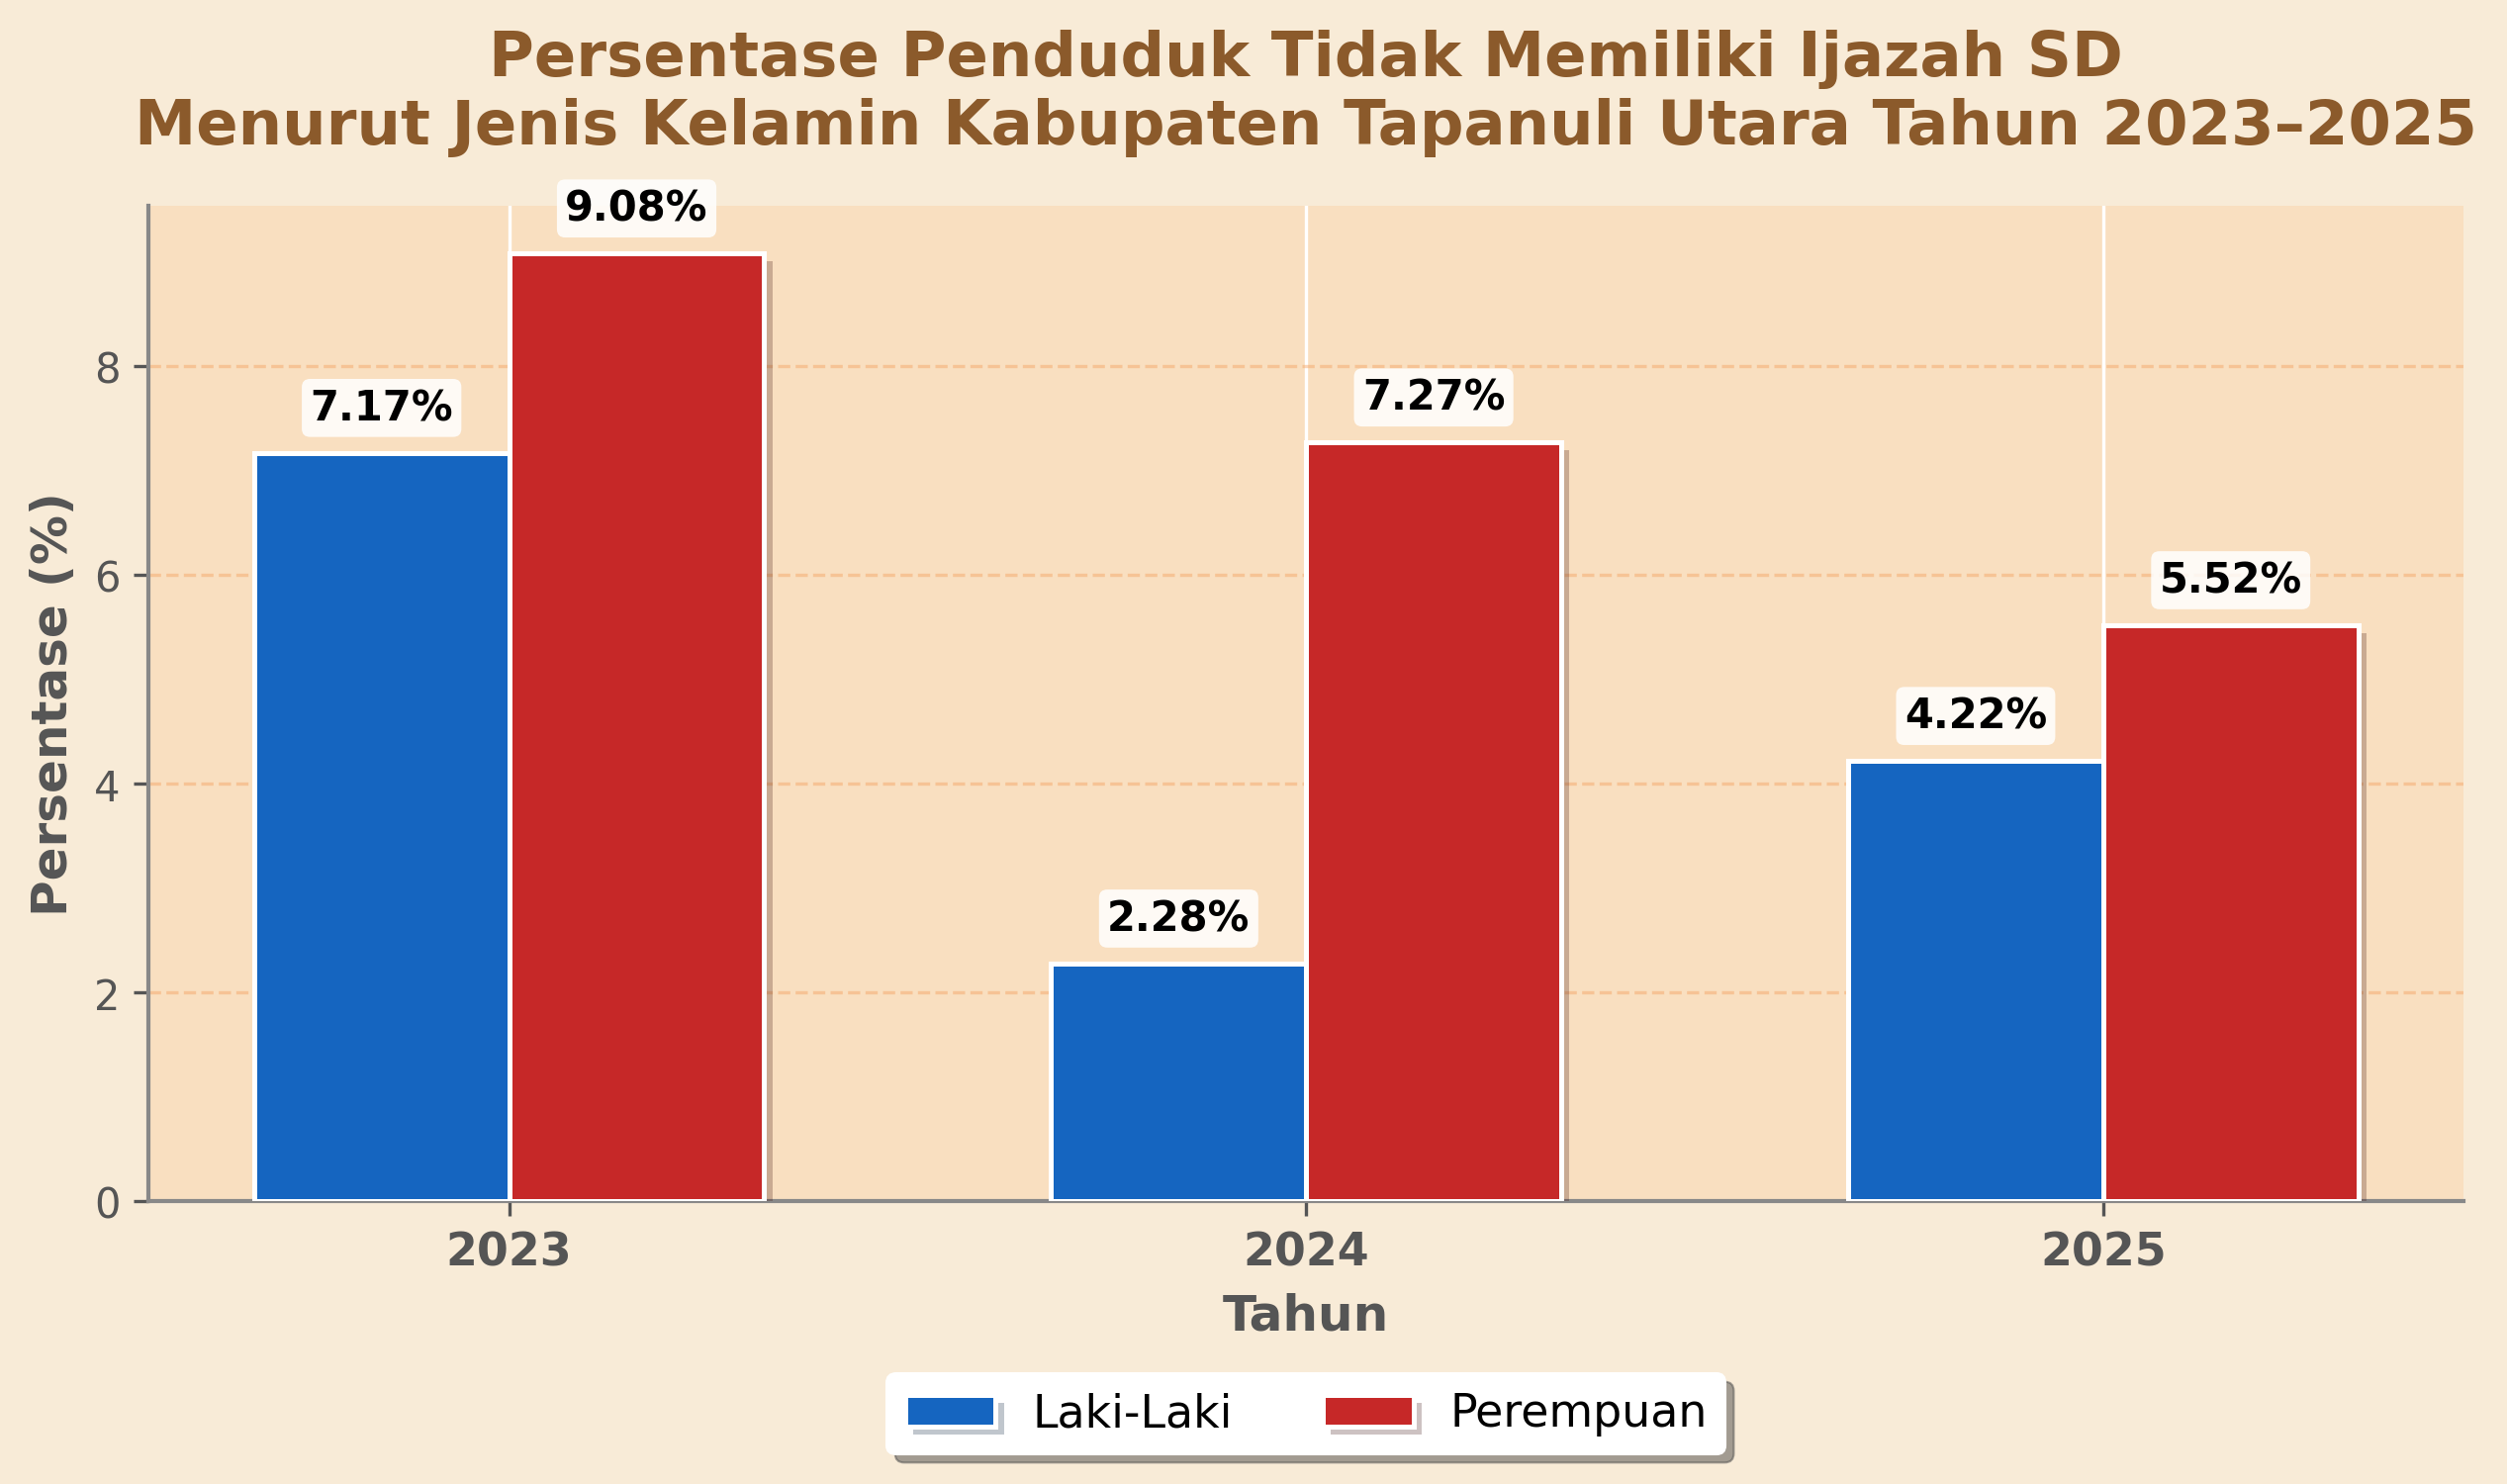

In [ ]:
import matplotlib.patheffects as pe

df = sheets["Pendidikan"].copy()
df["Karakteristik"] = df["Karakteristik"].str.strip()
df = df[df["Karakteristik"].isin(["Laki-Laki","Perempuan"])]

laki = df[df["Karakteristik"]=="Laki-Laki"].sort_values("Tahun")
perempuan = df[df["Karakteristik"]=="Perempuan"].sort_values("Tahun")

fig, ax = plt.subplots(figsize=(8.5,5.2), dpi=300)
fig.patch.set_facecolor("#F8EBD7")
ax.set_facecolor("#F9DFC0")

biru = "#1565C0"
merah = "#C62828"
orange = "#8B5A2B"

tahun = laki["Tahun"].astype(str)
x = np.arange(len(tahun))
width = 0.32

bar1 = ax.bar(
    x-width/2,
    laki["Tidak Punya Ijazah SD"],
    width,
    color=biru,
    edgecolor="white",
    linewidth=1.2,
    label="Laki-Laki",
    zorder=5
)

bar2 = ax.bar(
    x+width/2,
    perempuan["Tidak Punya Ijazah SD"],
    width,
    color=merah,
    edgecolor="white",
    linewidth=1.2,
    label="Perempuan",
    zorder=5
)

for bars in [bar1, bar2]:
    for bar in bars:
        bar.set_path_effects([
            pe.SimplePatchShadow(
                offset=(2,-2),
                alpha=0.25
            ),
            pe.Normal()
        ])

for bars in [bar1, bar2]:
    for bar in bars:
        ax.annotate(
            f"{bar.get_height():.2f}%",
            (
                bar.get_x()+bar.get_width()/2,
                bar.get_height()
            ),
            xytext=(0,8),
            textcoords="offset points",
            ha="center",
            fontsize=10,
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.2",
                fc="white",
                ec="none",
                alpha=0.85
            )
        )

ax.set_xticks(x)
ax.set_xticklabels(
    tahun,
    fontsize=11,
    fontweight="bold"
)

ax.set_xlabel(
    "Tahun",
    fontsize=12,
    fontweight="bold",
    color="#555555"
)

ax.set_ylabel(
    "Persentase (%)",
    fontsize=12,
    fontweight="bold",
    color="#555555"
)

ax.set_title(
    "Persentase Penduduk Tidak Memiliki Ijazah SD\n"
    "Menurut Jenis Kelamin Kabupaten Tapanuli Utara Tahun 2023–2025",
    fontsize=15,
    fontweight="bold",
    color=orange,
    pad=15
)

ax.grid(
    axis="y",
    linestyle="--",
    color="#F4A261",
    alpha=0.45
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("#888888")
ax.spines["bottom"].set_color("#888888")

legend = ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5,-0.15),
    ncol=2,
    frameon=True,
    fancybox=True,
    shadow=True,
    fontsize=11
)

legend.get_frame().set_facecolor("white")
legend.get_frame().set_edgecolor("white")

plt.tight_layout()
plt.show()

#### **b. Persentase Penduduk Berpendidikan SD/Sederajat Menurut Jenis Kelamin Tahun 2023–2025**

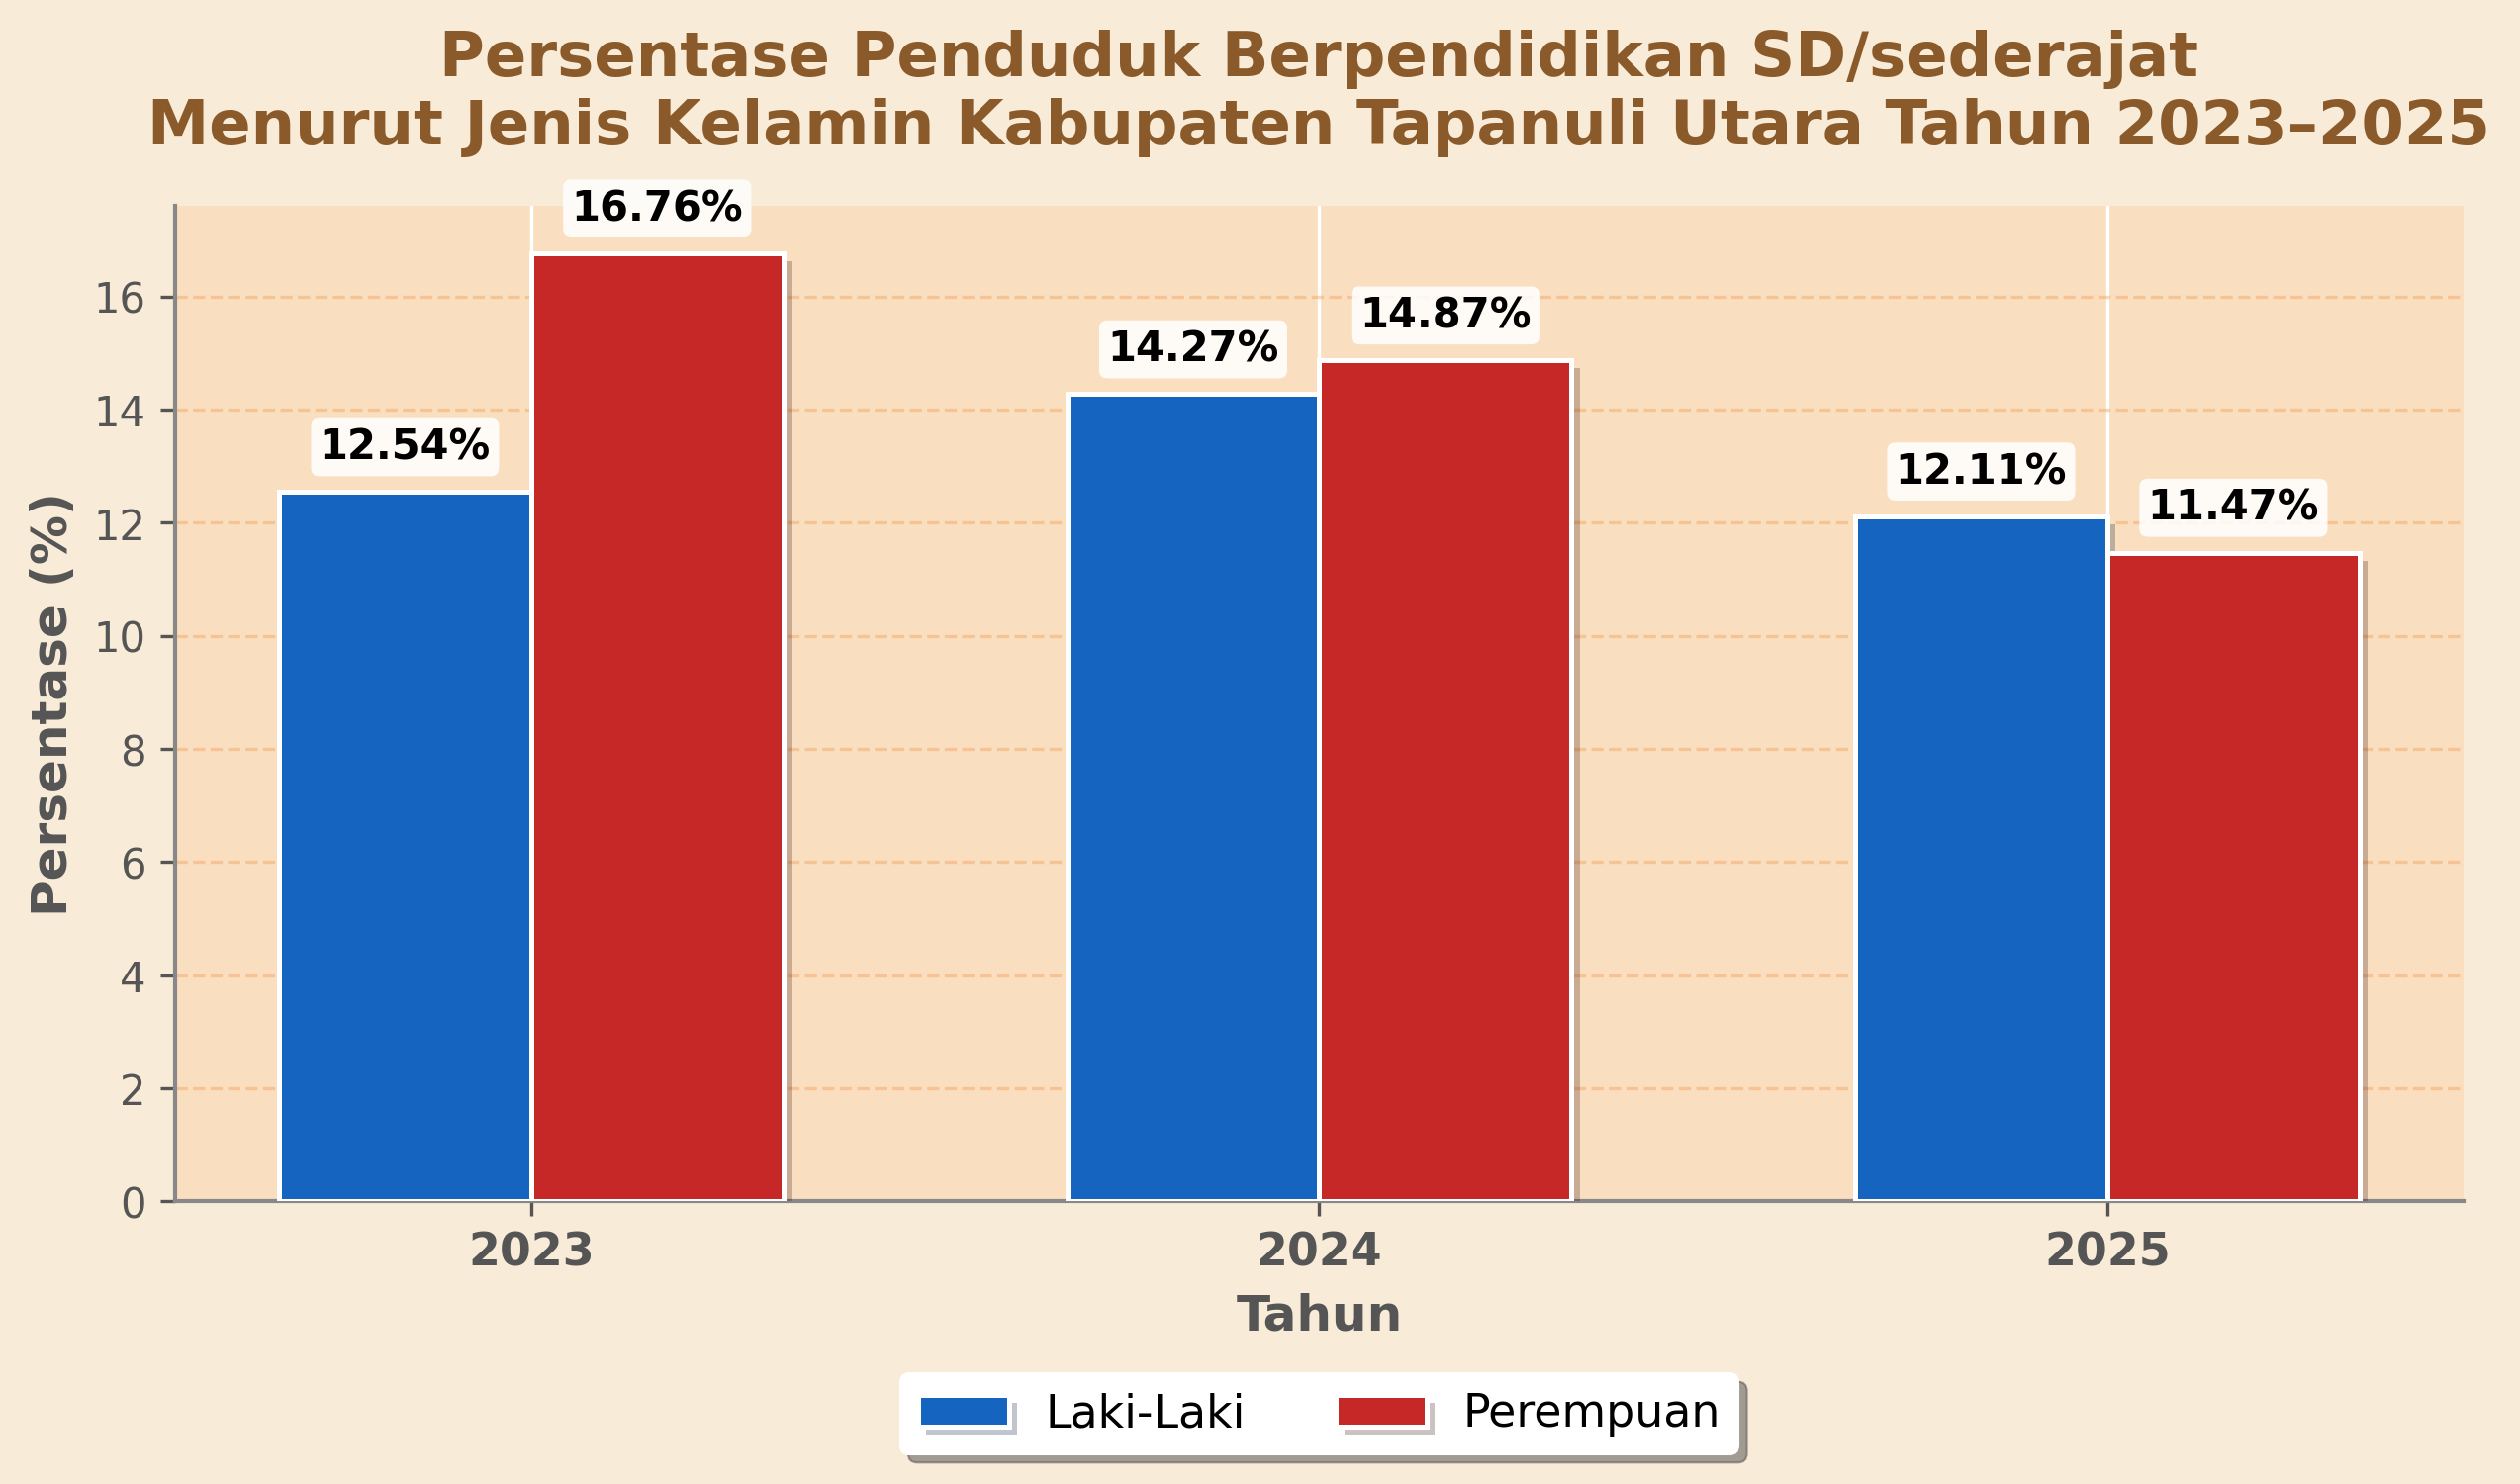

In [ ]:
import matplotlib.patheffects as pe

df = sheets["Pendidikan"].copy()
df["Karakteristik"] = df["Karakteristik"].str.strip()
df = df[df["Karakteristik"].isin(["Laki-Laki","Perempuan"])]

laki = df[df["Karakteristik"]=="Laki-Laki"].sort_values("Tahun")
perempuan = df[df["Karakteristik"]=="Perempuan"].sort_values("Tahun")

fig, ax = plt.subplots(figsize=(8.5,5.2), dpi=300)
fig.patch.set_facecolor("#F8EBD7")
ax.set_facecolor("#F9DFC0")

biru = "#1565C0"
merah = "#C62828"
orange = "#8B5A2B"

tahun = laki["Tahun"].astype(str)
x = np.arange(len(tahun))
width = 0.32

bar1 = ax.bar(
    x-width/2,
    laki["SD/sederajat"],
    width,
    color=biru,
    edgecolor="white",
    linewidth=1.2,
    label="Laki-Laki",
    zorder=5
)

bar2 = ax.bar(
    x+width/2,
    perempuan["SD/sederajat"],
    width,
    color=merah,
    edgecolor="white",
    linewidth=1.2,
    label="Perempuan",
    zorder=5
)

for bars in [bar1, bar2]:
    for bar in bars:
        bar.set_path_effects([
            pe.SimplePatchShadow(
                offset=(2,-2),
                alpha=0.25
            ),
            pe.Normal()
        ])

for bars in [bar1, bar2]:
    for bar in bars:
        ax.annotate(
            f"{bar.get_height():.2f}%",
            (
                bar.get_x()+bar.get_width()/2,
                bar.get_height()
            ),
            xytext=(0,8),
            textcoords="offset points",
            ha="center",
            fontsize=10,
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.2",
                fc="white",
                ec="none",
                alpha=0.85
            )
        )

ax.set_xticks(x)
ax.set_xticklabels(
    tahun,
    fontsize=11,
    fontweight="bold"
)

ax.set_xlabel(
    "Tahun",
    fontsize=12,
    fontweight="bold",
    color="#555555"
)

ax.set_ylabel(
    "Persentase (%)",
    fontsize=12,
    fontweight="bold",
    color="#555555"
)

ax.set_title(
    "Persentase Penduduk Berpendidikan SD/sederajat\n"
    "Menurut Jenis Kelamin Kabupaten Tapanuli Utara Tahun 2023–2025",
    fontsize=15,
    fontweight="bold",
    color=orange,
    pad=15
)

ax.grid(
    axis="y",
    linestyle="--",
    color="#F4A261",
    alpha=0.45
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("#888888")
ax.spines["bottom"].set_color("#888888")

legend = ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5,-0.15),
    ncol=2,
    frameon=True,
    fancybox=True,
    shadow=True,
    fontsize=11
)

legend.get_frame().set_facecolor("white")
legend.get_frame().set_edgecolor("white")

plt.tight_layout()
plt.show()

#### **c. Persentase Penduduk Berpendidikan SMP/Sederajat Menurut Jenis Kelamin Tahun 2023–2025**

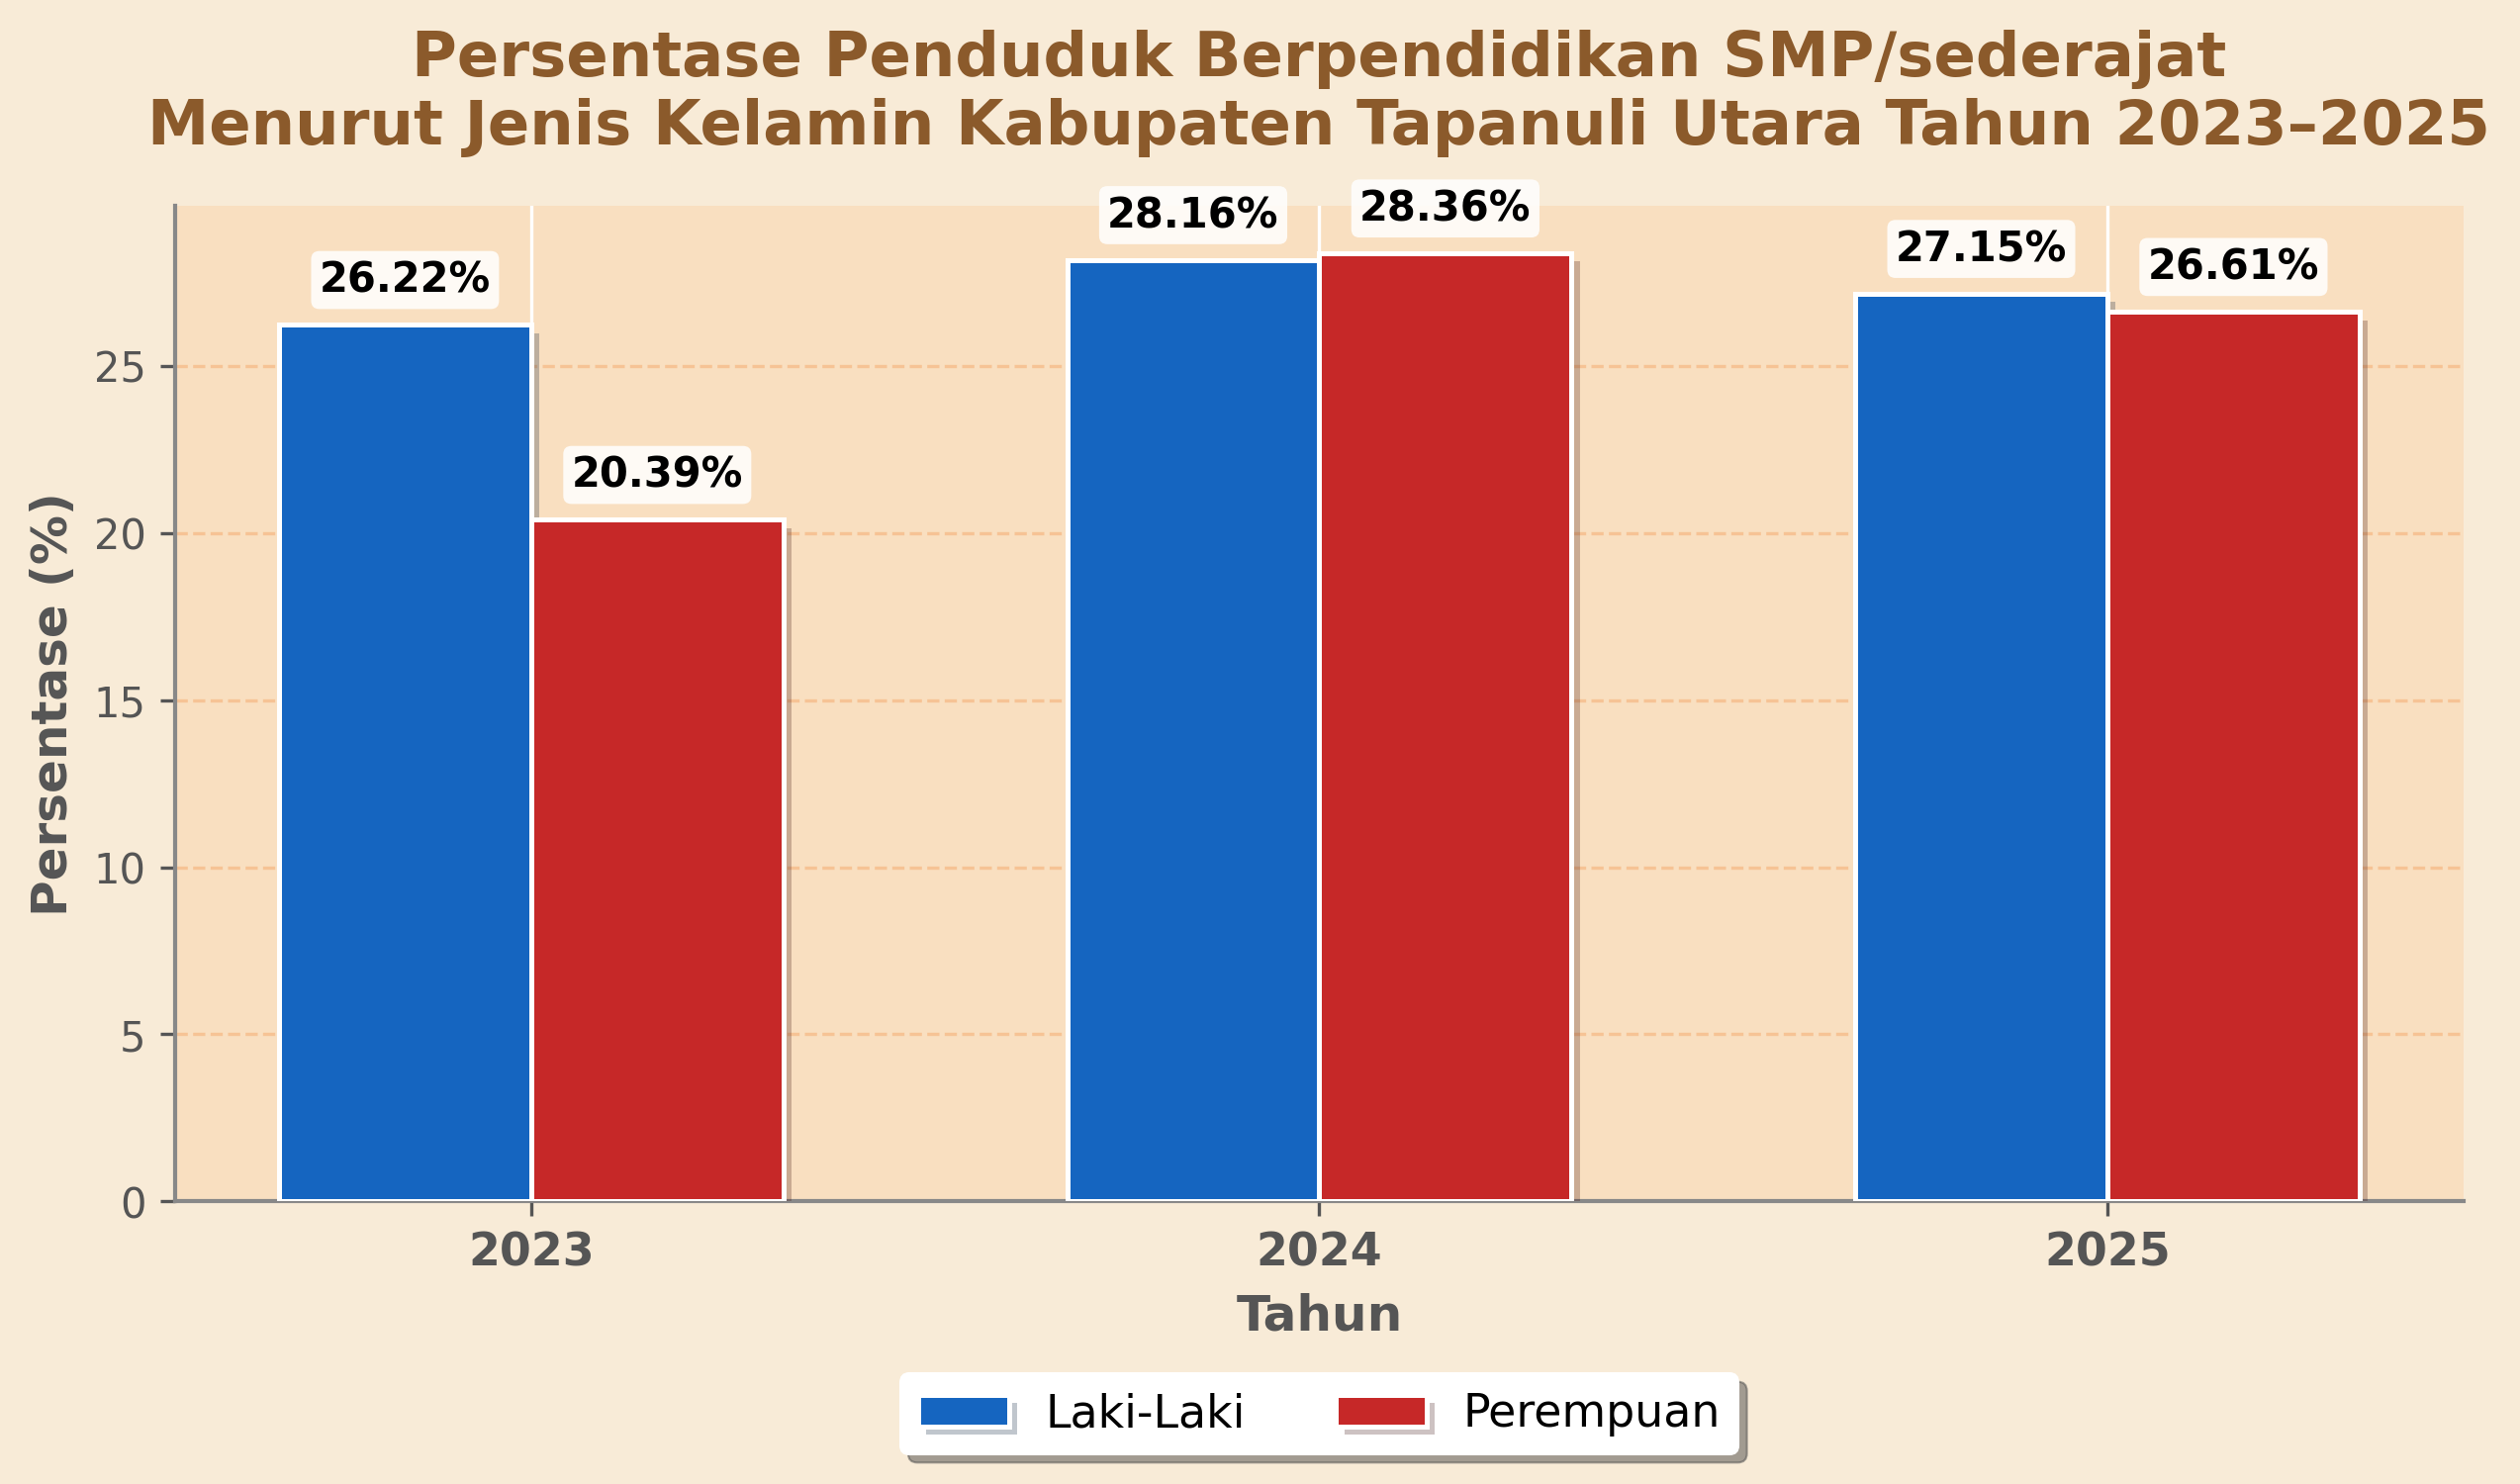

In [ ]:
import matplotlib.patheffects as pe

df = sheets["Pendidikan"].copy()
df["Karakteristik"] = df["Karakteristik"].str.strip()
df = df[df["Karakteristik"].isin(["Laki-Laki","Perempuan"])]

laki = df[df["Karakteristik"]=="Laki-Laki"].sort_values("Tahun")
perempuan = df[df["Karakteristik"]=="Perempuan"].sort_values("Tahun")

fig, ax = plt.subplots(figsize=(8.5,5.2), dpi=300)
fig.patch.set_facecolor("#F8EBD7")
ax.set_facecolor("#F9DFC0")

biru = "#1565C0"
merah = "#C62828"
orange = "#8B5A2B"

tahun = laki["Tahun"].astype(str)
x = np.arange(len(tahun))
width = 0.32

bar1 = ax.bar(
    x-width/2,
    laki["SMP/sederajat"],
    width,
    color=biru,
    edgecolor="white",
    linewidth=1.2,
    label="Laki-Laki",
    zorder=5
)

bar2 = ax.bar(
    x+width/2,
    perempuan["SMP/sederajat"],
    width,
    color=merah,
    edgecolor="white",
    linewidth=1.2,
    label="Perempuan",
    zorder=5
)

for bars in [bar1, bar2]:
    for bar in bars:
        bar.set_path_effects([
            pe.SimplePatchShadow(
                offset=(2,-2),
                alpha=0.25
            ),
            pe.Normal()
        ])

for bars in [bar1, bar2]:
    for bar in bars:
        ax.annotate(
            f"{bar.get_height():.2f}%",
            (
                bar.get_x()+bar.get_width()/2,
                bar.get_height()
            ),
            xytext=(0,8),
            textcoords="offset points",
            ha="center",
            fontsize=10,
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.2",
                fc="white",
                ec="none",
                alpha=0.85
            )
        )

ax.set_xticks(x)
ax.set_xticklabels(
    tahun,
    fontsize=11,
    fontweight="bold"
)

ax.set_xlabel(
    "Tahun",
    fontsize=12,
    fontweight="bold",
    color="#555555"
)

ax.set_ylabel(
    "Persentase (%)",
    fontsize=12,
    fontweight="bold",
    color="#555555"
)

ax.set_title(
    "Persentase Penduduk Berpendidikan SMP/sederajat\n"
    "Menurut Jenis Kelamin Kabupaten Tapanuli Utara Tahun 2023–2025",
    fontsize=15,
    fontweight="bold",
    color=orange,
    pad=15
)

ax.grid(
    axis="y",
    linestyle="--",
    color="#F4A261",
    alpha=0.45
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("#888888")
ax.spines["bottom"].set_color("#888888")

legend = ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5,-0.15),
    ncol=2,
    frameon=True,
    fancybox=True,
    shadow=True,
    fontsize=11
)

legend.get_frame().set_facecolor("white")
legend.get_frame().set_edgecolor("white")

plt.tight_layout()
plt.show()

#### **d. Persentase Penduduk Berpendidikan SMA/Ke Atas Menurut Jenis Kelamin Tahun 2023–2025**

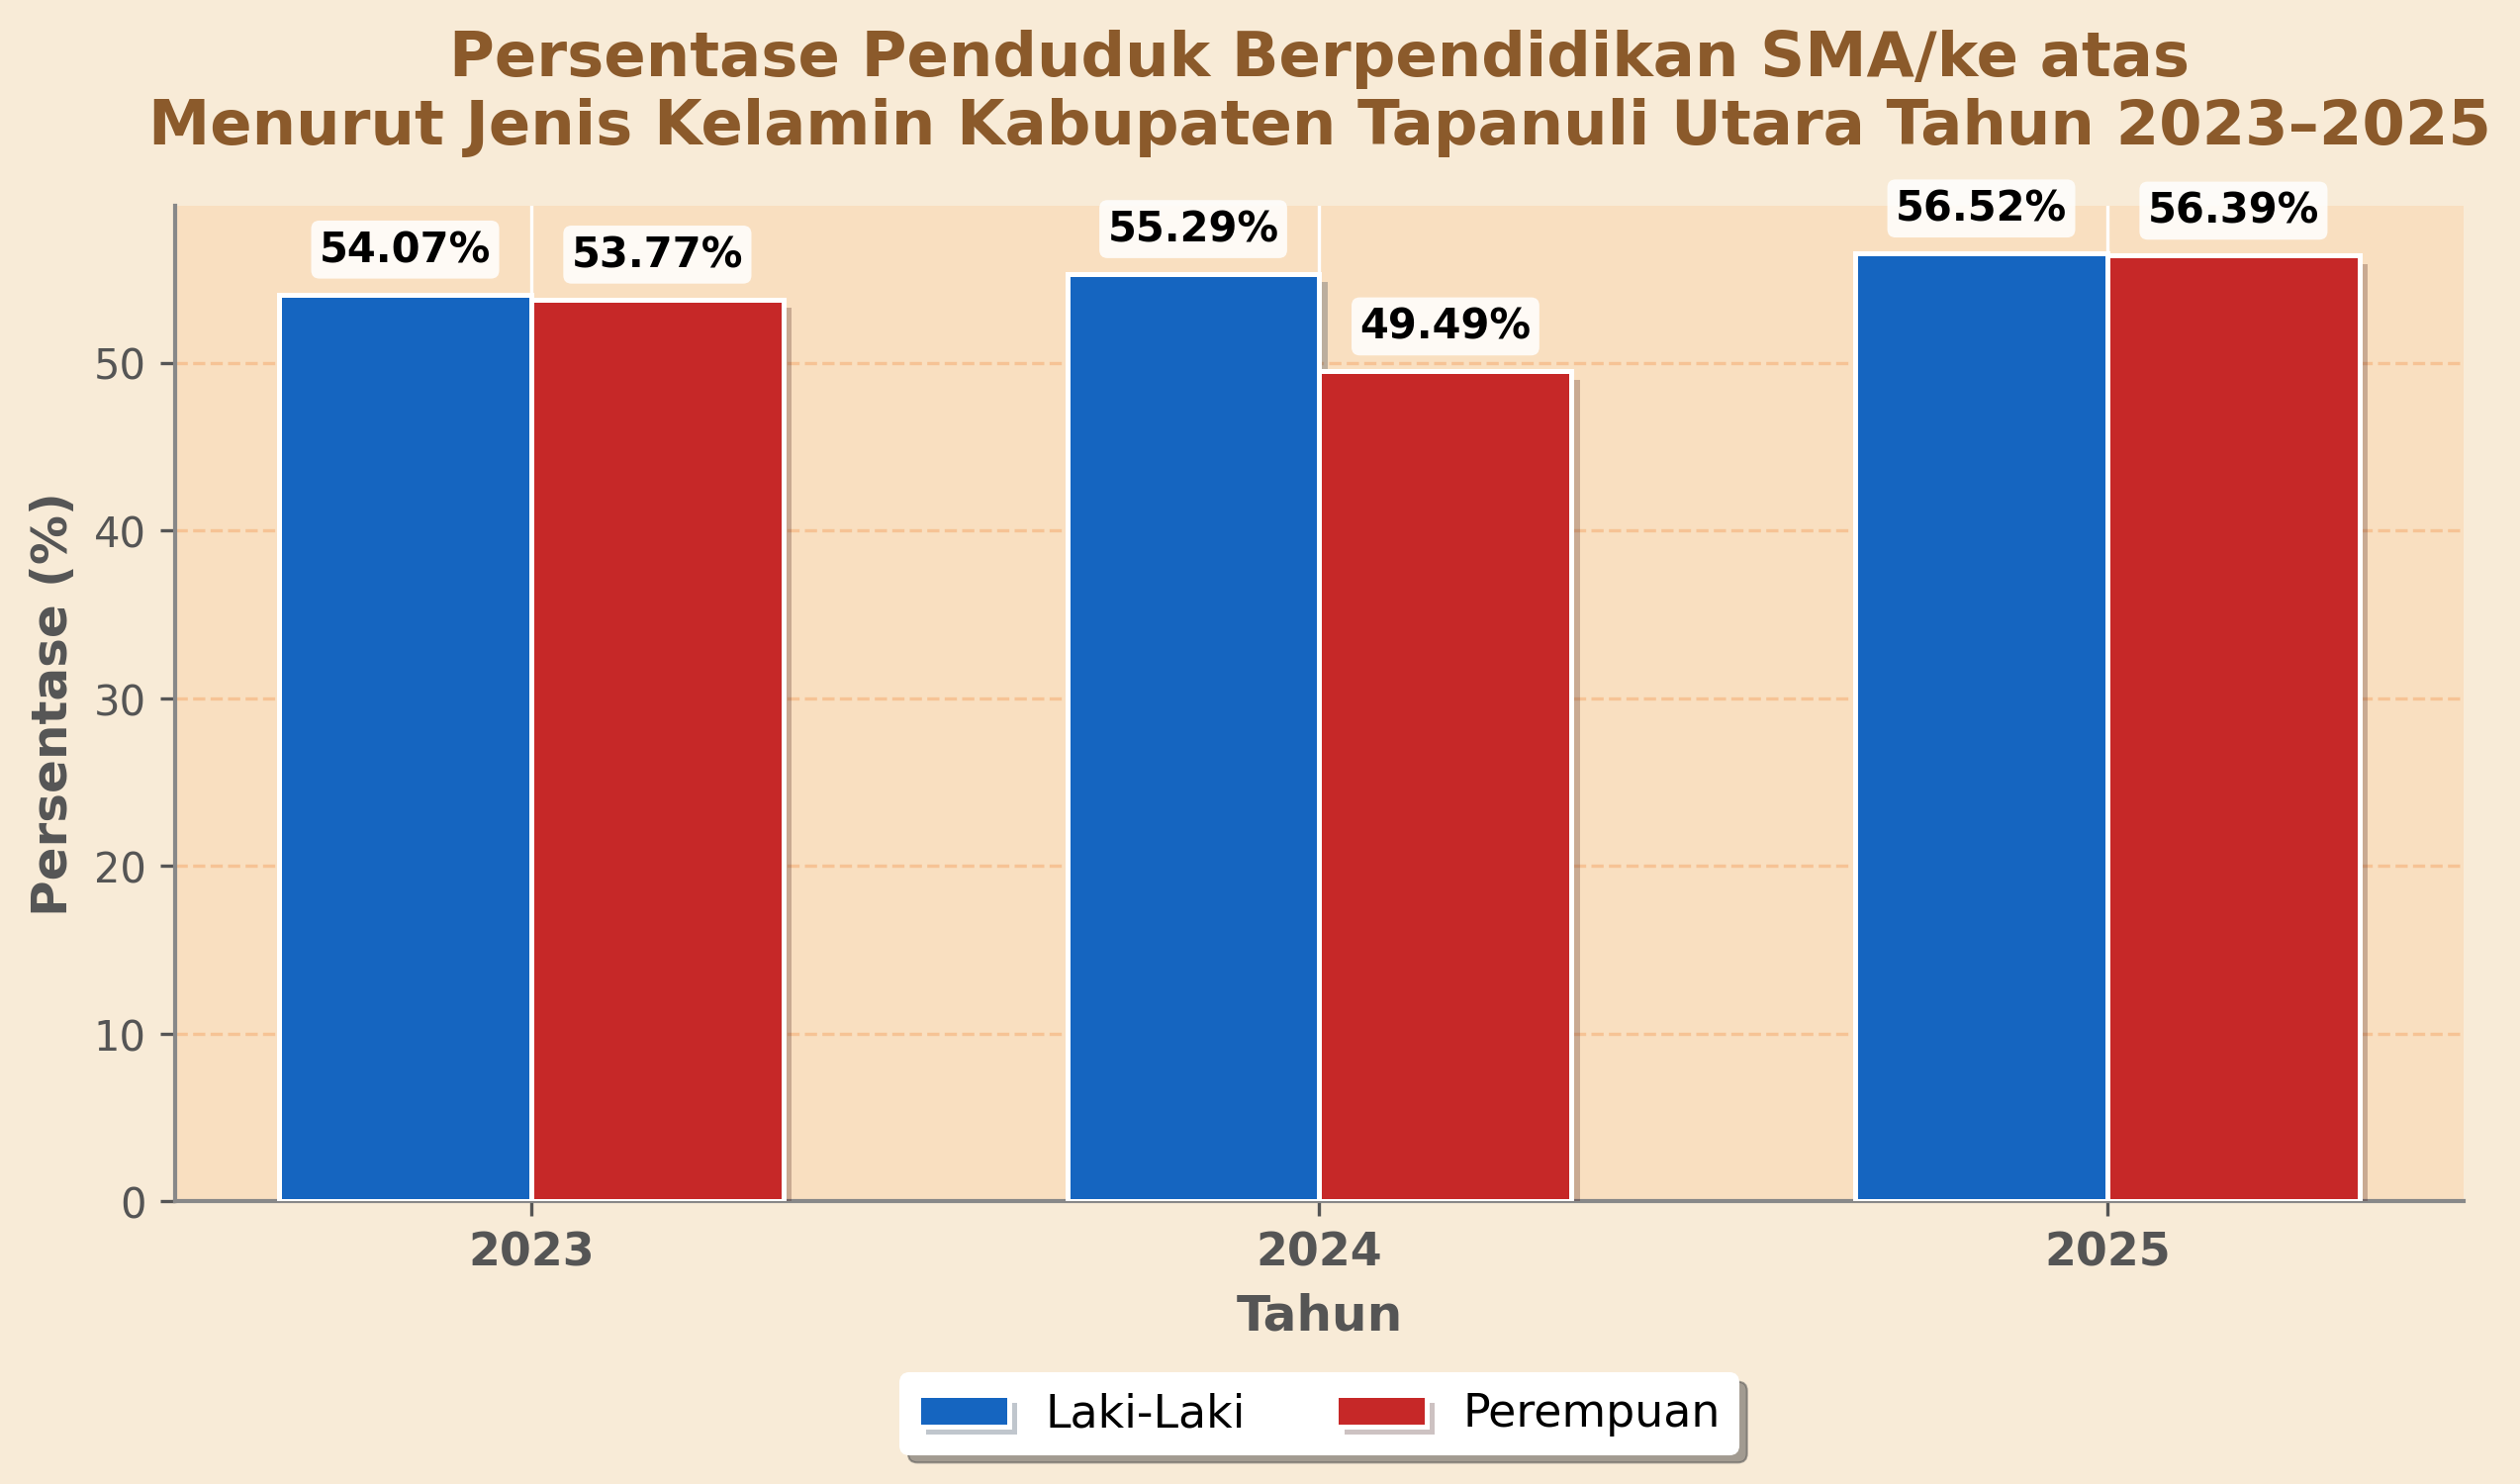

In [ ]:
import matplotlib.patheffects as pe

df = sheets["Pendidikan"].copy()
df["Karakteristik"] = df["Karakteristik"].str.strip()
df = df[df["Karakteristik"].isin(["Laki-Laki","Perempuan"])]

laki = df[df["Karakteristik"]=="Laki-Laki"].sort_values("Tahun")
perempuan = df[df["Karakteristik"]=="Perempuan"].sort_values("Tahun")

fig, ax = plt.subplots(figsize=(8.5,5.2), dpi=300)
fig.patch.set_facecolor("#F8EBD7")
ax.set_facecolor("#F9DFC0")

biru = "#1565C0"
merah = "#C62828"
orange = "#8B5A2B"

tahun = laki["Tahun"].astype(str)
x = np.arange(len(tahun))
width = 0.32

bar1 = ax.bar(
    x-width/2,
    laki["SMA/ke atas"],
    width,
    color=biru,
    edgecolor="white",
    linewidth=1.2,
    label="Laki-Laki",
    zorder=5
)

bar2 = ax.bar(
    x+width/2,
    perempuan["SMA/ke atas"],
    width,
    color=merah,
    edgecolor="white",
    linewidth=1.2,
    label="Perempuan",
    zorder=5
)

for bars in [bar1, bar2]:
    for bar in bars:
        bar.set_path_effects([
            pe.SimplePatchShadow(
                offset=(2,-2),
                alpha=0.25
            ),
            pe.Normal()
        ])

for bars in [bar1, bar2]:
    for bar in bars:
        ax.annotate(
            f"{bar.get_height():.2f}%",
            (
                bar.get_x()+bar.get_width()/2,
                bar.get_height()
            ),
            xytext=(0,8),
            textcoords="offset points",
            ha="center",
            fontsize=10,
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.2",
                fc="white",
                ec="none",
                alpha=0.85
            )
        )

ax.set_xticks(x)
ax.set_xticklabels(
    tahun,
    fontsize=11,
    fontweight="bold"
)

ax.set_xlabel(
    "Tahun",
    fontsize=12,
    fontweight="bold",
    color="#555555"
)

ax.set_ylabel(
    "Persentase (%)",
    fontsize=12,
    fontweight="bold",
    color="#555555"
)

ax.set_title(
    "Persentase Penduduk Berpendidikan SMA/ke atas\n"
    "Menurut Jenis Kelamin Kabupaten Tapanuli Utara Tahun 2023–2025",
    fontsize=15,
    fontweight="bold",
    color=orange,
    pad=15
)

ax.grid(
    axis="y",
    linestyle="--",
    color="#F4A261",
    alpha=0.45
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("#888888")
ax.spines["bottom"].set_color("#888888")

legend = ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5,-0.15),
    ncol=2,
    frameon=True,
    fancybox=True,
    shadow=True,
    fontsize=11
)

legend.get_frame().set_facecolor("white")
legend.get_frame().set_edgecolor("white")

plt.tight_layout()
plt.show()

### **VISUALISASI 3: Persentase Angka Kesakitan Menurut Jenis Kelamin Kabupaten Tapanuli Utara Tahun 2023–2025"**



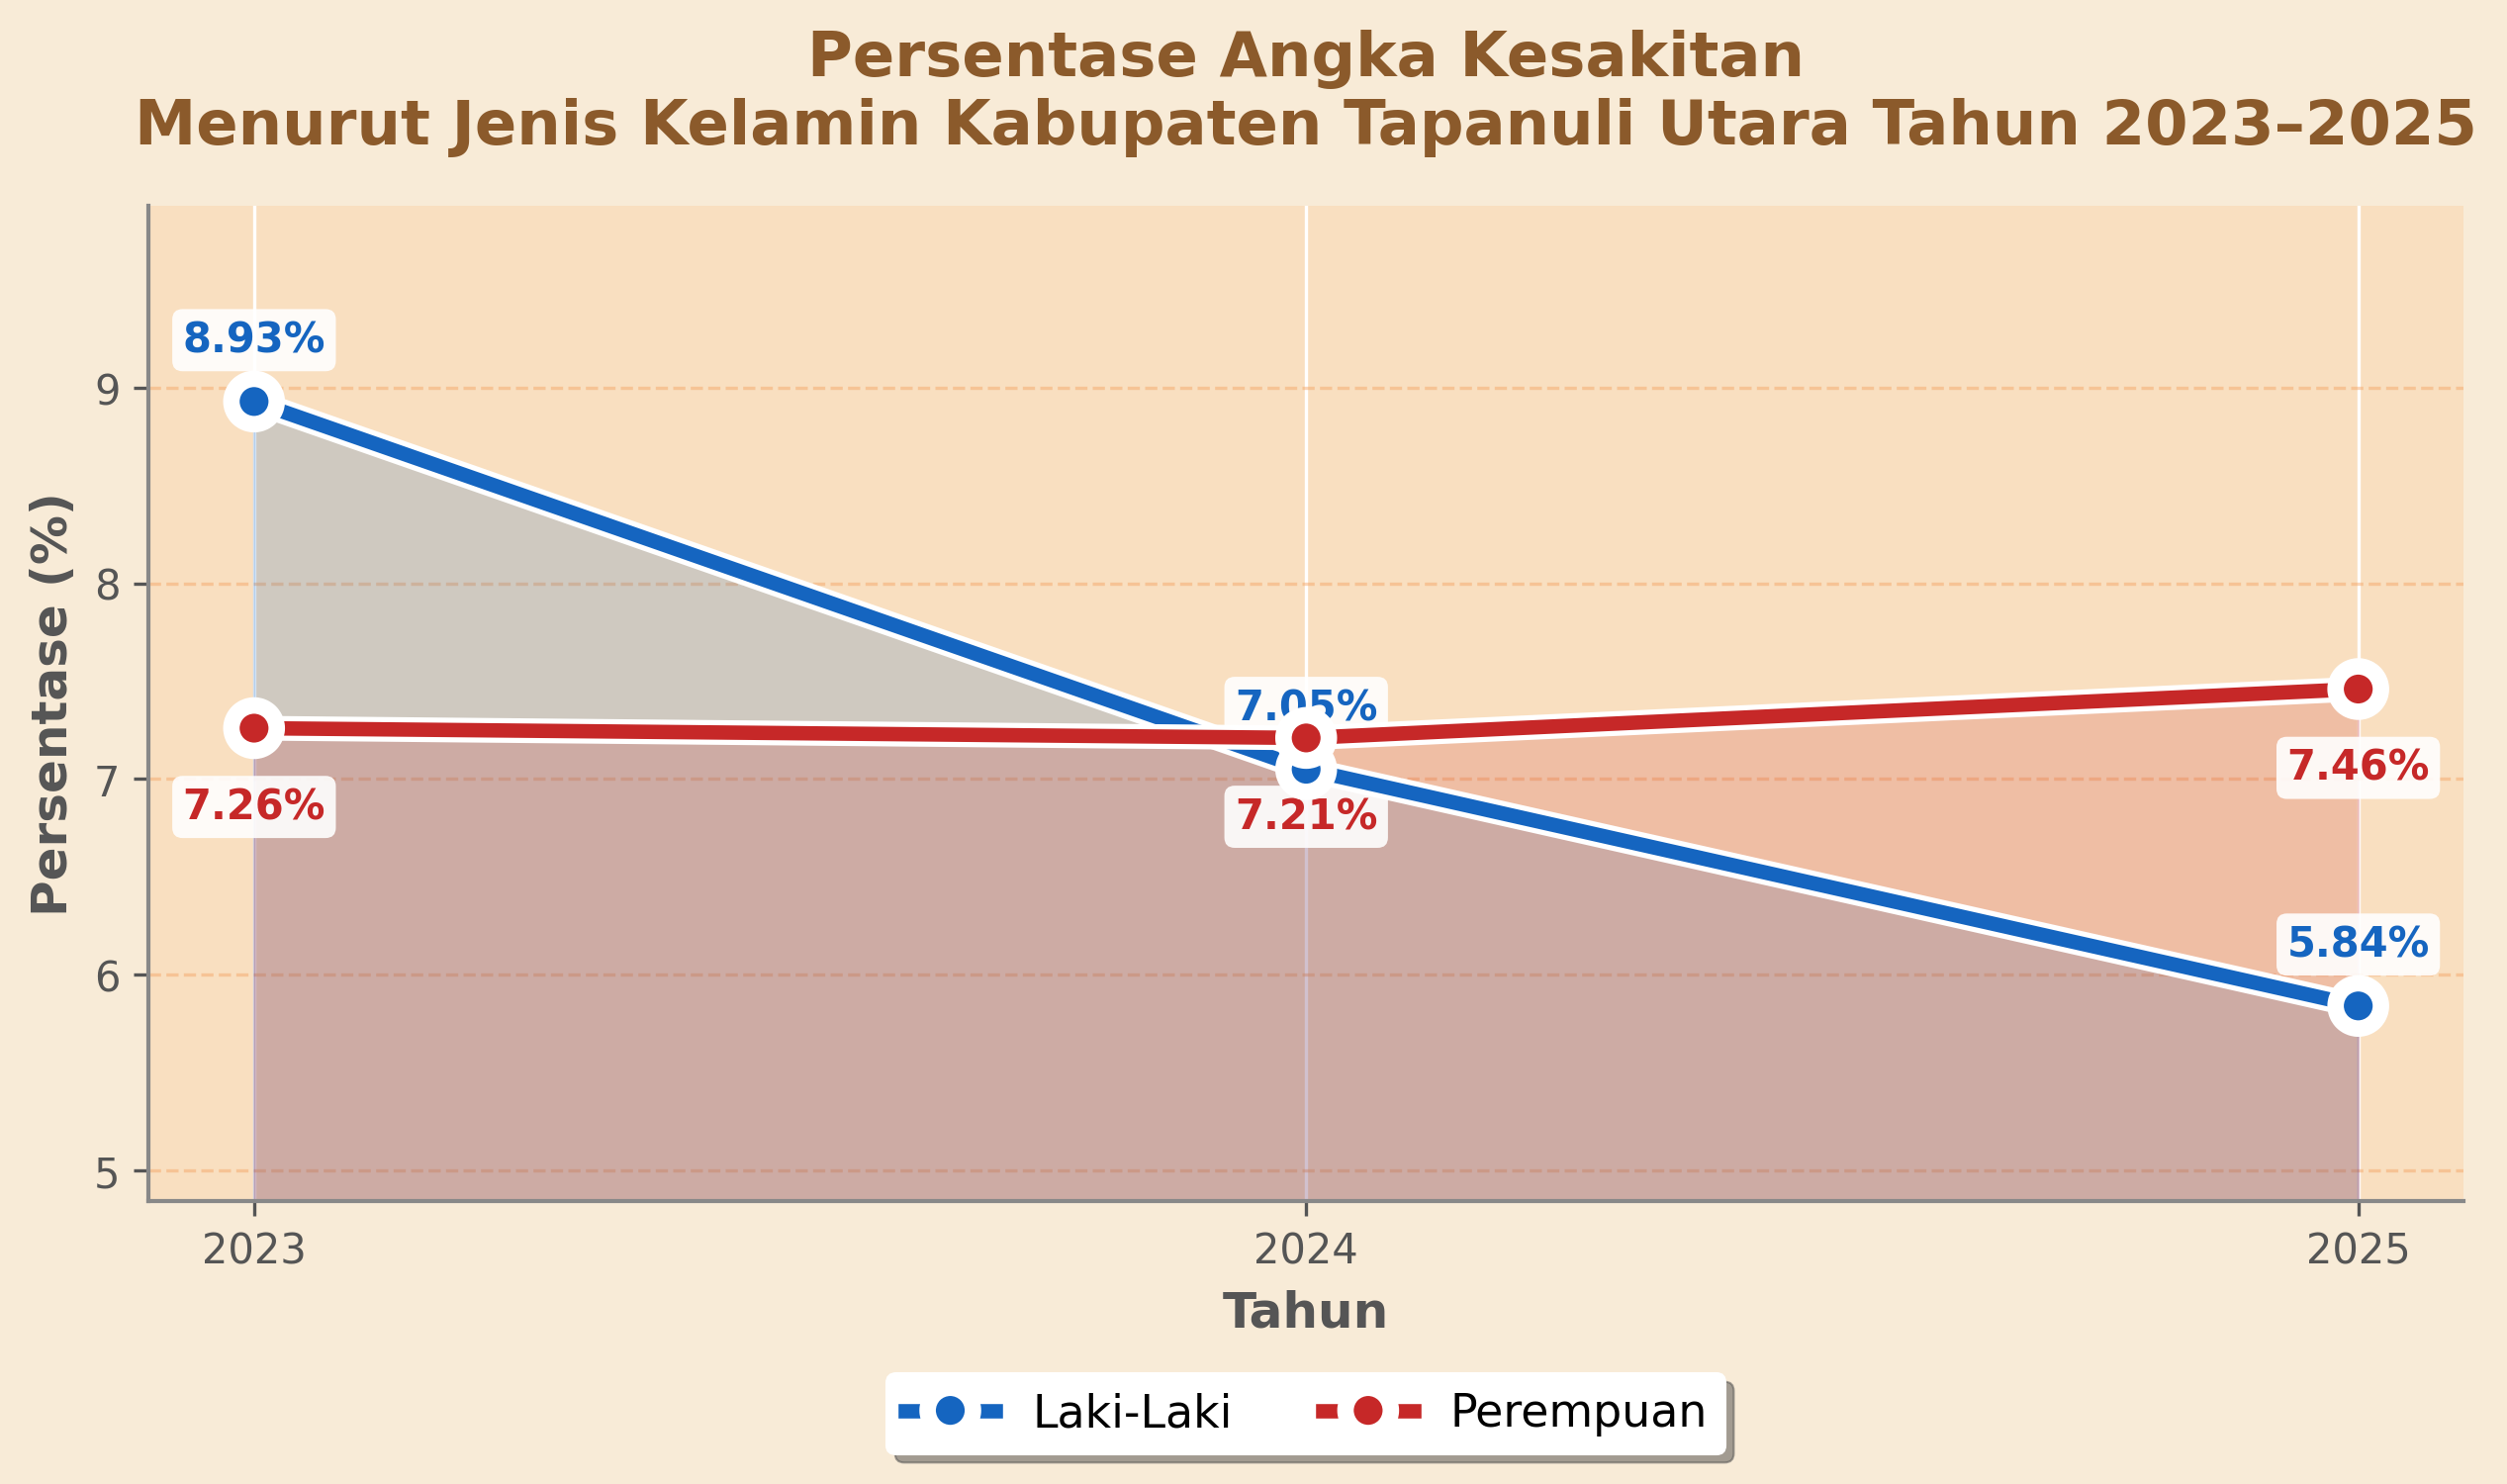

In [ ]:
df = sheets["Kesakitan"].copy()
df["Karakteristik"] = df["Karakteristik"].str.strip()
df = df[df["Karakteristik"].isin(["Laki-Laki", "Perempuan"])]

laki = df[df["Karakteristik"]=="Laki-Laki"].sort_values("Tahun")
perempuan = df[df["Karakteristik"]=="Perempuan"].sort_values("Tahun")

fig, ax = plt.subplots(figsize=(8.5,5.2), dpi=300)
fig.patch.set_facecolor("#F8EBD7")
ax.set_facecolor("#F9DFC0")

biru = "#1565C0"
merah = "#C62828"
orange = "#8B5A2B"

ax.fill_between(
    laki["Tahun"],
    laki["Angka Kesakitan"],
    color=biru,
    alpha=0.18,
    zorder=1
)

ax.fill_between(
    perempuan["Tahun"],
    perempuan["Angka Kesakitan"],
    color=merah,
    alpha=0.18,
    zorder=1
)

line1, = ax.plot(
    laki["Tahun"],
    laki["Angka Kesakitan"],
    color=biru,
    linewidth=3.5,
    marker="o",
    markersize=9,
    markeredgecolor="white",
    markeredgewidth=2,
    label="Laki-Laki",
    zorder=5
)

line2, = ax.plot(
    perempuan["Tahun"],
    perempuan["Angka Kesakitan"],
    color=merah,
    linewidth=3.5,
    marker="o",
    markersize=9,
    markeredgecolor="white",
    markeredgewidth=2,
    label="Perempuan",
    zorder=5
)

for line in [line1, line2]:
    line.set_path_effects([
        pe.Stroke(linewidth=6, foreground="white"),
        pe.Normal()
    ])

for x, y in zip(laki["Tahun"], laki["Angka Kesakitan"]):
    ax.annotate(
        f"{y:.2f}%",
        (x, y),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=biru,
        bbox=dict(
            boxstyle="round,pad=0.25",
            fc="white",
            ec="none",
            alpha=0.9
        )
    )

for x, y in zip(perempuan["Tahun"], perempuan["Angka Kesakitan"]):
    ax.annotate(
        f"{y:.2f}%",
        (x, y),
        xytext=(0, -22),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=merah,
        bbox=dict(
            boxstyle="round,pad=0.25",
            fc="white",
            ec="none",
            alpha=0.9
        )
    )

ax.set_xticks([2023, 2024, 2025])

ax.set_xlabel(
    "Tahun",
    fontsize=12,
    fontweight="bold",
    color="#555555"
)

ax.set_ylabel(
    "Persentase (%)",
    fontsize=12,
    fontweight="bold",
    color="#555555"
)

ax.set_title(
    "Persentase Angka Kesakitan\nMenurut Jenis Kelamin Kabupaten Tapanuli Utara Tahun 2023–2025",
    fontsize=15,
    fontweight="bold",
    color=orange,
    pad=15
)

ax.grid(
    axis="y",
    linestyle="--",
    color="#F4A261",
    alpha=0.45
)

ymin = min(df["Angka Kesakitan"]) - 1
ymax = max(df["Angka Kesakitan"]) + 1
ax.set_ylim(ymin, ymax)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("#888888")
ax.spines["bottom"].set_color("#888888")

legend = ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5,-0.15),
    ncol=2,
    frameon=True,
    fancybox=True,
    shadow=True,
    fontsize=11
)

legend.get_frame().set_facecolor("white")
legend.get_frame().set_edgecolor("white")

plt.tight_layout()
plt.show()

### **VISUALISASI 4: Persentase Status Kepemilikan Rumah Menurut Jenis Kelamin Kabupaten Tapanuli Utara Tahun 2023–2025**

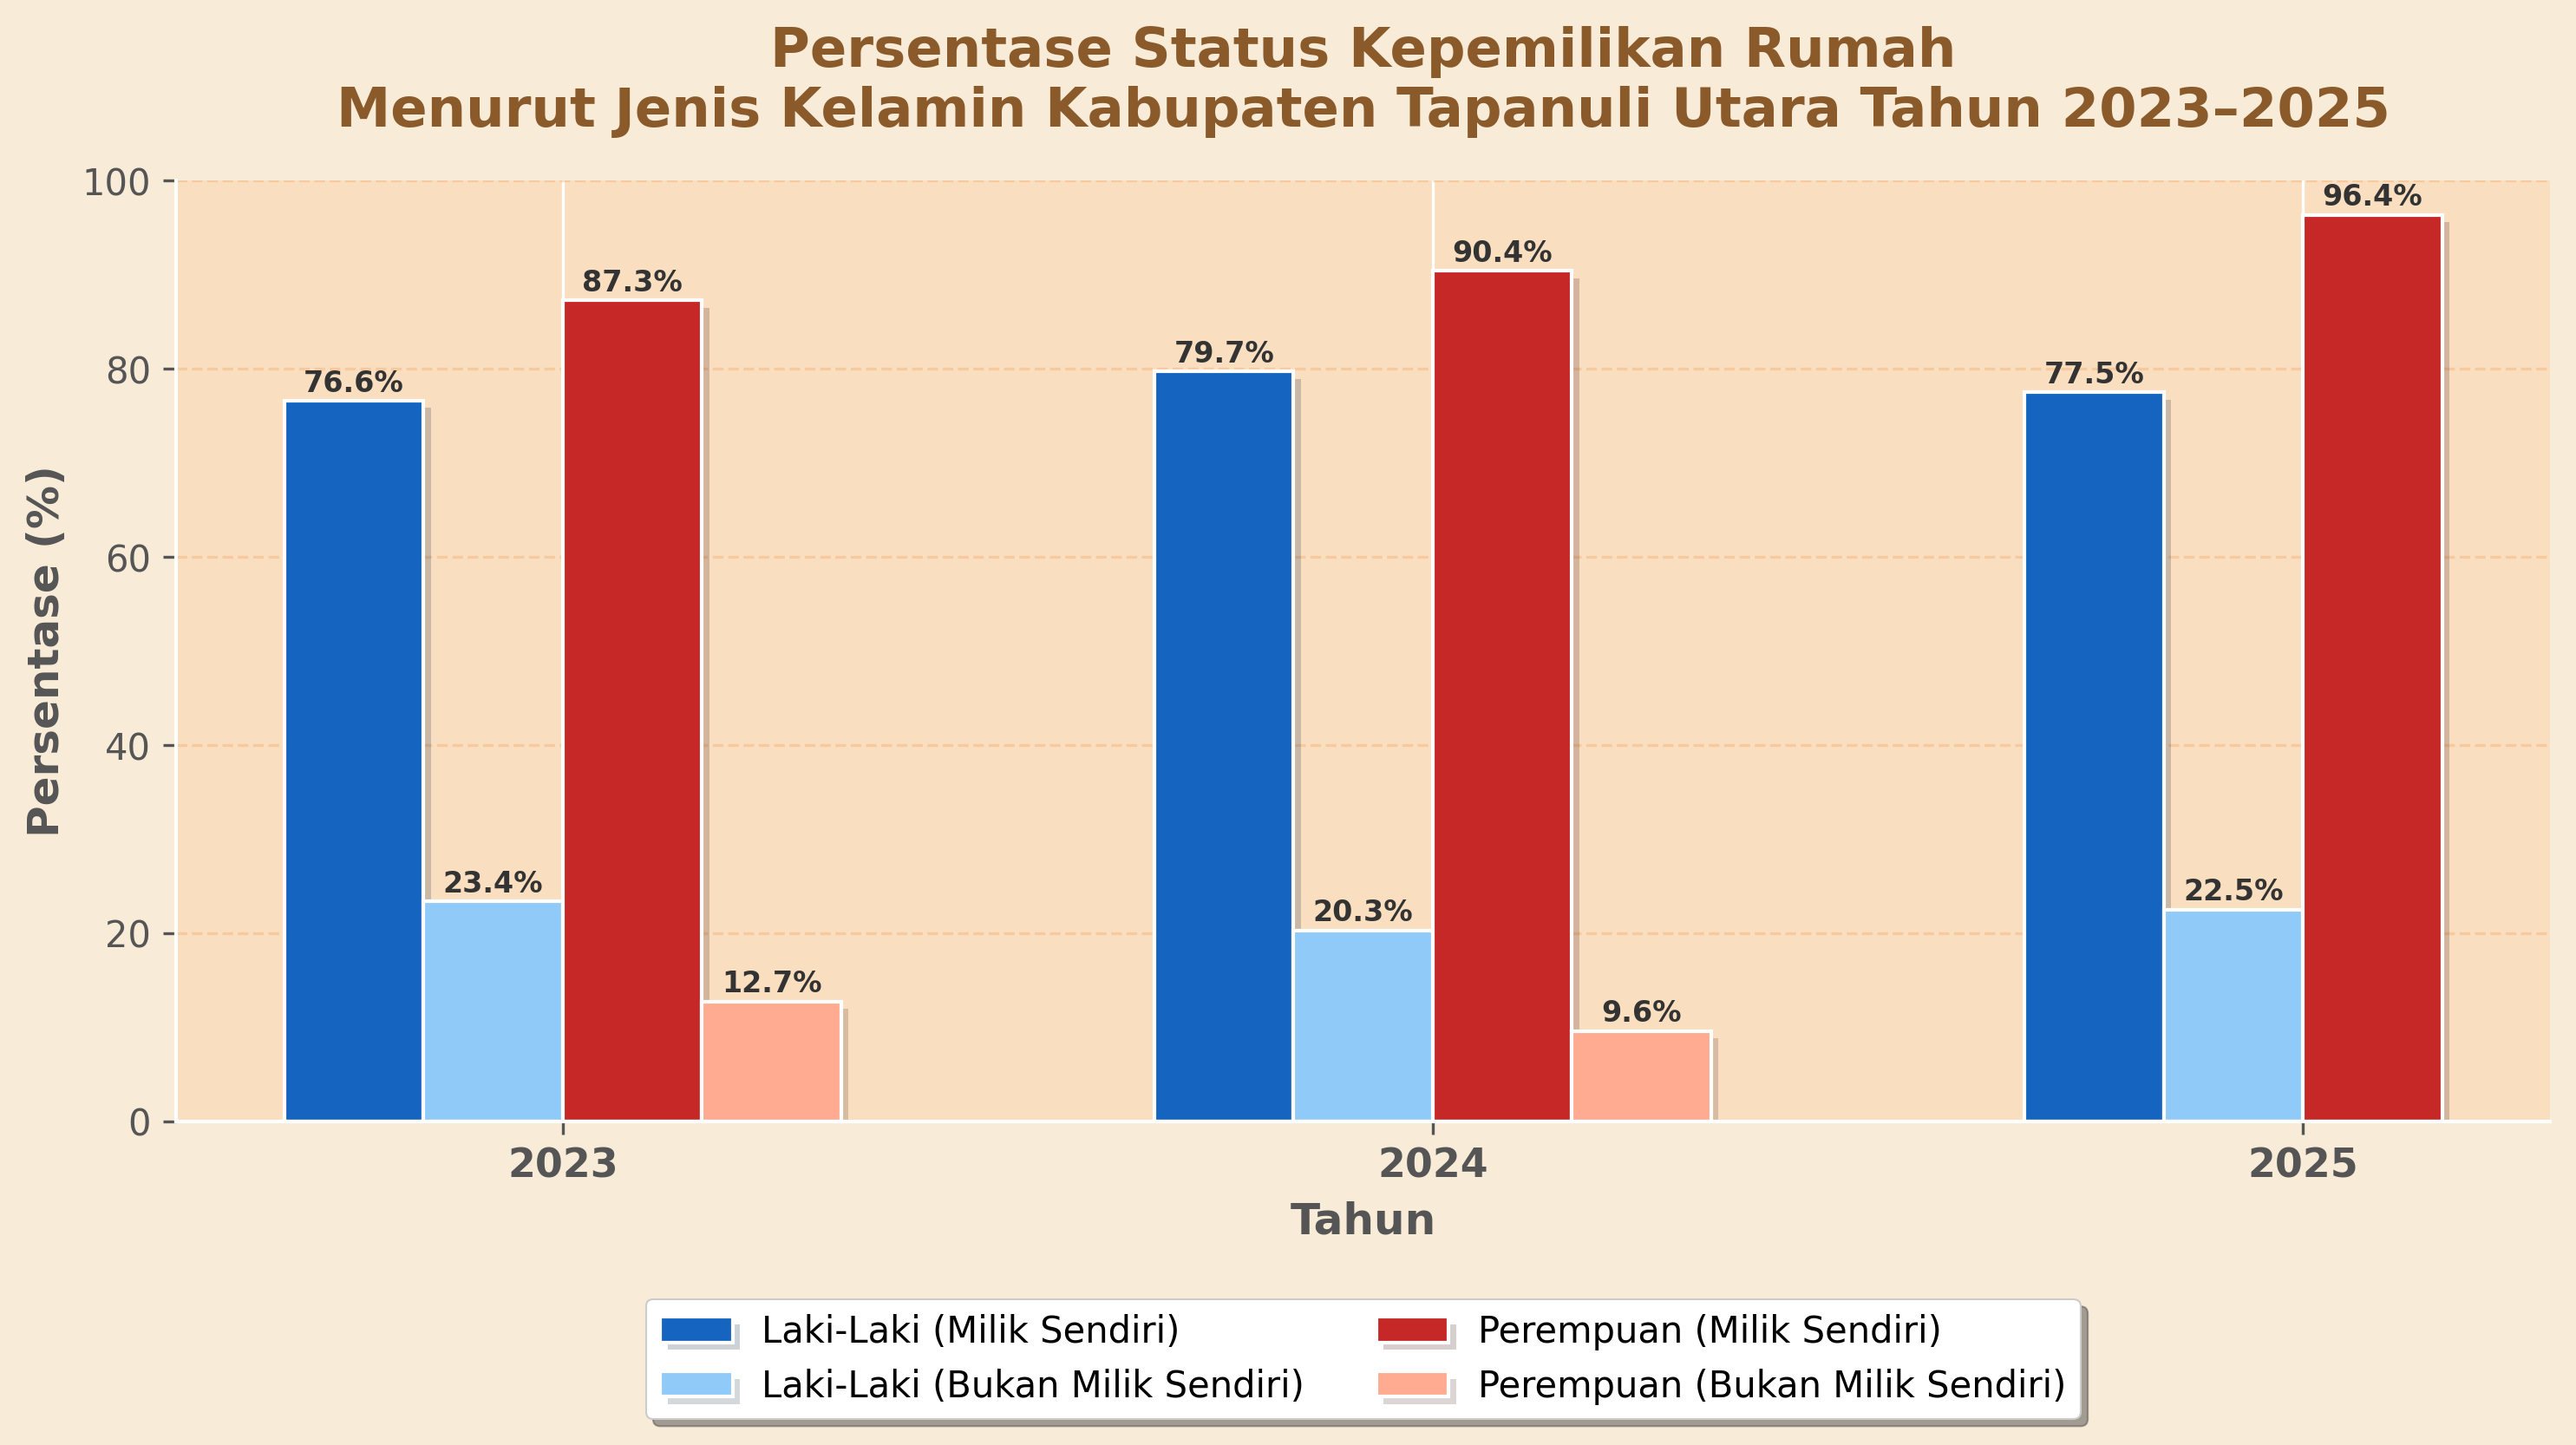

In [ ]:
df = sheets["Rumah"].copy()
df["Karakteristik"] = df["Karakteristik"].str.strip()
df = df[df["Karakteristik"].isin(["Laki-Laki", "Perempuan"])]

laki = df[df["Karakteristik"]=="Laki-Laki"].sort_values("Tahun")
perempuan = df[df["Karakteristik"]=="Perempuan"].sort_values("Tahun")

fig, ax = plt.subplots(figsize=(10,5.8), dpi=300)
fig.patch.set_facecolor("#F8EBD7")
ax.set_facecolor("#F9DFC0")

orange = "#8B5A2B"
warna = {
    "LM":"#1565C0",
    "LB":"#90CAF9",
    "PM":"#C62828",
    "PB":"#FFAB91"
}

x = np.arange(len(laki))
width = 0.16

bars1 = ax.bar(
    x-1.5*width,
    laki["Milik Sendiri"],
    width,
    color=warna["LM"],
    edgecolor="white",
    linewidth=1,
    label="Laki-Laki (Milik Sendiri)"
)

bars2 = ax.bar(
    x-0.5*width,
    laki["Bukan Milik Sendiri"],
    width,
    color=warna["LB"],
    edgecolor="white",
    linewidth=1,
    label="Laki-Laki (Bukan Milik Sendiri)"
)

bars3 = ax.bar(
    x+0.5*width,
    perempuan["Milik Sendiri"],
    width,
    color=warna["PM"],
    edgecolor="white",
    linewidth=1,
    label="Perempuan (Milik Sendiri)"
)

bars4 = ax.bar(
    x+1.5*width,
    perempuan["Bukan Milik Sendiri"],
    width,
    color=warna["PB"],
    edgecolor="white",
    linewidth=1,
    label="Perempuan (Bukan Milik Sendiri)"
)

for bars in [bars1,bars2,bars3,bars4]:
    for bar in bars:
        bar.set_path_effects([
            pe.SimplePatchShadow(offset=(2,-2),alpha=0.20),
            pe.Normal()
        ])

for bars in [bars1,bars2,bars3,bars4]:
    for bar in bars:
        h = bar.get_height()

        ax.text(
            bar.get_x()+bar.get_width()/2,
            h+1,
            f"{h:.1f}%",
            ha="center",
            fontsize=8,
            fontweight="bold",
            color="#333333"
        )

ax.set_xticks(x)

ax.set_xticklabels(
    ["2023","2024","2025"],
    fontsize=11,
    fontweight="bold"
)

ax.set_ylim(0,100)

ax.set_xlabel(
    "Tahun",
    fontsize=12,
    fontweight="bold"
)

ax.set_ylabel(
    "Persentase (%)",
    fontsize=12,
    fontweight="bold"
)

ax.set_title(
    "Persentase Status Kepemilikan Rumah\n"
    "Menurut Jenis Kelamin Kabupaten Tapanuli Utara Tahun 2023–2025",
    fontsize=15,
    fontweight="bold",
    color=orange,
    pad=15
)

ax.grid(
    axis="y",
    linestyle="--",
    color="#F4A261",
    alpha=0.35
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

legend = ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5,-0.17),
    ncol=2,
    frameon=True,
    fancybox=True,
    shadow=True,
    fontsize=10
)

legend.get_frame().set_facecolor("white")

plt.tight_layout()
plt.show()

### **VISUALISASI 5: Sumber Air Utama Rumah Tangga**

#### **a. Persentase Air Kemasan Bermerek, Air Isi Ulang, Leding Menurut Jenis Kelamin Kabupaten Tapanuli Utara Tahun 2023–2025**

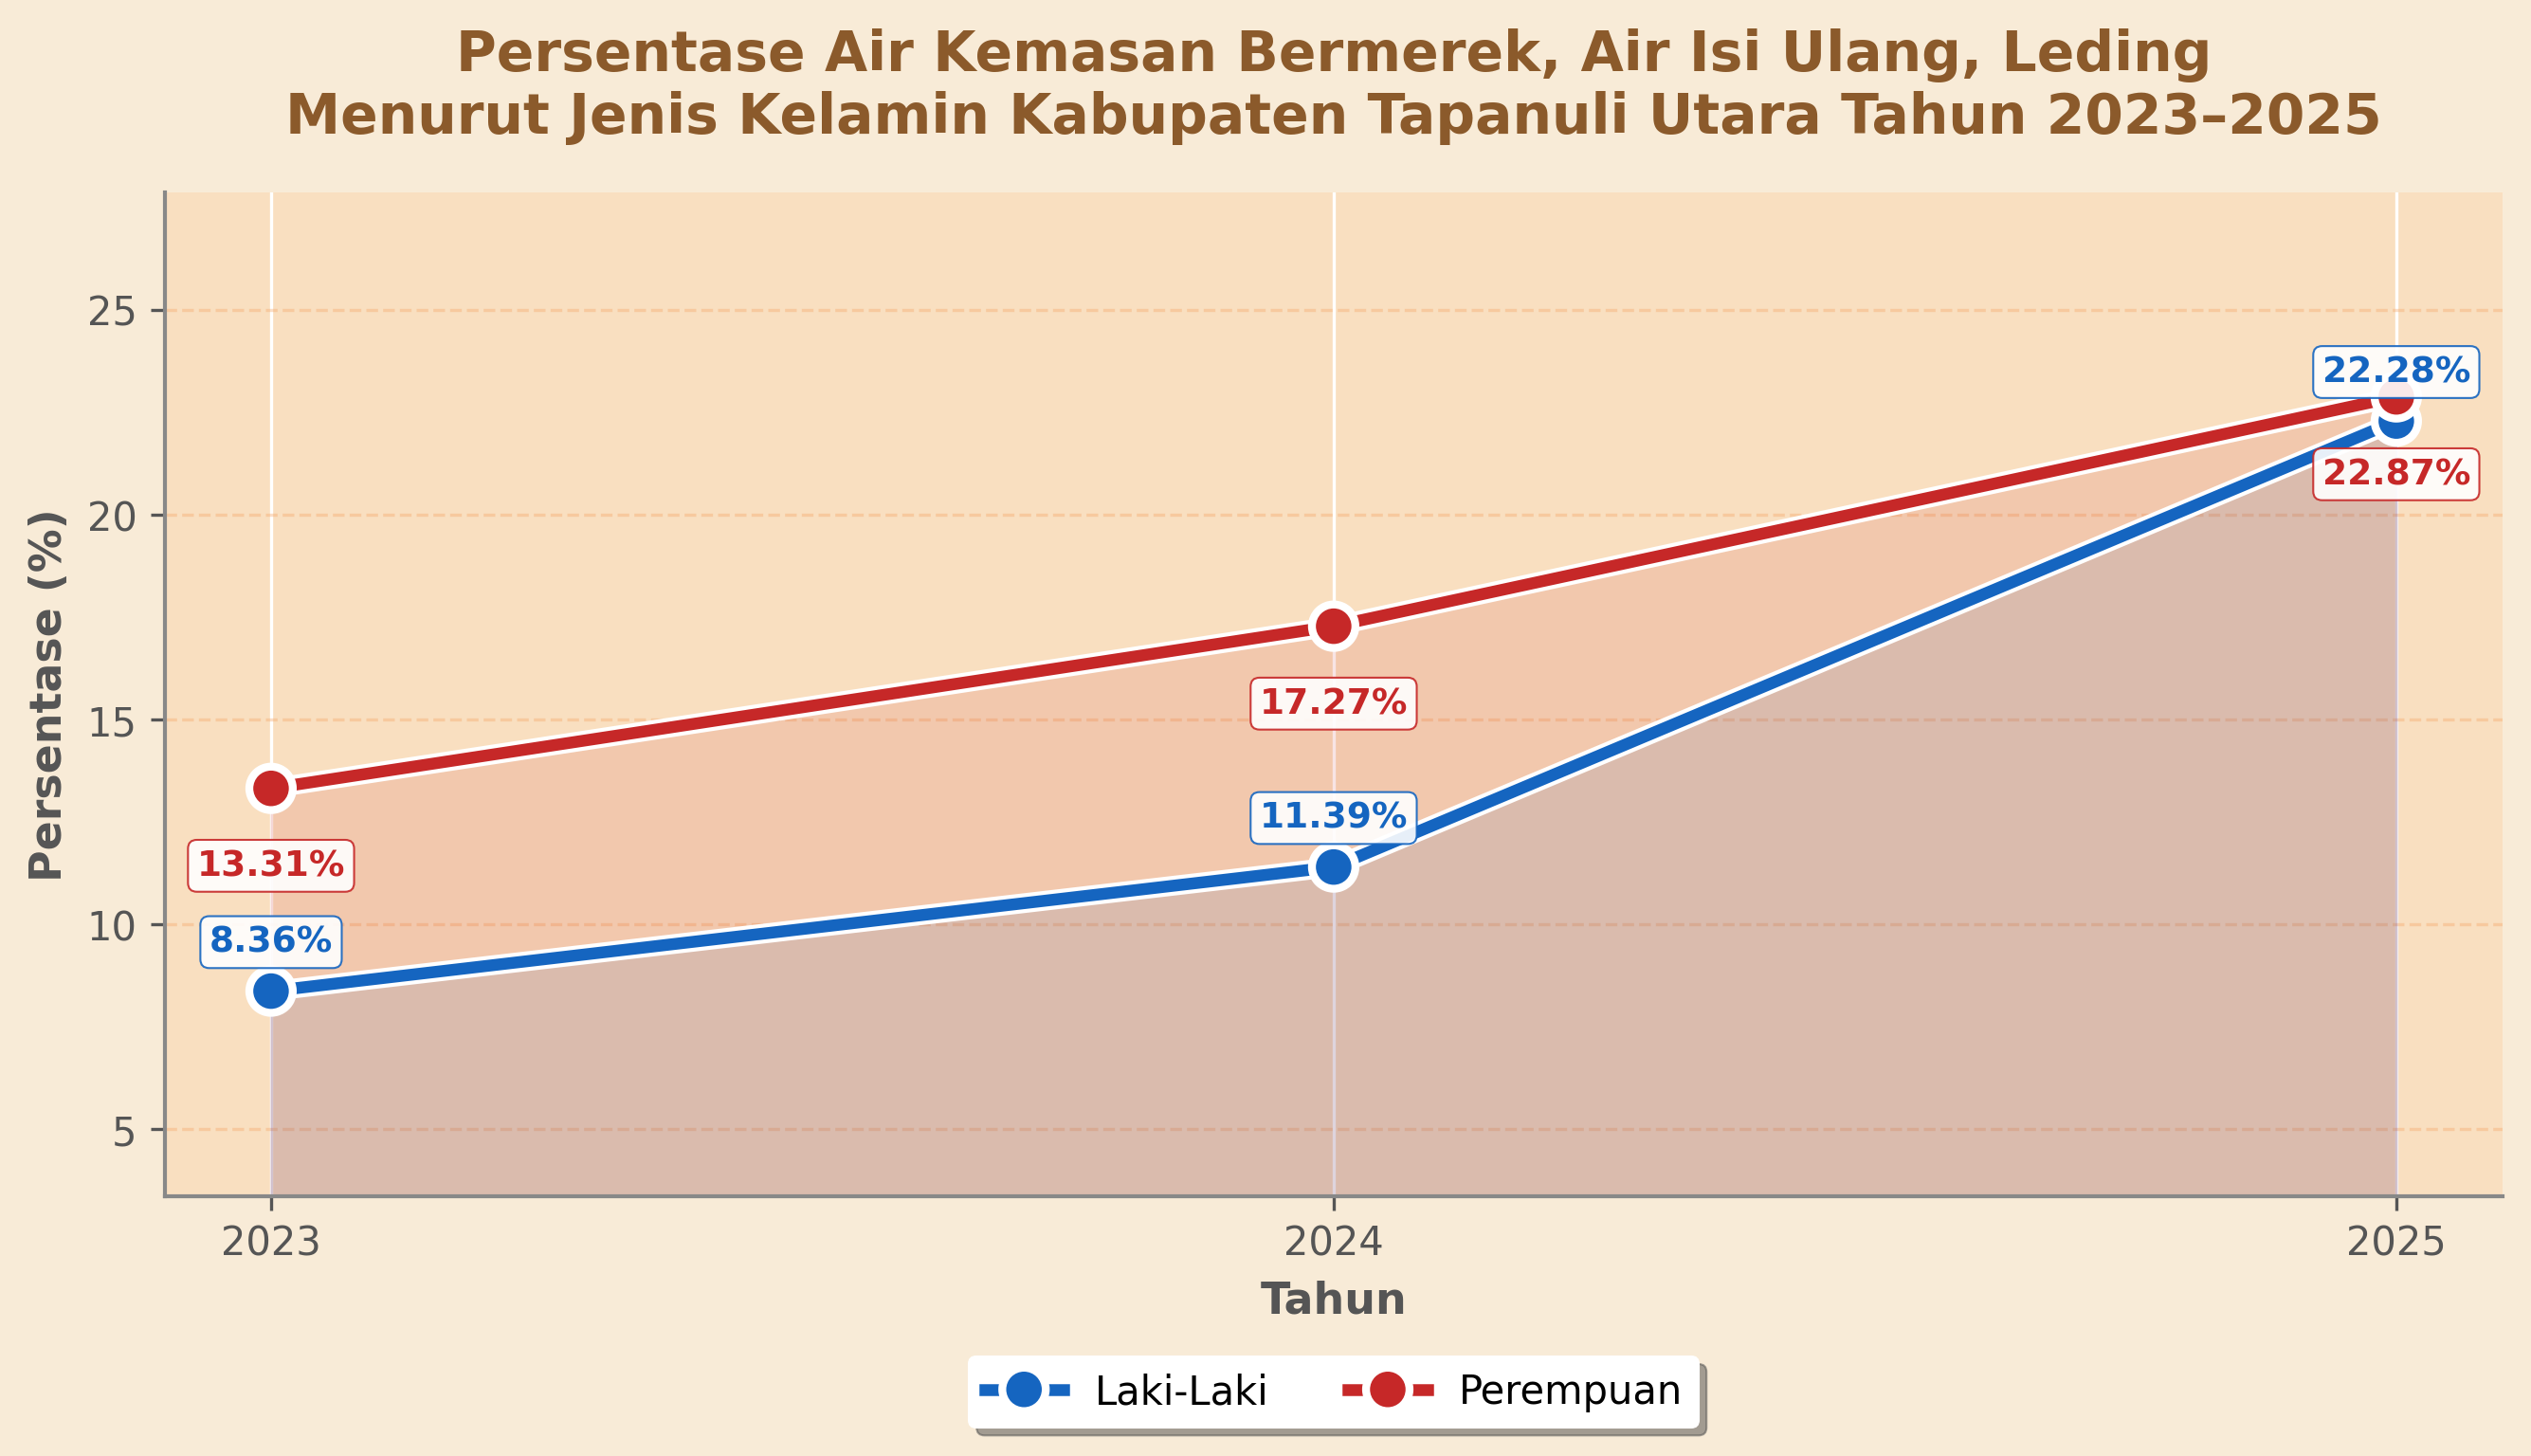

In [ ]:
df = sheets["Air"].copy()
df["Karakteristik"] = df["Karakteristik"].str.strip()
df = df[df["Karakteristik"].isin(["Laki-Laki", "Perempuan"])]

laki = df[df["Karakteristik"]=="Laki-Laki"].sort_values("Tahun")
perempuan = df[df["Karakteristik"]=="Perempuan"].sort_values("Tahun")
kolom = "Air Kemasan/Leding"

fig, ax = plt.subplots(figsize=(9,5.3), dpi=300)
fig.patch.set_facecolor("#F8EBD7")
ax.set_facecolor("#F9DFC0")

biru = "#1565C0"
merah = "#C62828"
judul = "#8B5A2B"

line1, = ax.plot(
    laki["Tahun"],
    laki[kolom],
    color=biru,
    linewidth=3,
    marker="o",
    markersize=8,
    label="Laki-Laki"
)

line2, = ax.plot(
    perempuan["Tahun"],
    perempuan[kolom],
    color=merah,
    linewidth=3,
    marker="o",
    markersize=8,
    label="Perempuan"
)

for line in [line1, line2]:
    line.set_path_effects([
        pe.Stroke(linewidth=5, foreground="white"),
        pe.Normal()
    ])

ax.fill_between(
    laki["Tahun"],
    laki[kolom],
    alpha=0.12,
    color=biru
)

ax.fill_between(
    perempuan["Tahun"],
    perempuan[kolom],
    alpha=0.12,
    color=merah
)

for x, y in zip(laki["Tahun"], laki[kolom]):
    ax.annotate(
        f"{y:.2f}%",
        (x, y),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold",
        color=biru,
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor="white",
            edgecolor=biru,
            alpha=0.9
        )
    )

for x, y in zip(perempuan["Tahun"], perempuan[kolom]):
    ax.annotate(
        f"{y:.2f}%",
        (x, y),
        xytext=(0, -22),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold",
        color=merah,
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor="white",
            edgecolor=merah,
            alpha=0.9
        )
    )

ax.set_xticks([2023, 2024, 2025])

ax.set_xlabel(
    "Tahun",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel(
    "Persentase (%)",
    fontsize=11,
    fontweight="bold"
)

ax.set_title(
    f"Persentase Air Kemasan Bermerek, Air Isi Ulang, Leding\n"
    "Menurut Jenis Kelamin Kabupaten Tapanuli Utara Tahun 2023–2025",
    fontsize=14,
    fontweight="bold",
    color=judul,
    pad=15
)

ax.grid(
    axis="y",
    linestyle="--",
    color="#F4A261",
    alpha=0.35
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("#888888")
ax.spines["bottom"].set_color("#888888")

ymin = min(df[kolom]) - 5
ymax = max(df[kolom]) + 5
ax.set_ylim(ymin, ymax)

legend = ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.14),
    ncol=2,
    frameon=True,
    fancybox=True,
    shadow=True,
    fontsize=10
)

legend.get_frame().set_facecolor("white")
legend.get_frame().set_edgecolor("white")

plt.tight_layout()
plt.show()

#### **b. Persentase Sumur Bor/ Pompa Sumur Terlindung, Mata Air Terlindung, Air Hujan Menurut Jenis Kelamin Kabupaten Tapanuli Utara Tahun 2023–2025**

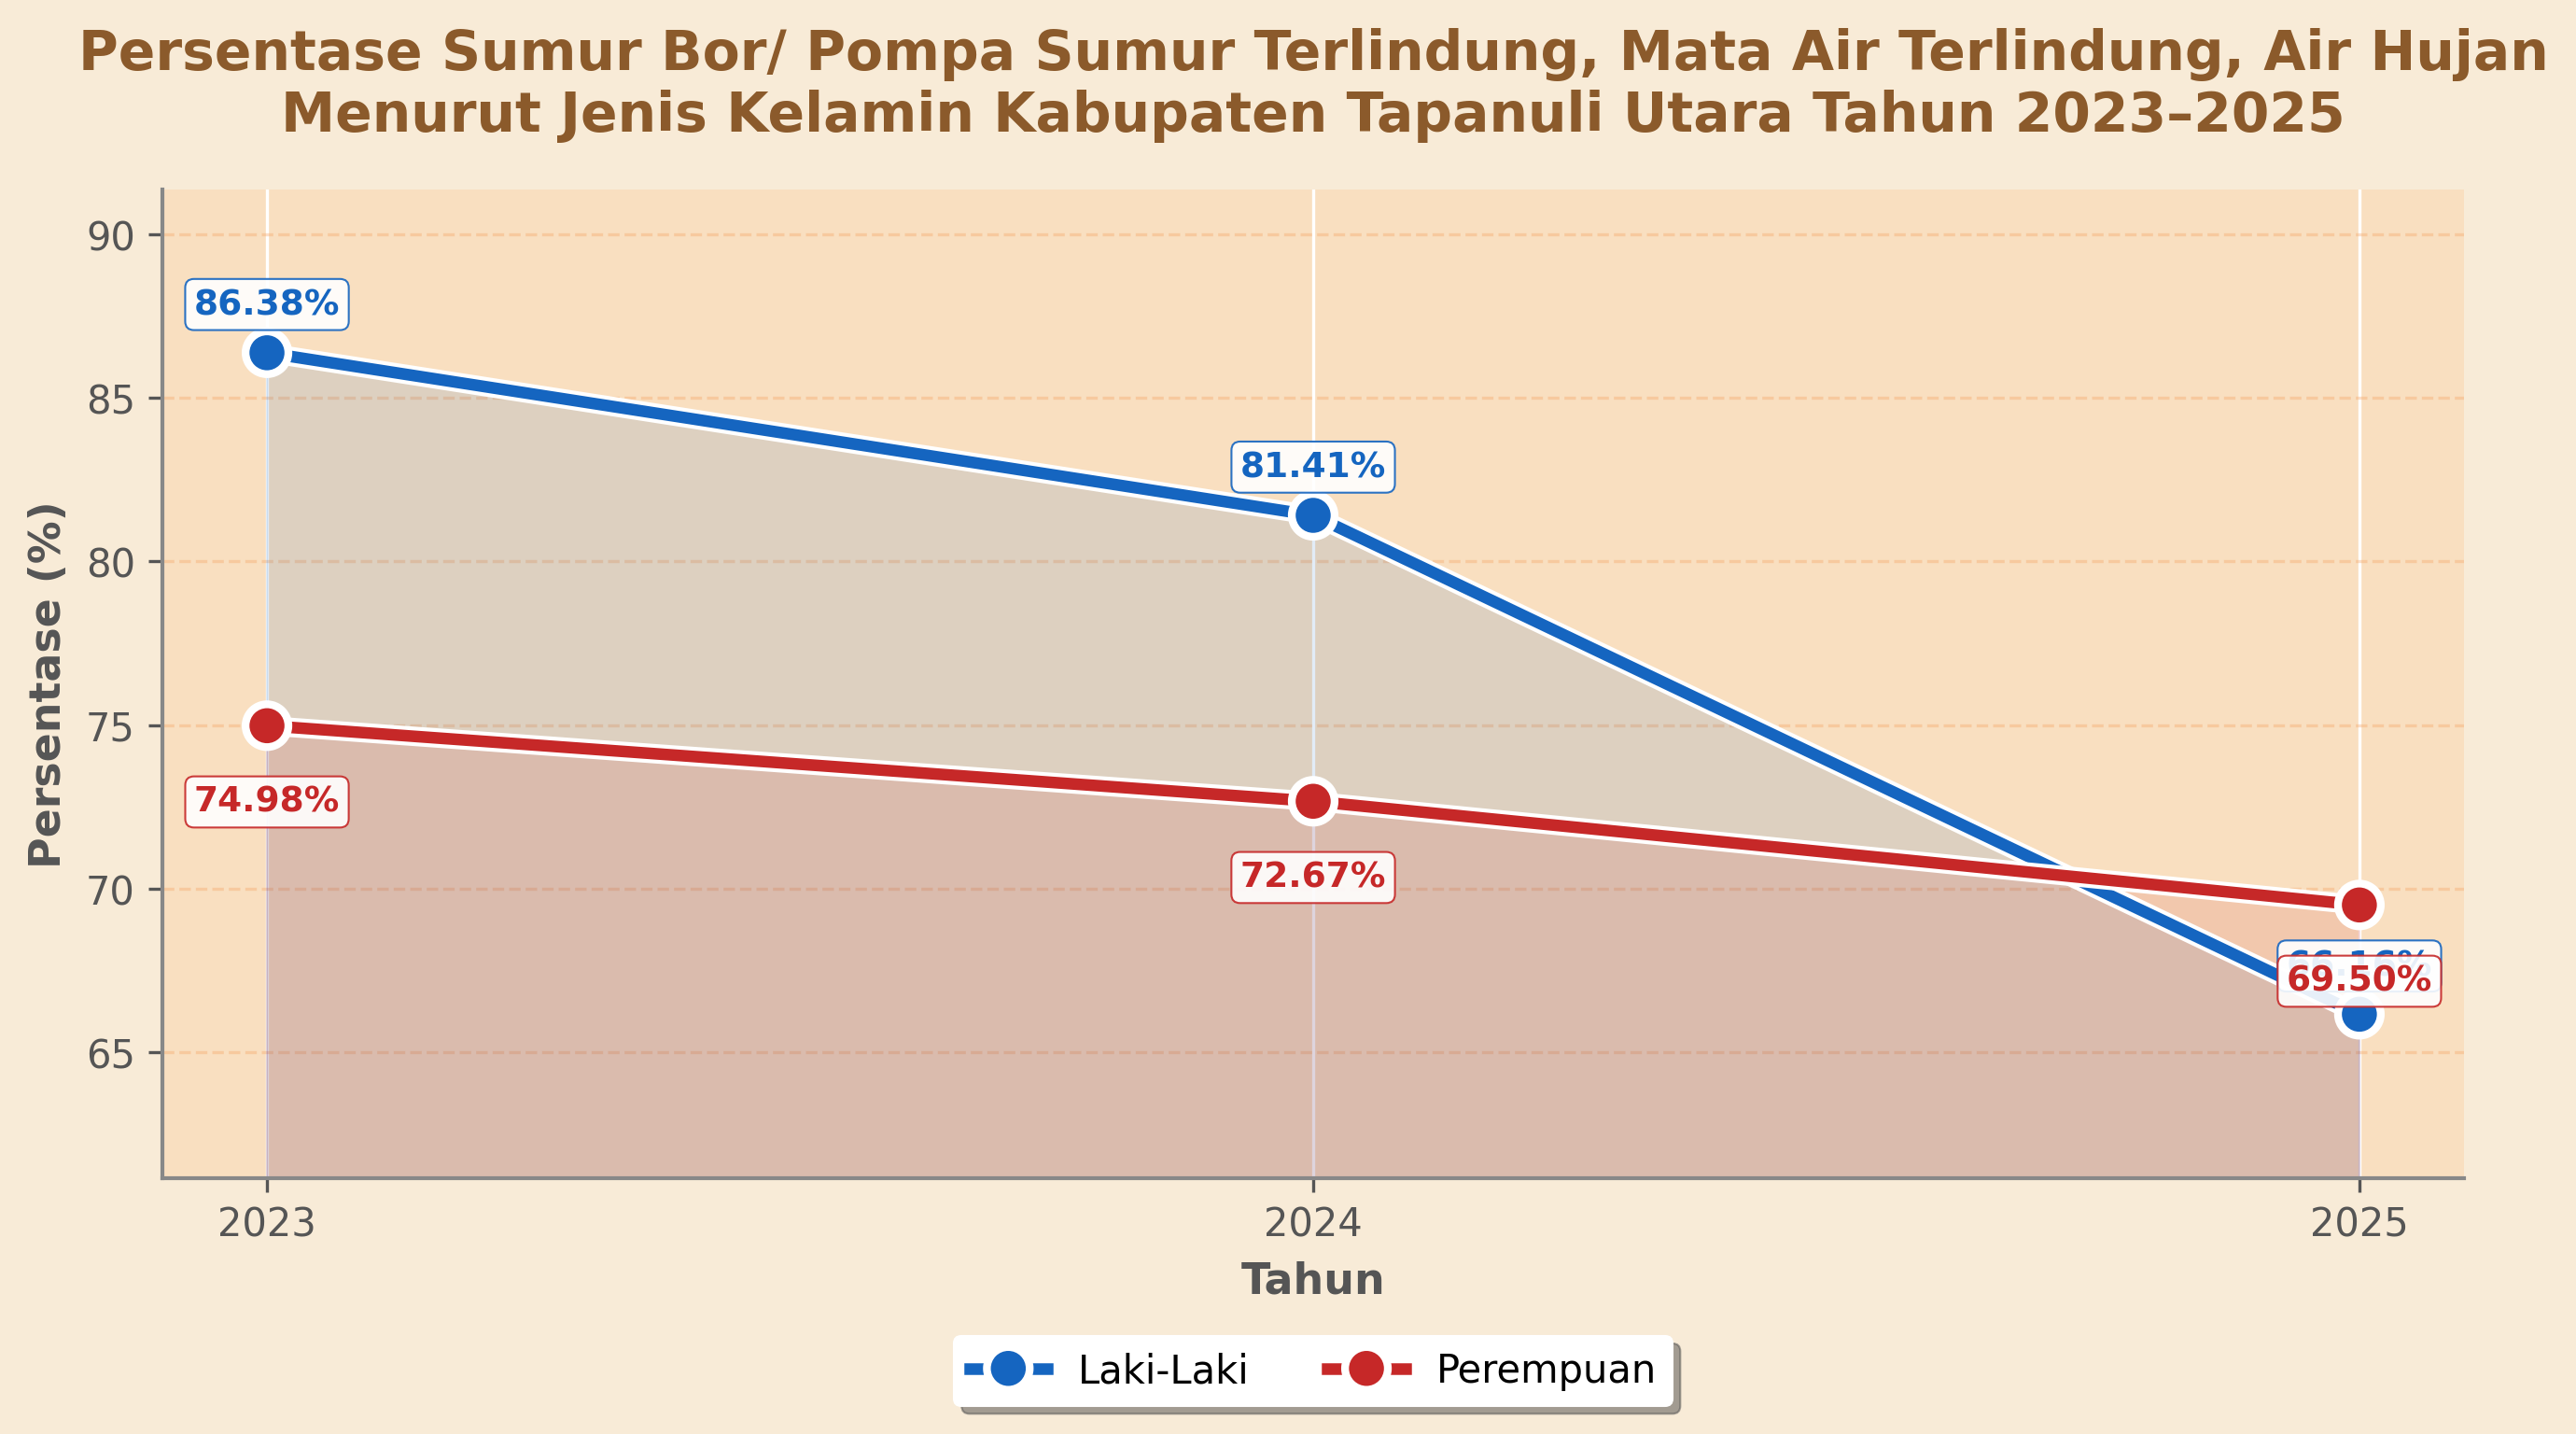

In [ ]:
df = sheets["Air"].copy()
df["Karakteristik"] = df["Karakteristik"].str.strip()
df = df[df["Karakteristik"].isin(["Laki-Laki", "Perempuan"])]

laki = df[df["Karakteristik"]=="Laki-Laki"].sort_values("Tahun")
perempuan = df[df["Karakteristik"]=="Perempuan"].sort_values("Tahun")
kolom = "Sumur/Mata Air"

fig, ax = plt.subplots(figsize=(9,5.3), dpi=300)
fig.patch.set_facecolor("#F8EBD7")
ax.set_facecolor("#F9DFC0")

biru = "#1565C0"
merah = "#C62828"
judul = "#8B5A2B"

line1, = ax.plot(
    laki["Tahun"],
    laki[kolom],
    color=biru,
    linewidth=3,
    marker="o",
    markersize=8,
    label="Laki-Laki"
)

line2, = ax.plot(
    perempuan["Tahun"],
    perempuan[kolom],
    color=merah,
    linewidth=3,
    marker="o",
    markersize=8,
    label="Perempuan"
)

for line in [line1, line2]:
    line.set_path_effects([
        pe.Stroke(linewidth=5, foreground="white"),
        pe.Normal()
    ])

ax.fill_between(
    laki["Tahun"],
    laki[kolom],
    alpha=0.12,
    color=biru
)

ax.fill_between(
    perempuan["Tahun"],
    perempuan[kolom],
    alpha=0.12,
    color=merah
)

for x, y in zip(laki["Tahun"], laki[kolom]):
    ax.annotate(
        f"{y:.2f}%",
        (x, y),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold",
        color=biru,
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor="white",
            edgecolor=biru,
            alpha=0.9
        )
    )

for x, y in zip(perempuan["Tahun"], perempuan[kolom]):
    ax.annotate(
        f"{y:.2f}%",
        (x, y),
        xytext=(0, -22),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold",
        color=merah,
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor="white",
            edgecolor=merah,
            alpha=0.9
        )
    )

ax.set_xticks([2023, 2024, 2025])

ax.set_xlabel(
    "Tahun",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel(
    "Persentase (%)",
    fontsize=11,
    fontweight="bold"
)

ax.set_title(
    f"Persentase Sumur Bor/ Pompa Sumur Terlindung, Mata Air Terlindung, Air Hujan\n"
    "Menurut Jenis Kelamin Kabupaten Tapanuli Utara Tahun 2023–2025",
    fontsize=14,
    fontweight="bold",
    color=judul,
    pad=15
)

ax.grid(
    axis="y",
    linestyle="--",
    color="#F4A261",
    alpha=0.35
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("#888888")
ax.spines["bottom"].set_color("#888888")

ymin = min(df[kolom]) - 5
ymax = max(df[kolom]) + 5
ax.set_ylim(ymin, ymax)

legend = ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.14),
    ncol=2,
    frameon=True,
    fancybox=True,
    shadow=True,
    fontsize=10
)

legend.get_frame().set_facecolor("white")
legend.get_frame().set_edgecolor("white")

plt.tight_layout()
plt.show()

#### **c. Persentase Sumber Air Utama Lainnya Menurut Jenis Kelamin Kabupaten Tapanuli Utara Tahun 2023–2025**

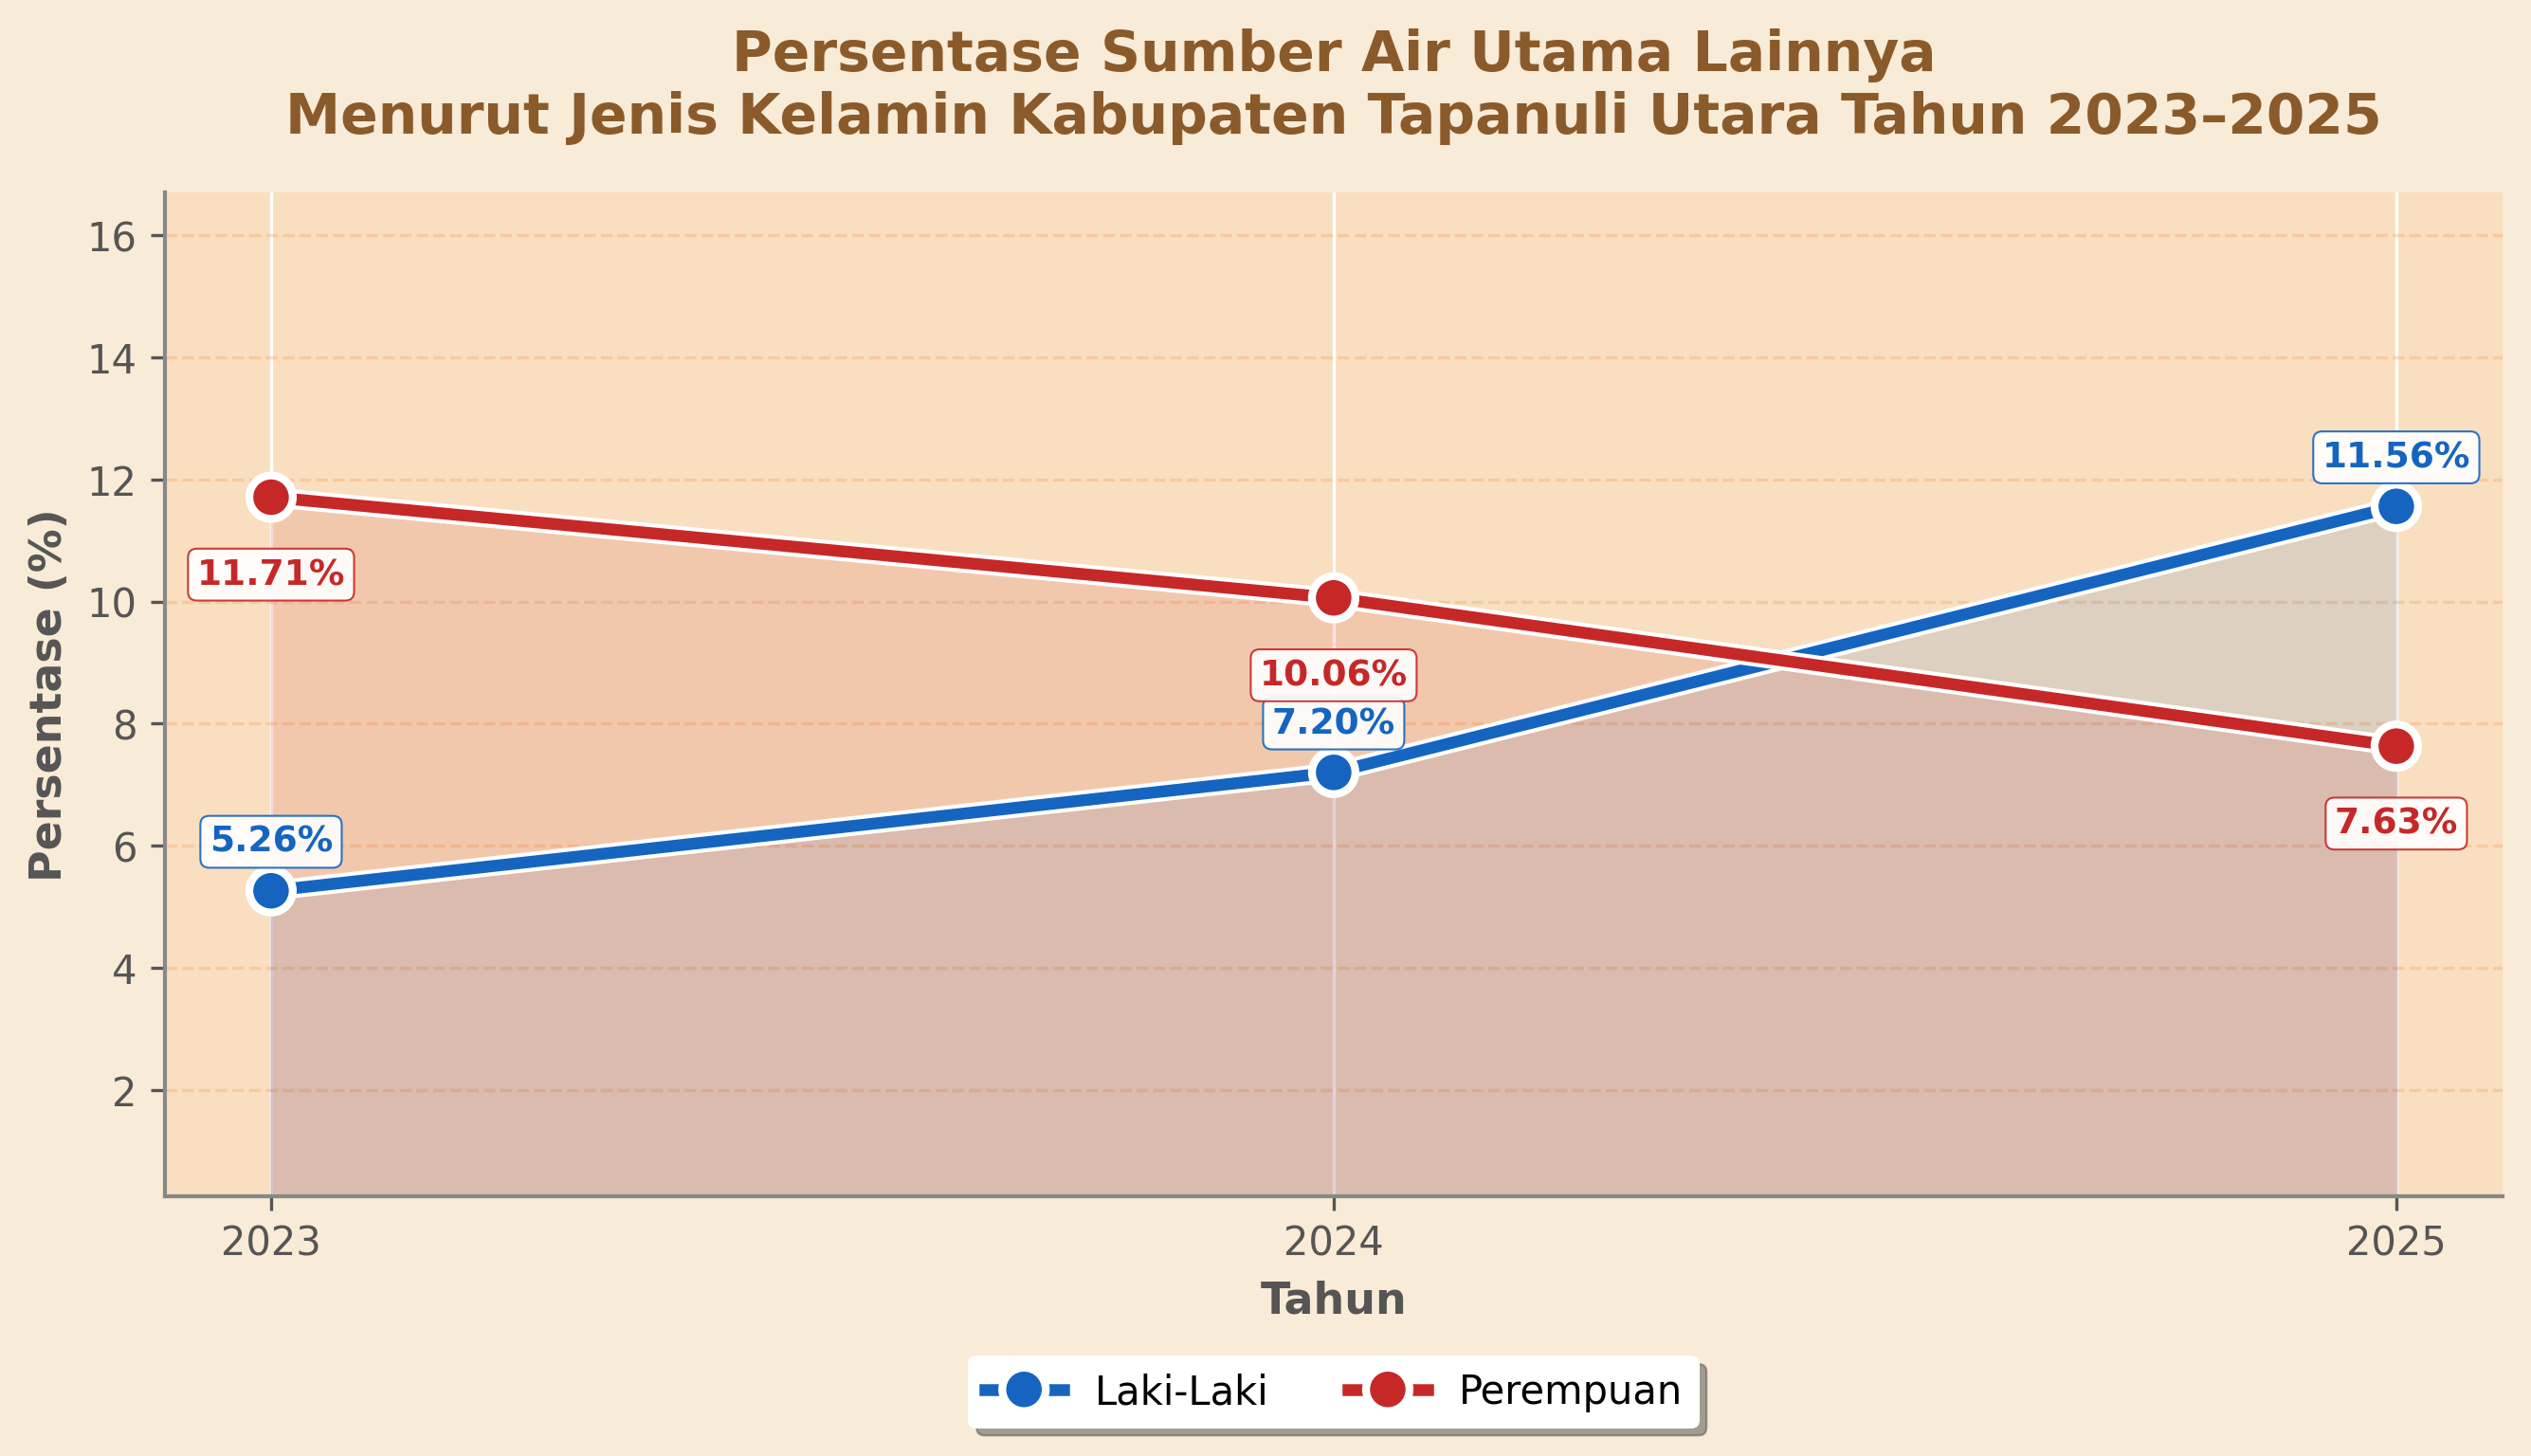

In [ ]:
df = sheets["Air"].copy()
df["Karakteristik"] = df["Karakteristik"].str.strip()
df = df[df["Karakteristik"].isin(["Laki-Laki", "Perempuan"])]

laki = df[df["Karakteristik"]=="Laki-Laki"].sort_values("Tahun")
perempuan = df[df["Karakteristik"]=="Perempuan"].sort_values("Tahun")
kolom = "Lainnya"

fig, ax = plt.subplots(figsize=(9,5.3), dpi=300)
fig.patch.set_facecolor("#F8EBD7")
ax.set_facecolor("#F9DFC0")

biru = "#1565C0"
merah = "#C62828"
judul = "#8B5A2B"

line1, = ax.plot(
    laki["Tahun"],
    laki[kolom],
    color=biru,
    linewidth=3,
    marker="o",
    markersize=8,
    label="Laki-Laki"
)

line2, = ax.plot(
    perempuan["Tahun"],
    perempuan[kolom],
    color=merah,
    linewidth=3,
    marker="o",
    markersize=8,
    label="Perempuan"
)

for line in [line1, line2]:
    line.set_path_effects([
        pe.Stroke(linewidth=5, foreground="white"),
        pe.Normal()
    ])

ax.fill_between(
    laki["Tahun"],
    laki[kolom],
    alpha=0.12,
    color=biru
)

ax.fill_between(
    perempuan["Tahun"],
    perempuan[kolom],
    alpha=0.12,
    color=merah
)

for x, y in zip(laki["Tahun"], laki[kolom]):
    ax.annotate(
        f"{y:.2f}%",
        (x, y),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold",
        color=biru,
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor="white",
            edgecolor=biru,
            alpha=0.9
        )
    )

for x, y in zip(perempuan["Tahun"], perempuan[kolom]):
    ax.annotate(
        f"{y:.2f}%",
        (x, y),
        xytext=(0, -22),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold",
        color=merah,
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor="white",
            edgecolor=merah,
            alpha=0.9
        )
    )

ax.set_xticks([2023, 2024, 2025])

ax.set_xlabel(
    "Tahun",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel(
    "Persentase (%)",
    fontsize=11,
    fontweight="bold"
)

ax.set_title(
    f"Persentase Sumber Air Utama Lainnya\n"
    "Menurut Jenis Kelamin Kabupaten Tapanuli Utara Tahun 2023–2025",
    fontsize=14,
    fontweight="bold",
    color=judul,
    pad=15
)

ax.grid(
    axis="y",
    linestyle="--",
    color="#F4A261",
    alpha=0.35
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("#888888")
ax.spines["bottom"].set_color("#888888")

ymin = min(df[kolom]) - 5
ymax = max(df[kolom]) + 5
ax.set_ylim(ymin, ymax)

legend = ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.14),
    ncol=2,
    frameon=True,
    fancybox=True,
    shadow=True,
    fontsize=10
)

legend.get_frame().set_facecolor("white")
legend.get_frame().set_edgecolor("white")

plt.tight_layout()
plt.show()

### **VISUALISASI 6: Persentase Penduduk yang Menggunakan HP dan Internet Menurut Jenis Kelamin Kabupaten Tapanuli Utara Tahun 2023–2025**

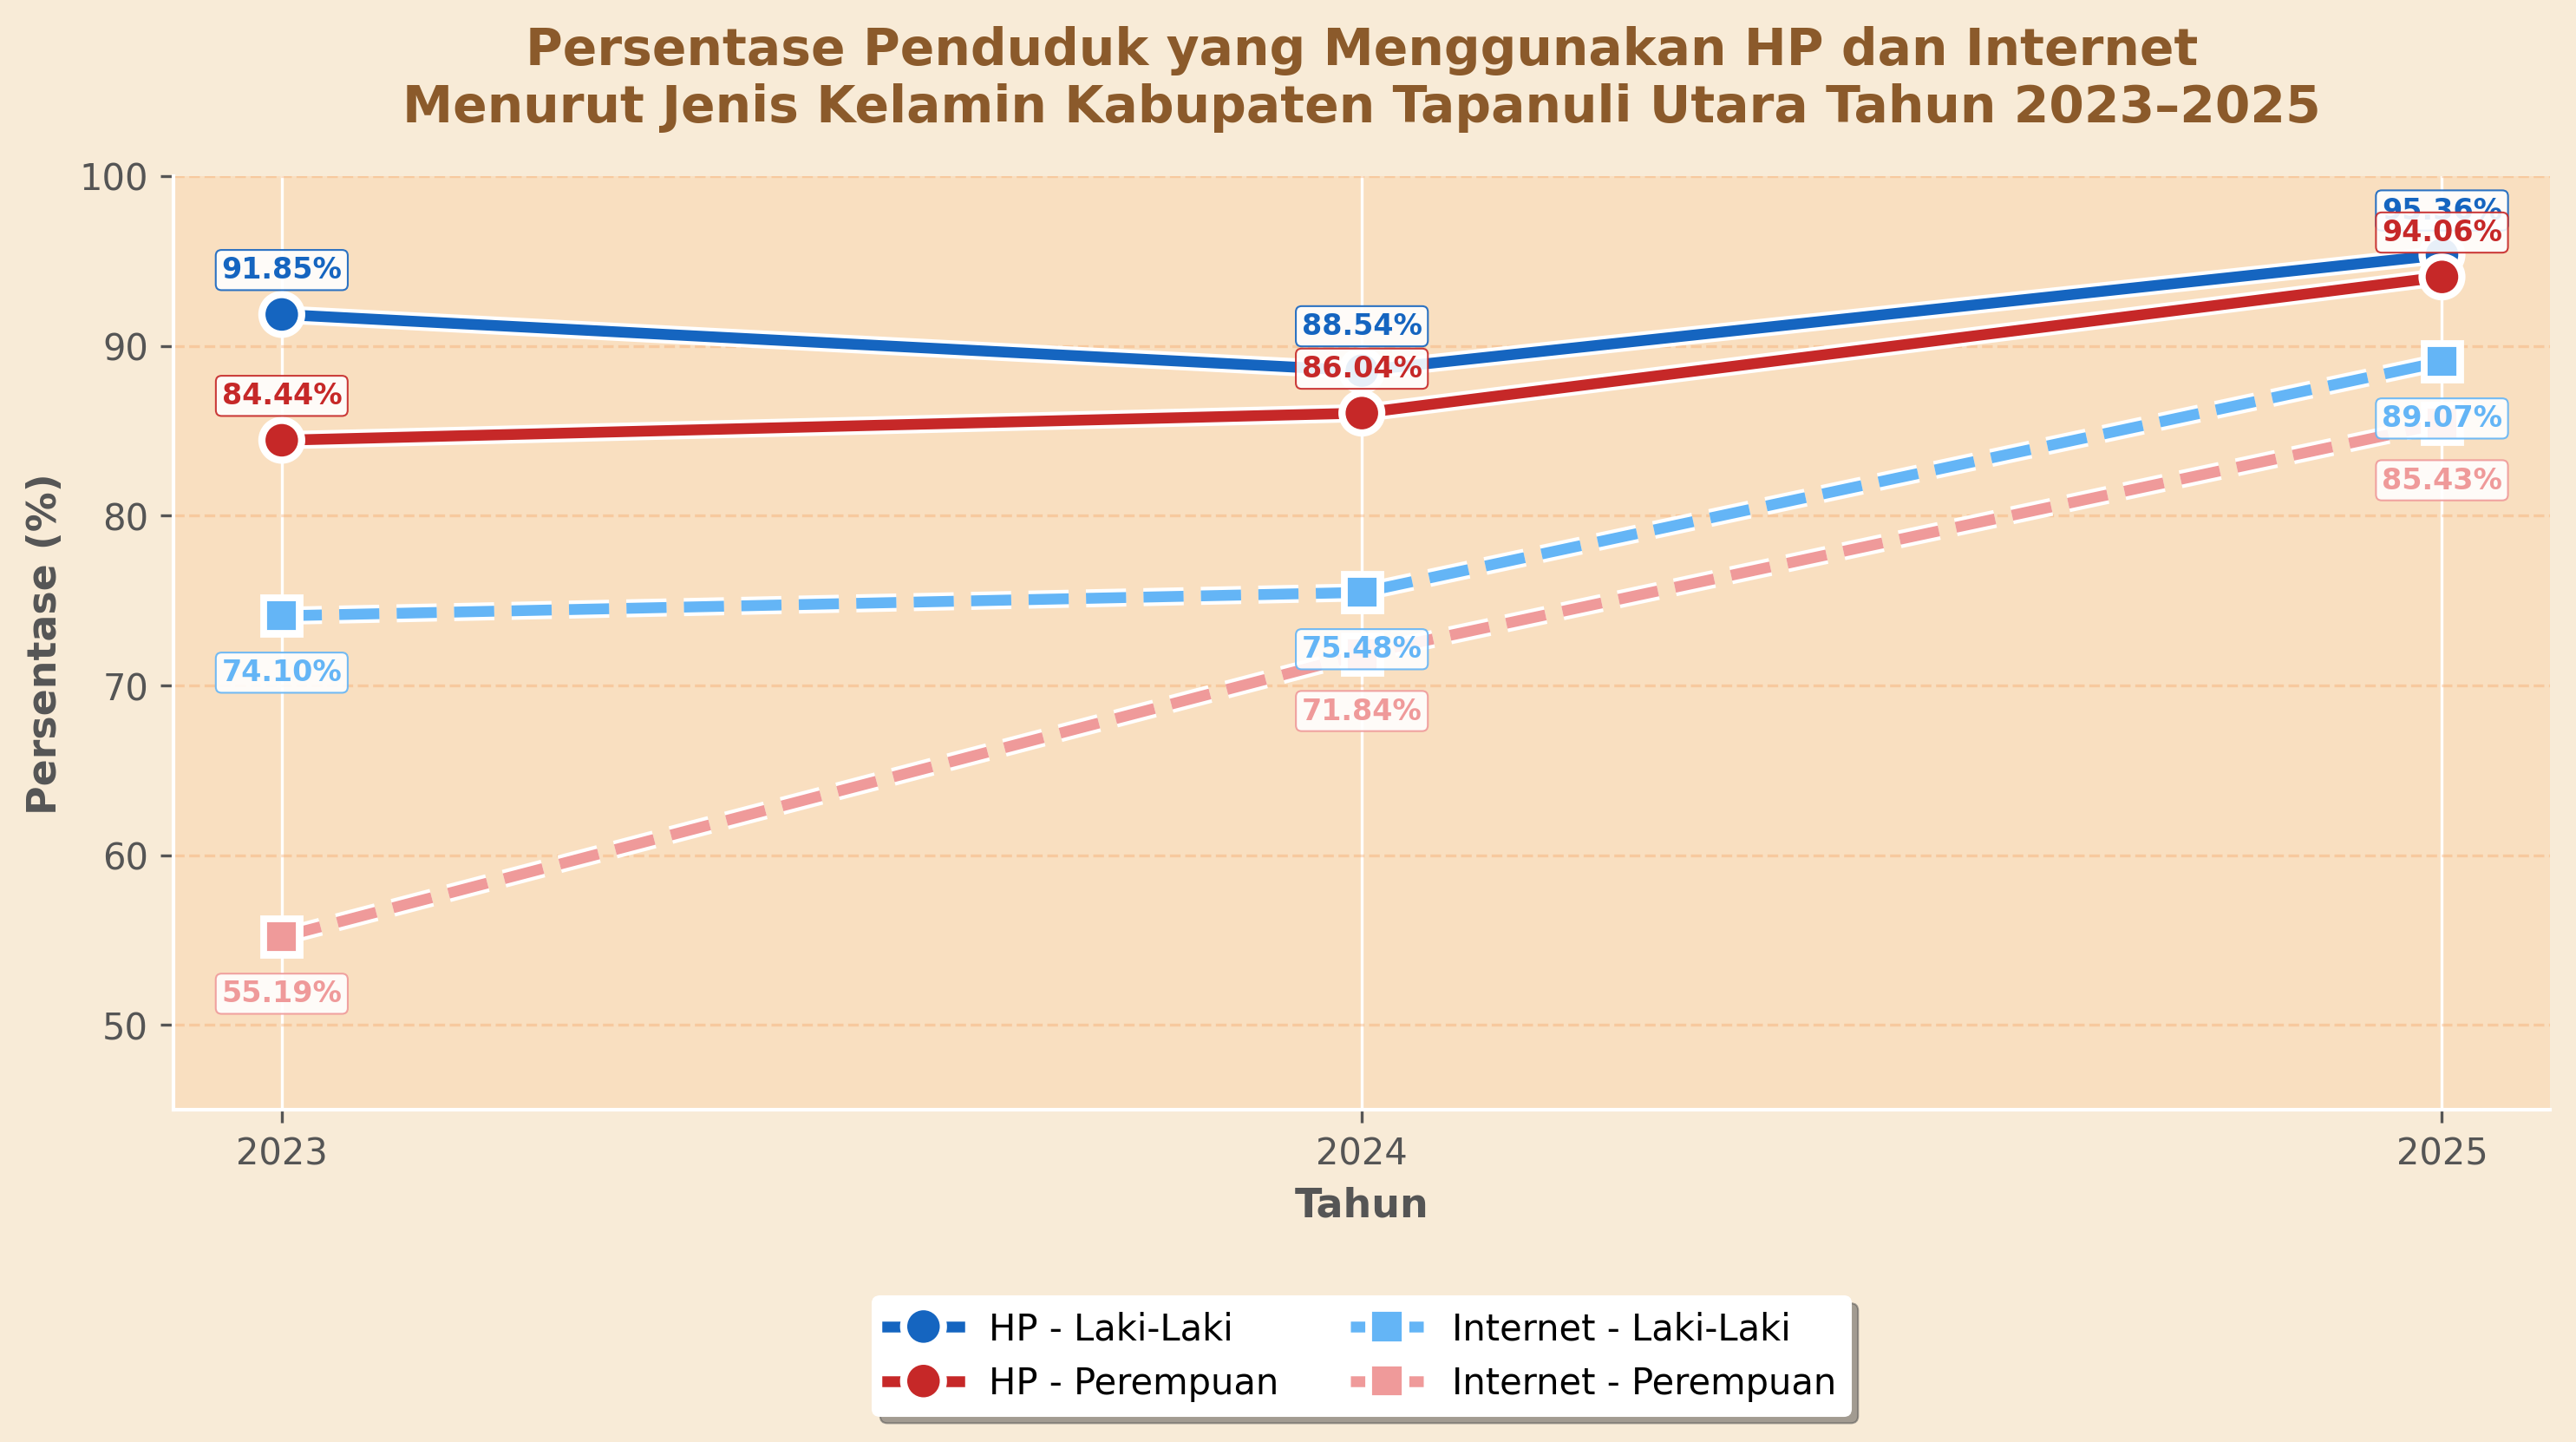

In [ ]:
df = sheets["Teknologi"].copy()
df["Karakteristik"] = df["Karakteristik"].str.strip()
df = df[df["Karakteristik"].isin(["Laki-Laki", "Perempuan"])]

laki = df[df["Karakteristik"] == "Laki-Laki"].sort_values("Tahun")
perempuan = df[df["Karakteristik"] == "Perempuan"].sort_values("Tahun")

fig, ax = plt.subplots(figsize=(10,5.8), dpi=300)
fig.patch.set_facecolor("#F8EBD7")
ax.set_facecolor("#F9DFC0")

biru = "#1565C0"
biru_muda = "#64B5F6"
merah = "#C62828"
merah_muda = "#EF9A9A"
judul = "#8B5A2B"

hp_laki, = ax.plot(
    laki["Tahun"],
    laki["Menggunakan HP"],
    color=biru,
    linewidth=3,
    marker="o",
    markersize=8,
    label="HP - Laki-Laki"
)

hp_perempuan, = ax.plot(
    perempuan["Tahun"],
    perempuan["Menggunakan HP"],
    color=merah,
    linewidth=3,
    marker="o",
    markersize=8,
    label="HP - Perempuan"
)

internet_laki, = ax.plot(
    laki["Tahun"],
    laki["Menggunakan Internet"],
    color=biru_muda,
    linewidth=3,
    linestyle="--",
    marker="s",
    markersize=7,
    label="Internet - Laki-Laki"
)

internet_perempuan, = ax.plot(
    perempuan["Tahun"],
    perempuan["Menggunakan Internet"],
    color=merah_muda,
    linewidth=3,
    linestyle="--",
    marker="s",
    markersize=7,
    label="Internet - Perempuan"
)

for line in [hp_laki, hp_perempuan, internet_laki, internet_perempuan]:
    line.set_path_effects([
        pe.Stroke(linewidth=5, foreground="white"),
        pe.Normal()
    ])

def label(data, kolom, warna, atas=True):
    for x, y in zip(data["Tahun"], data[kolom]):
        ax.annotate(
            f"{y:.2f}%",
            (x, y),
            xytext=(0, 10 if atas else -18),
            textcoords="offset points",
            ha="center",
            fontsize=8,
            fontweight="bold",
            color=warna,
            bbox=dict(
                boxstyle="round,pad=0.2",
                facecolor="white",
                edgecolor=warna,
                alpha=0.90
            )
        )

label(laki, "Menggunakan HP", biru, True)
label(perempuan, "Menggunakan HP", merah, True)

label(laki, "Menggunakan Internet", biru_muda, False)
label(perempuan, "Menggunakan Internet", merah_muda, False)

ax.set_xticks([2023,2024,2025])

ax.set_xlabel(
    "Tahun",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel(
    "Persentase (%)",
    fontsize=11,
    fontweight="bold"
)

ax.set_title(
    "Persentase Penduduk yang Menggunakan HP dan Internet\n"
    "Menurut Jenis Kelamin Kabupaten Tapanuli Utara Tahun 2023–2025",
    fontsize=14,
    fontweight="bold",
    color=judul,
    pad=15
)

ax.grid(
    axis="y",
    linestyle="--",
    color="#F4A261",
    alpha=0.35
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_ylim(45,100)

legend = ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5,-0.18),
    ncol=2,
    frameon=True,
    fancybox=True,
    shadow=True,
    fontsize=10
)

legend.get_frame().set_facecolor("white")
legend.get_frame().set_edgecolor("white")

plt.tight_layout()
plt.show()

### **VISUALISASI 7: Persentase Kepemilikan Aset Rumah Tangga Menurut Jenis Aset Kabupaten Tapanuli Utara Tahun 2023–2025**

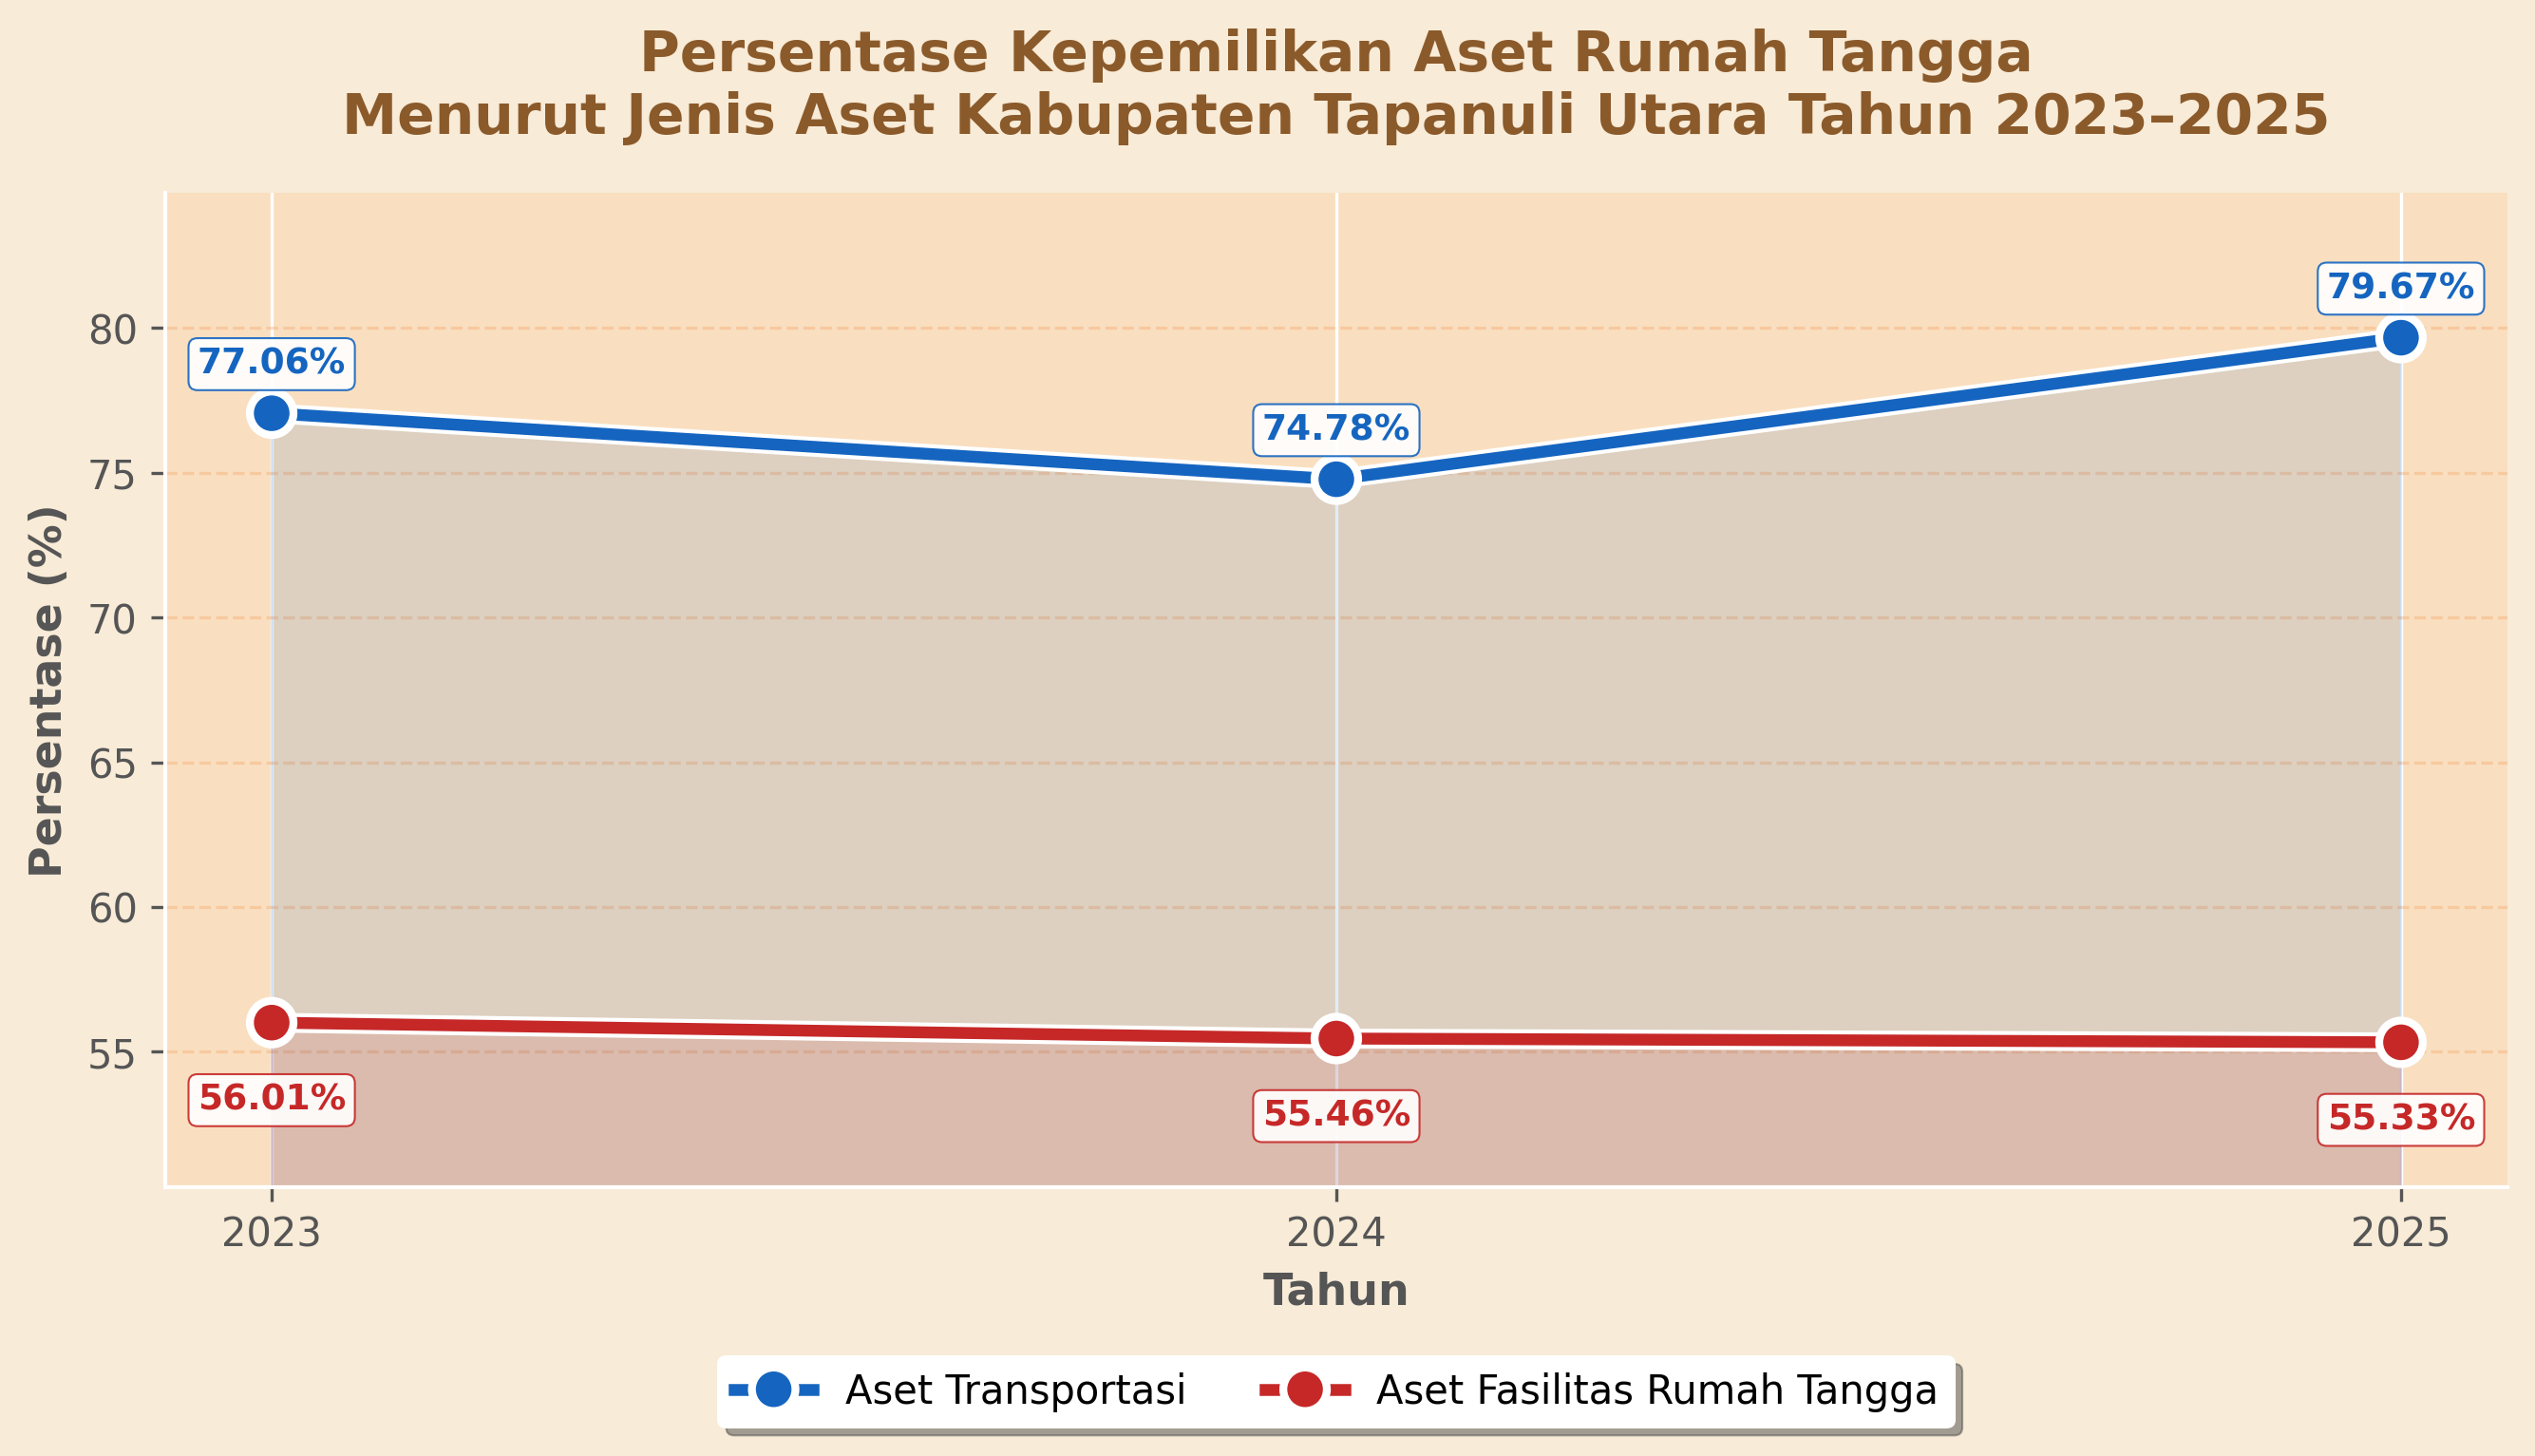

In [ ]:
df = sheets["Aset"].copy()
transportasi = df[df["Jenis Aset"]=="Aset Transportasi"].sort_values("Tahun")
fasilitas = df[df["Jenis Aset"]=="Aset Fasilitas Rumah Tangga"].sort_values("Tahun")

fig, ax = plt.subplots(figsize=(9,5.3), dpi=300)
fig.patch.set_facecolor("#F8EBD7")
ax.set_facecolor("#F9DFC0")

biru = "#1565C0"
merah = "#C62828"
judul = "#8B5A2B"

line1, = ax.plot(
    transportasi["Tahun"],
    transportasi["Persentase Rumah Tangga"],
    color=biru,
    linewidth=3,
    marker="o",
    markersize=8,
    label="Aset Transportasi"
)

line2, = ax.plot(
    fasilitas["Tahun"],
    fasilitas["Persentase Rumah Tangga"],
    color=merah,
    linewidth=3,
    marker="o",
    markersize=8,
    label="Aset Fasilitas Rumah Tangga"
)

for line in [line1, line2]:
    line.set_path_effects([
        pe.Stroke(linewidth=5, foreground="white"),
        pe.Normal()
    ])

ax.fill_between(
    transportasi["Tahun"],
    transportasi["Persentase Rumah Tangga"],
    color=biru,
    alpha=0.12
)

ax.fill_between(
    fasilitas["Tahun"],
    fasilitas["Persentase Rumah Tangga"],
    color=merah,
    alpha=0.12
)

for x, y in zip(
    transportasi["Tahun"],
    transportasi["Persentase Rumah Tangga"]
):
    ax.annotate(
        f"{y:.2f}%",
        (x, y),
        xytext=(0,10),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold",
        color=biru,
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor="white",
            edgecolor=biru,
            alpha=0.9
        )
    )

for x, y in zip(
    fasilitas["Tahun"],
    fasilitas["Persentase Rumah Tangga"]
):
    ax.annotate(
        f"{y:.2f}%",
        (x, y),
        xytext=(0,-22),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold",
        color=merah,
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor="white",
            edgecolor=merah,
            alpha=0.9
        )
    )

ax.set_xticks([2023,2024,2025])

ax.set_xlabel(
    "Tahun",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel(
    "Persentase (%)",
    fontsize=11,
    fontweight="bold"
)

ax.set_title(
    "Persentase Kepemilikan Aset Rumah Tangga\n"
    "Menurut Jenis Aset Kabupaten Tapanuli Utara Tahun 2023–2025",
    fontsize=14,
    fontweight="bold",
    color=judul,
    pad=15
)

ymin = min(df["Persentase Rumah Tangga"]) - 5
ymax = max(df["Persentase Rumah Tangga"]) + 5
ax.set_ylim(ymin, ymax)

ax.grid(
    axis="y",
    linestyle="--",
    color="#F4A261",
    alpha=0.35
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

legend = ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5,-0.15),
    ncol=2,
    frameon=True,
    fancybox=True,
    shadow=True,
    fontsize=10
)

legend.get_frame().set_facecolor("white")
legend.get_frame().set_edgecolor("white")

plt.tight_layout()
plt.show()

### **VISUALISASI 8: Komposisi Persentase Pengeluaran Rumah Tangga Menurut Kelompok Pengeluaran Kabupaten Tapanuli Utara Tahun 2023–2025**

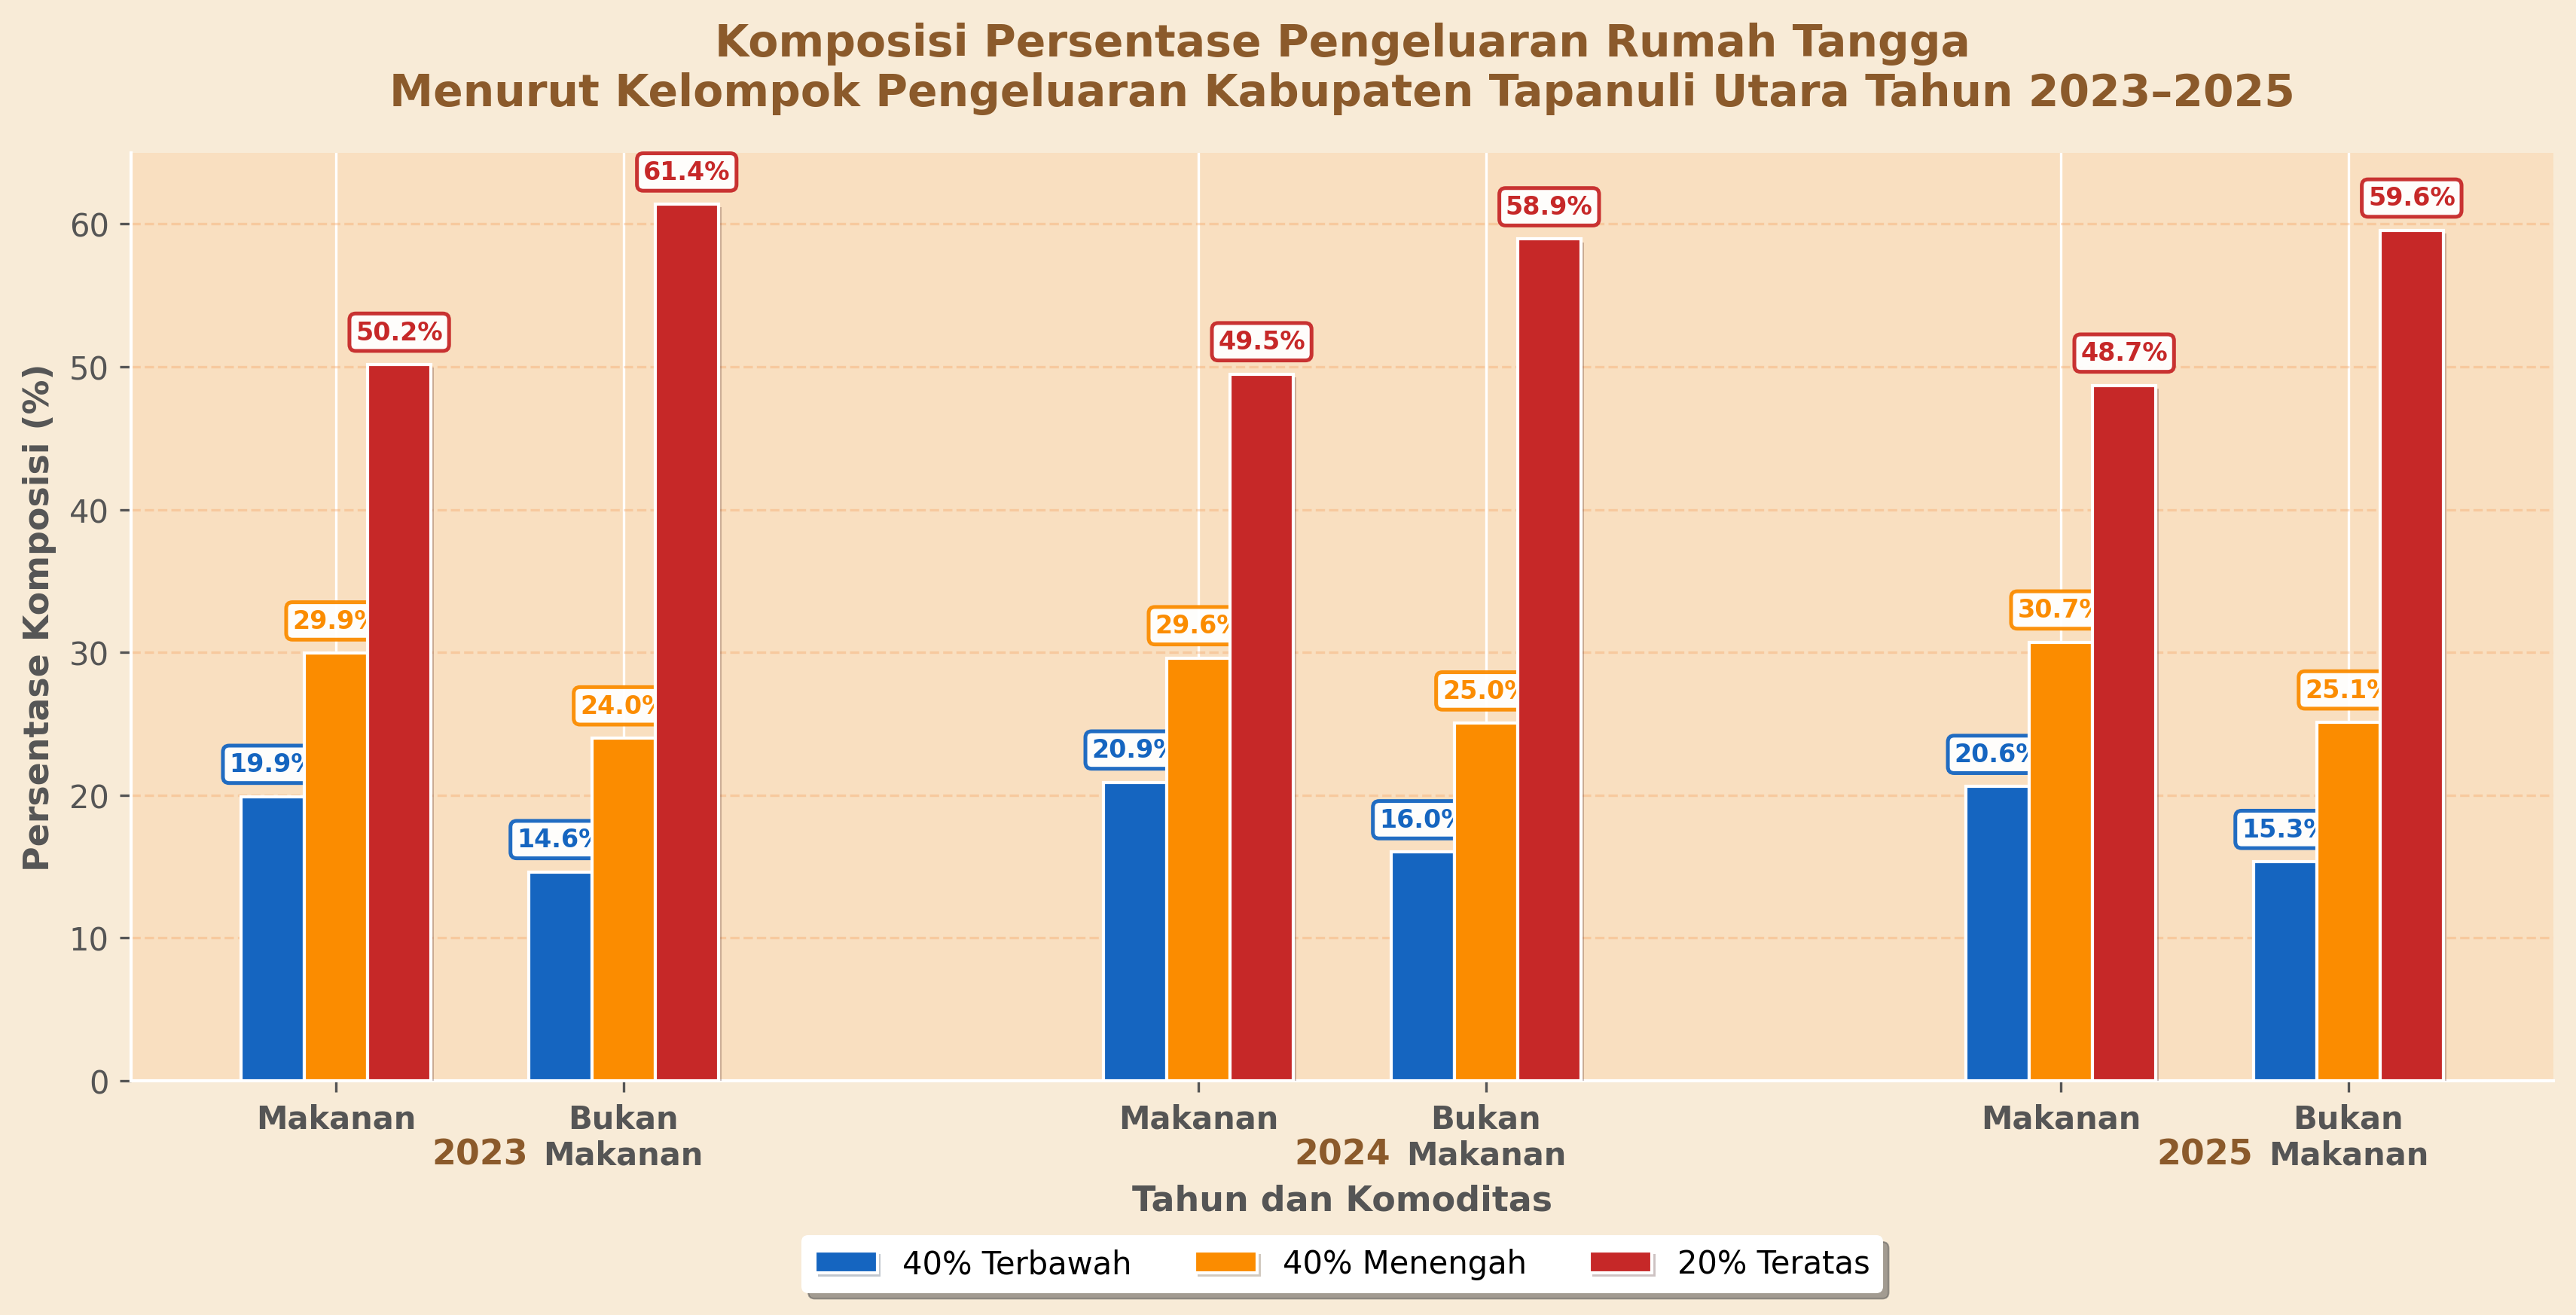

In [ ]:
df = sheets["Pengeluaran"].copy()
df = df[df["Komoditas"].isin(["Jumlah Makanan", "Jumlah Bukan Makanan"
])].copy()

kelompok = ["40% Terbawah", "40% Menengah", "20% Teratas"]
df["Jumlah"] = df[kelompok].sum(axis=1)

for k in kelompok:
    df[k] = (df[k] / df["Jumlah"]) * 100

tahun = [2023, 2024, 2025]
warna = ["#1565C0", "#FB8C00", "#C62828"]
judul = "#8B5A2B"

fig, ax = plt.subplots(figsize=(11.5,6), dpi=300)
fig.patch.set_facecolor("#F8EBD7")
ax.set_facecolor("#F9DFC0")

width = 0.22
x = np.array([
    0,1,
    3,4,
    6,7
])

labels = [
    "Makanan",
    "Bukan\nMakanan",
    "Makanan",
    "Bukan\nMakanan",
    "Makanan",
    "Bukan\nMakanan"
]

for i, k in enumerate(kelompok):
    values = []
    for t in tahun:
        temp = df[df["Tahun"] == t]

        makanan = temp[
            temp["Komoditas"] == "Jumlah Makanan"
        ][k].values[0]

        bukan = temp[
            temp["Komoditas"] == "Jumlah Bukan Makanan"
        ][k].values[0]

        values.extend([makanan, bukan])

    bars = ax.bar(
        x + (i-1)*width,
        values,
        width,
        color=warna[i],
        edgecolor="white",
        linewidth=1,
        label=k,
        zorder=3
    )

    for bar in bars:
        bar.set_path_effects([
            pe.SimplePatchShadow(offset=(1,-1), alpha=0.25),
            pe.Normal()
        ])

    for bar in bars:

        ax.annotate(
            f"{bar.get_height():.1f}%",
            (
                bar.get_x()+bar.get_width()/2,
                bar.get_height()
            ),
            xytext=(0,8),
            textcoords="offset points",
            ha="center",
            fontsize=8,
            fontweight="bold",
            color=warna[i],
            bbox=dict(
                boxstyle="round,pad=0.25",
                facecolor="white",
                edgecolor=warna[i],
                linewidth=1.2,
                alpha=0.95
            )
        )

ax.set_xticks(x)

ax.set_xticklabels(
    labels,
    fontsize=10,
    fontweight="bold"
)

centers = [0.5, 3.5, 6.5]
for c, t in zip(centers, tahun):

    ax.text(
        c,
        -0.09,
        str(t),
        transform=ax.get_xaxis_transform(),
        ha="center",
        fontsize=11,
        fontweight="bold",
        color=judul
    )

ax.set_title(
    "Komposisi Persentase Pengeluaran Rumah Tangga\n"
    "Menurut Kelompok Pengeluaran Kabupaten Tapanuli Utara Tahun 2023–2025",
    fontsize=14,
    fontweight="bold",
    color=judul,
    pad=15
)

ax.set_xlabel(
    "Tahun dan Komoditas",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel(
    "Persentase Komposisi (%)",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylim(0,65)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.35,
    color="#F4A261"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

legend = ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5,-0.15),
    ncol=3,
    frameon=True,
    fancybox=True,
    shadow=True,
    fontsize=10
)

legend.get_frame().set_facecolor("white")
legend.get_frame().set_edgecolor("white")

plt.tight_layout()
plt.show()